# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (lysosome, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [38]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## Load nucleus feature data
Load in nuclei feature data merged with metadata

In [39]:
uoe5_nucleus_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_output.parquet"
df = pd.read_parquet(uoe5_nucleus_output_fn)

df["Batch"] = df["Batch"].astype("Int64").astype(str)  # Int64 first handles any NaN

print(df.head())
print(df.columns.tolist())

   label     area  intensity_mean  intensity_max  intensity_min  \
0      1   4939.0     3642.956266         6248.0         1735.0   
1      2   9671.0     6493.838693        27547.0         1174.0   
2      3   6054.0     4234.435580        10726.0          883.0   
3      4   8794.0      960.669093         1456.0          608.0   
4      5  12435.0     4042.183353        13133.0         1411.0   

   intensity_std   centroid-0   centroid-1  eccentricity  solidity  ...  \
0     891.057838    24.399069  1195.013768      0.842756  0.983277  ...   
1    3302.626429   409.897839  1343.616379      0.729209  0.970302  ...   
2    1676.650264   796.202346   620.880410      0.661181  0.967247  ...   
3     197.895244   964.316579    67.486354      0.575190  0.969036  ...   
4    1584.921888  1000.838118   721.246321      0.713834  0.961122  ...   

   Variant  Genotype  Gene_Var_Type  Cell_Line_Info  Source Asp PosID AbPanel  \
0     None      None       KOLF2.1J            None  manual      

In [40]:
print(f"Total number of images: {df[['filename', 'Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of nuclei (before QC): {len(df)}")
print(f"Total number of nuclei (after QC): {len(df[df['selected'] == True])}")

Total number of images: 204887
Total number of nuclei (before QC): 2071389
Total number of nuclei (after QC): 1046112


## Nucleus summary data

In [41]:
group_cols = ["iNDI_Plate_ID", "Source", "Gene_Var_Type"]

before = (
    df.groupby(group_cols)
      .agg(images_before=("image_name", "nunique"),
           wells_before=("Well_ID", "nunique"),
           nuclei_before=("image_name", "size"))
)

after = (
    df[df["selected"]]
      .groupby(group_cols)
      .agg(images_after=("image_name", "nunique"),
           wells_after=("Well_ID", "nunique"),
           nuclei_after=("image_name", "size"))
)

summary = (
    before.join(after, how="left")
          .fillna({"images_after": 0, "wells_after": 0, "nuclei_after": 0})
          .astype({"images_after": int, "wells_after": int, "nuclei_after": int})
          .reset_index()
)

# reorder for readability
summary = summary[[
    "iNDI_Plate_ID", "Source", "Gene_Var_Type",
    "wells_before", "wells_after",
    "images_before", "images_after",
    "nuclei_before", "nuclei_after",
]]

# print grouped by plate + source
for (plate, source), grp in summary.groupby(["iNDI_Plate_ID", "Source"]):
    print(f"\n=== iNDI_Plate_ID: {plate} ({source}) ===")
    print(grp.drop(columns=["iNDI_Plate_ID", "Source"]).to_string(index=False))

# summary.to_csv(
#     "/data/kelpschdj/iNDI/Production/outputs/filtering_summary.csv",
#     index=False,
# )
print("Wrote filtering_summary.csv")


=== iNDI_Plate_ID: INDI00002D (automated) ===
    Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after
 FUS_R495X_REV/WT            48           48           1644          1605          13039          7622
FUS_R495X_SNV/SNV            48           48           1643          1605          14567          7740
 FUS_R495X_SNV/WT            48           48           1666          1644          16749          9176
         KOLF2.1J            96           96           3335          3307          36582         20098
 VCP_R159H_REV/WT            48           48           1367          1250           4540          3134
VCP_R159H_SNV/SNV            48           48           1665          1658          18279         10294
 VCP_R159H_SNV/WT            48           48           1626          1619          20371         10820

=== iNDI_Plate_ID: INDI00007D (automated) ===
       Gene_Var_Type  wells_before  wells_after  images_before  images_after  nucl

In [42]:
df = df[df["selected"]]

# Primary analysis
## ROI level data
### Feature assessment
Broad assessment of nuclei features before PCA

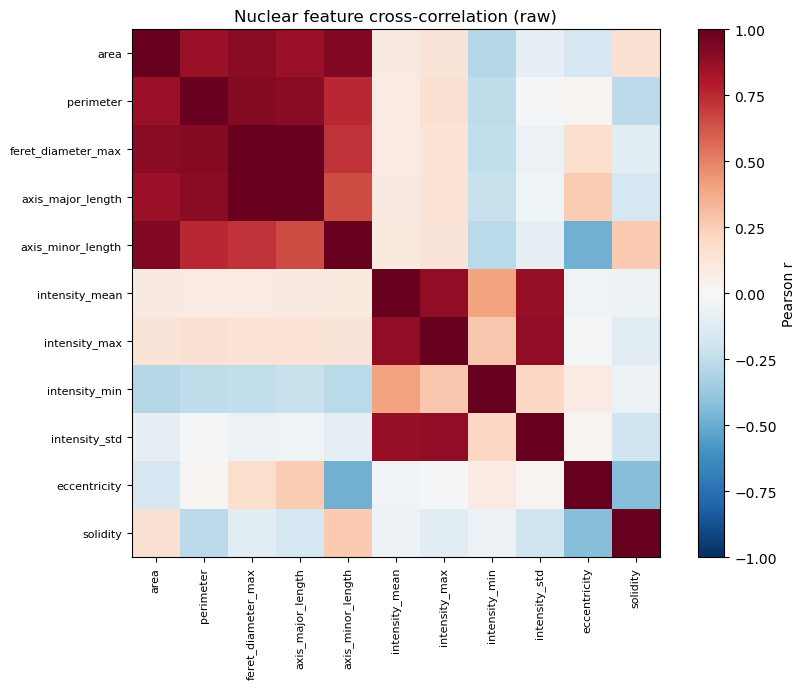

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.926  area                   axis_minor_length
  +0.918  perimeter              feret_diameter_max
  +0.905  area                   feret_diameter_max

Using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ---------------------------------------------------------------
# STEP 0 — candidate nuclear features (regionprops from script 1)
# ---------------------------------------------------------------
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c in df.columns]

# ---------------------------------------------------------------
# STEP 1 — cross-correlation (raw, pre-scaling)
# ---------------------------------------------------------------
X_all = df[CANDIDATE_FEATURES].replace([np.inf, -np.inf], np.nan)
corr = X_all.corr(method="pearson")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, rotation=90, fontsize=8)
plt.yticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, fontsize=8)
plt.colorbar(im, label="Pearson r")
plt.title("Nuclear feature cross-correlation (raw)")
plt.tight_layout(); plt.show()

hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(CANDIDATE_FEATURES)
    for b in CANDIDATE_FEATURES[i + 1:]
    if hi.loc[a, b]
]
print("Highly correlated pairs (|r| > 0.9):")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {r:+.3f}  {a:22s} {b}")

# ---------------------------------------------------------------
# STEP 2 — pruned FEATURES
# ---------------------------------------------------------------
df["aspect_ratio"] = df["axis_minor_length"] / df["axis_major_length"]

FEATURES = [
    "area",
    "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]
FEATURES = [c for c in FEATURES if c in df.columns]
print("\nUsing FEATURES:", FEATURES)

### PCA loadings

Dropped 0 rows with NaN/inf; 1046112 remain


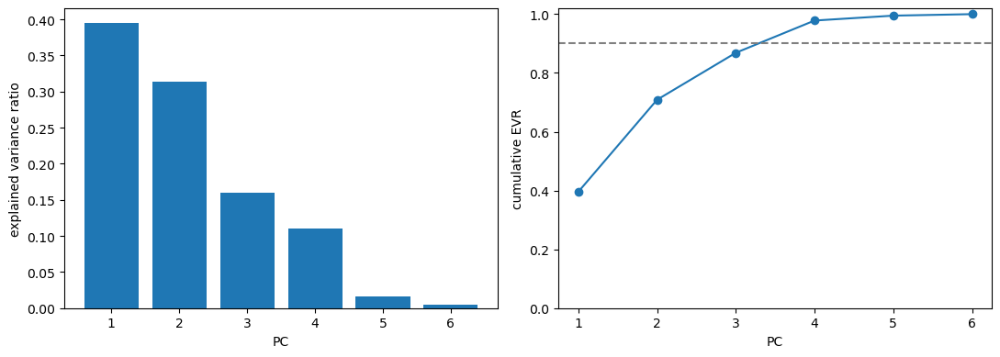

EVR: [0.396 0.313 0.16  0.11  0.017 0.005]
cumulative: [0.396 0.709 0.869 0.978 0.995 1.   ]
                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.201  0.053  0.961 -0.139  0.119  0.015
intensity_mean -0.085  0.697  0.087  0.153 -0.690 -0.010
intensity_std  -0.167  0.683 -0.086  0.026  0.705  0.015
eccentricity   -0.593 -0.155  0.171  0.340  0.003  0.692
solidity        0.451 -0.033  0.023  0.883  0.111 -0.060
aspect_ratio    0.607  0.141 -0.179 -0.249 -0.021  0.719


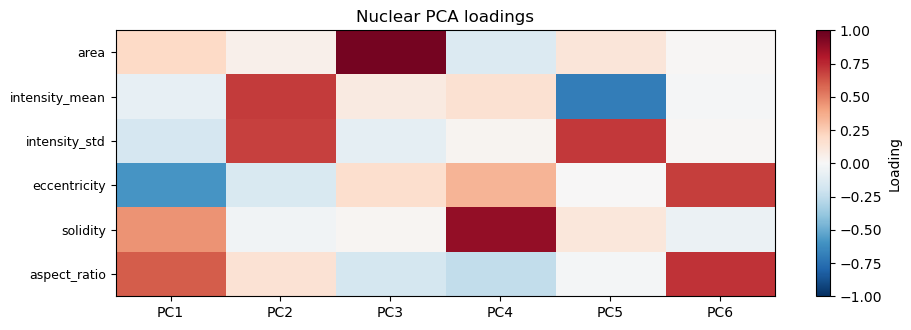

In [44]:
# ---------------------------------------------------------------
# NaN/inf handling
# ---------------------------------------------------------------
before = len(df)
X_df = df[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
df = df[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with NaN/inf; {len(df)} remain")

# ---------------------------------------------------------------
# scale + PCA
# ---------------------------------------------------------------
X = StandardScaler().fit_transform(X_df.values)
pca = PCA(n_components=len(FEATURES))
scores = pca.fit_transform(X)
for i in range(scores.shape[1]):
    df[f"PC{i+1}"] = scores[:, i]

# scree
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev) + 1), ev)
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print("EVR:", ev.round(3))
print("cumulative:", np.cumsum(ev).round(3))

# loadings
loadings = pd.DataFrame(
    pca.components_.T, index=FEATURES,
    columns=[f"PC{i+1}" for i in range(len(FEATURES))],
)
print(loadings.round(3))

n_show = min(6, len(FEATURES))
plt.figure(figsize=(1.6 * n_show, 0.4 * len(FEATURES) + 1))
im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=9)
plt.colorbar(im, label="Loading")
plt.title("Nuclear PCA loadings")
plt.tight_layout(); plt.show()

### PCA plots
Assessment of ROI level data for nucleus features

21 plates in this run:
['INDI00002D', 'INDI00007D', 'INDI00011D', 'INDI00015D', 'INDI00019D', 'INDI00023D', 'INDI00026D', 'INDI00035D', 'INDI00039D', 'INDI00043D', 'INDI00047D', 'INDI00049D', 'INDI00053D', 'INDIEC006', 'INDIEC007', 'INDIEL001', 'INDIEL002', 'INDIEL003', 'INDIMS004', 'INDIMS005', 'INDIRK008']
All 21 plates have a color.


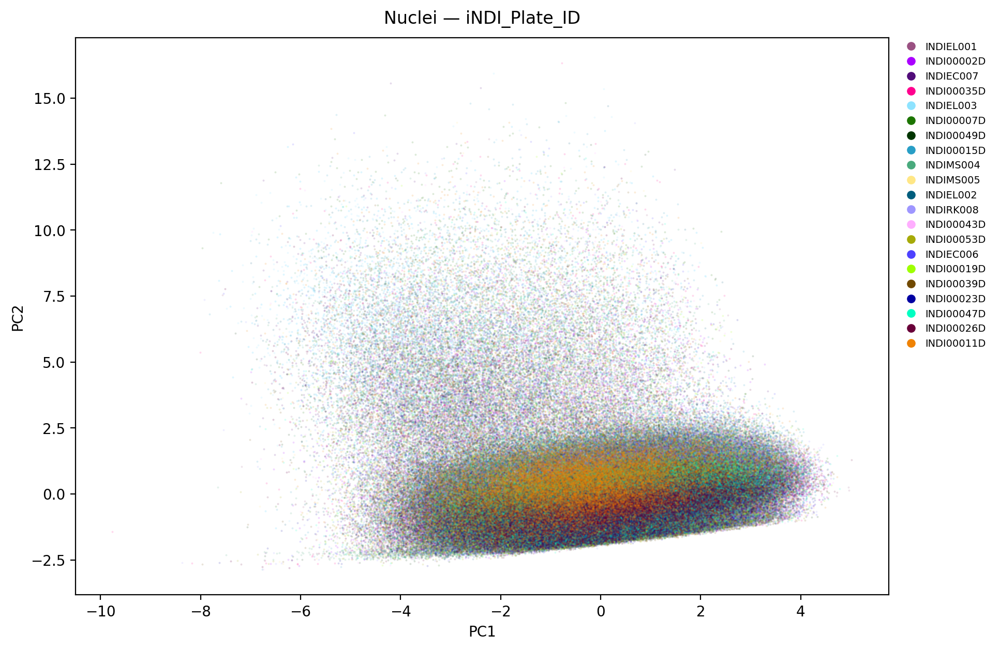

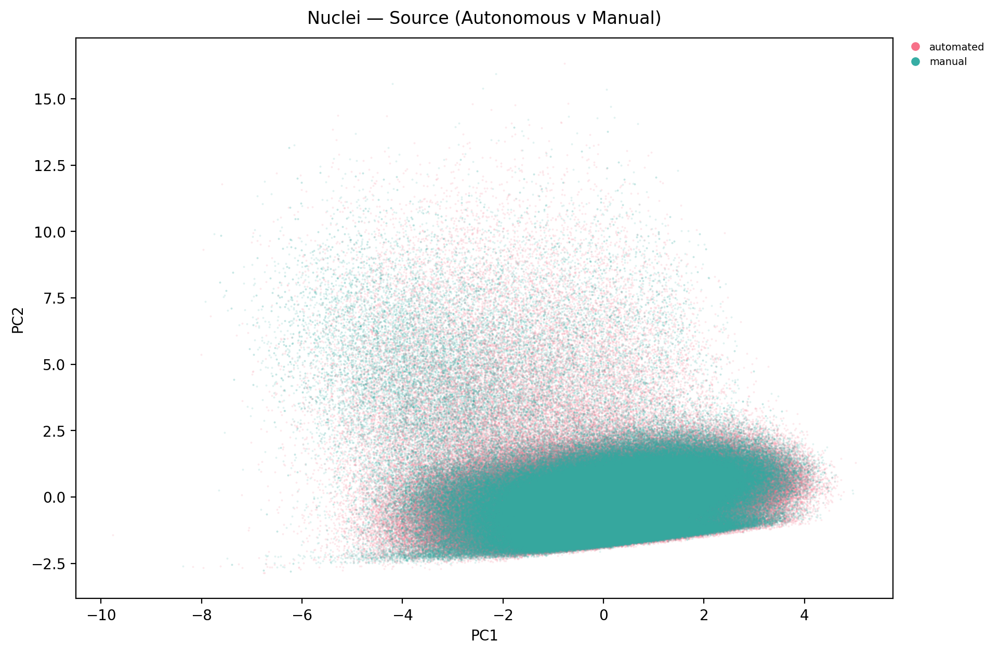

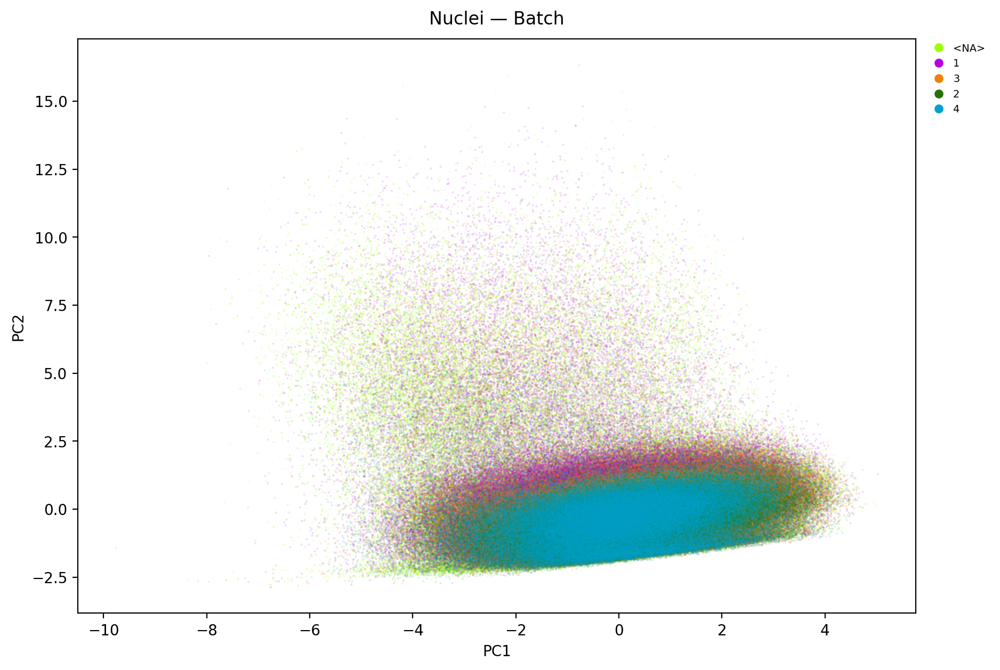

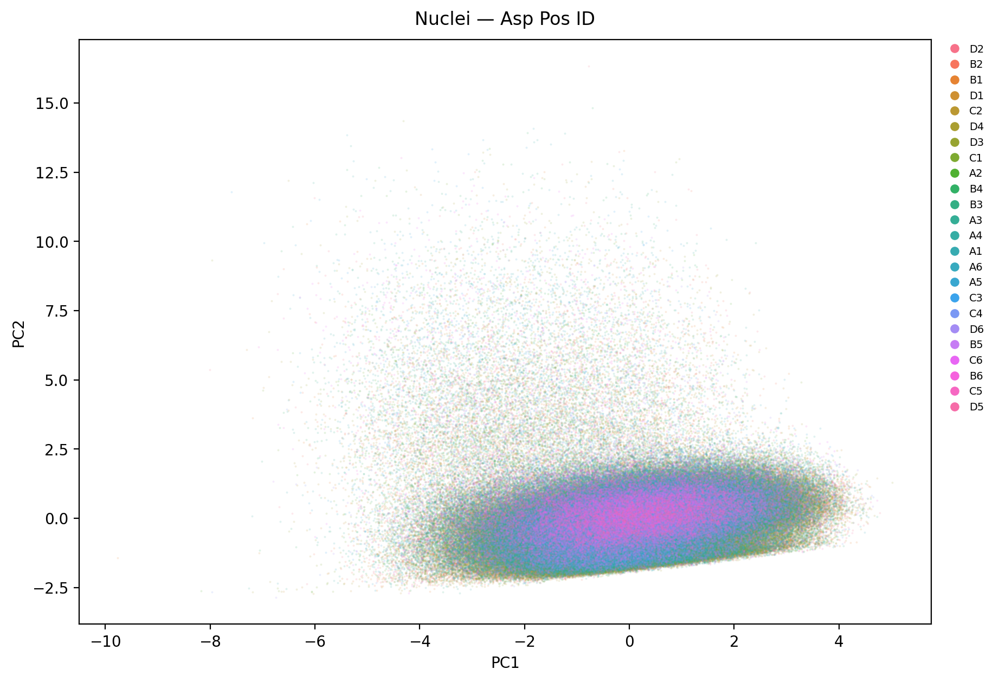

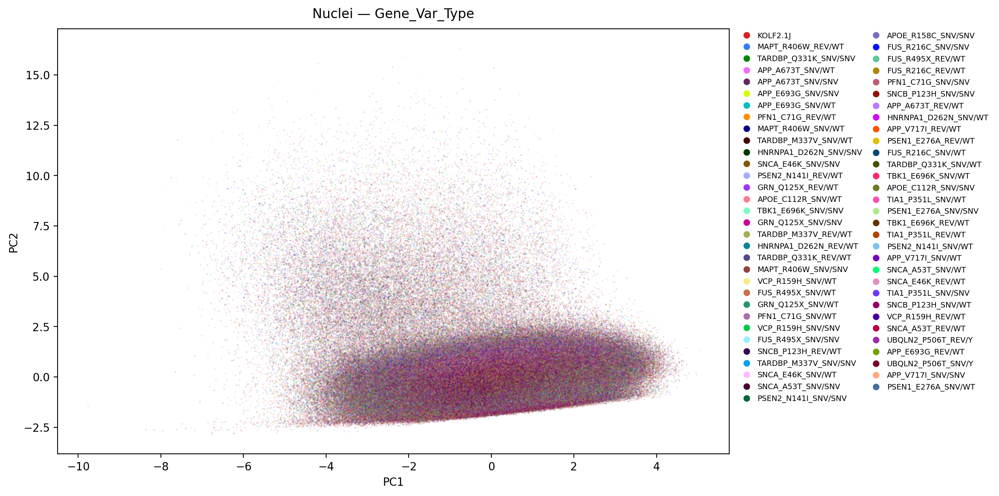

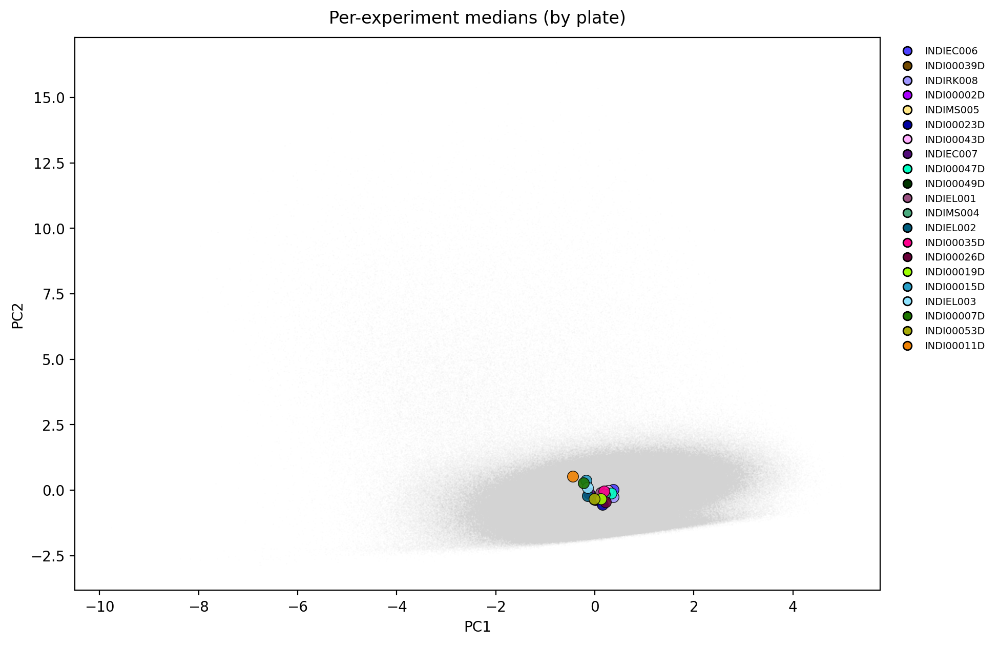

Std of per-experiment centroids (batch magnitude):
PC1    0.218
PC2    0.272
PC3    0.207
dtype: float64


In [45]:
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey

import glasbey
from matplotlib.colors import ListedColormap

# derive plate list from the data, not a hardcoded set
unique_plate_ids = sorted(df["iNDI_Plate_ID"].dropna().unique())
print(f"{len(unique_plate_ids)} plates in this run:")
print(unique_plate_ids)

plate_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_plate_ids), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
colors_plates = [ListedColormap(plate_palette_raw)(i)
                 for i in range(len(plate_palette_raw))]
plate_palette = {pid: colors_plates[i] for i, pid in enumerate(unique_plate_ids)}

# glasbey palette for genotypes (high-cardinality, no fixed mapping)
geno_palette_raw = glasbey.create_palette(
    palette_size=64, hue_bounds=(0.0, 360.0), chroma_bounds=(40, 90)
)
geno_colors = [ListedColormap(geno_palette_raw)(i)
               for i in range(len(geno_palette_raw))]

def pca_scatter(df, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = df[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(df.loc[m, pcx], df.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()

unique_batches = sorted(df["Batch"].dropna().unique())
batch_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_batches), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
batch_colors = [ListedColormap(batch_palette_raw)(i) for i in range(len(batch_palette_raw))]
batch_palette = {b: batch_colors[i] for i, b in enumerate(unique_batches)}

# guard: plates in data with no palette color
plates_in_data = set(df["iNDI_Plate_ID"].dropna().unique())
missing = plates_in_data - set(plate_palette)
print(f"[warning] plates with no color: {sorted(missing)}" if missing
      else f"All {len(plates_in_data)} plates have a color.")

df_shuf = df.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(df_shuf, "iNDI_Plate_ID", palette=plate_palette, figsize=(12, 7),
            title="Nuclei — iNDI_Plate_ID")
pca_scatter(df_shuf, "Source", figsize=(12, 7),
            title="Nuclei — Source (Autonomous v Manual)")
pca_scatter(df_shuf, "Batch", palette=batch_palette, figsize=(12, 7),
            title="Nuclei — Batch")
pca_scatter(df_shuf, "Asp PosID", figsize=(12, 7),
            title="Nuclei — Asp Pos ID")
pca_scatter(df_shuf, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
            title="Nuclei — Gene_Var_Type")

def centroid_overlay(df, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = df.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else df
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = df.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent

# per-experiment medians, colored by plate — spread = batch variation
centroid_overlay(df, color_col="iNDI_Plate_ID", group_keys=["Measurement_ID"],
                 palette=plate_palette, title="Per-experiment medians (by plate)",
                 figsize=(12, 7))

# batch magnitude: std of per-experiment centroids (no Structure split now)
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### Variance-component analysis

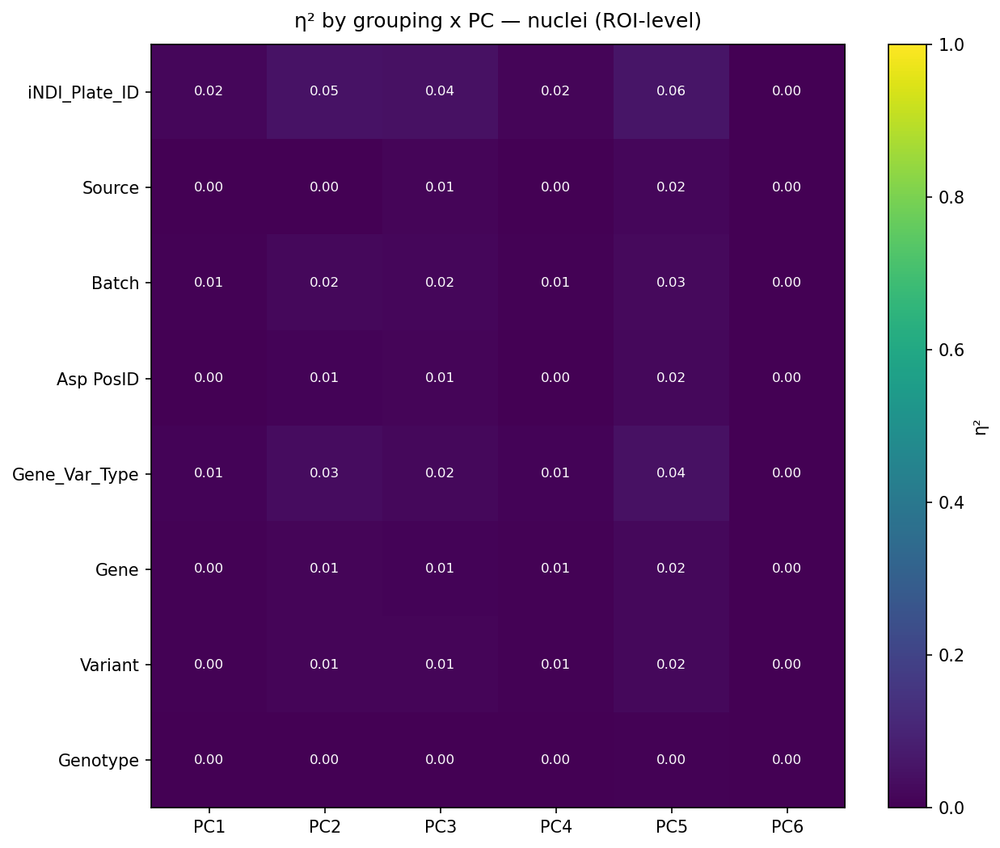

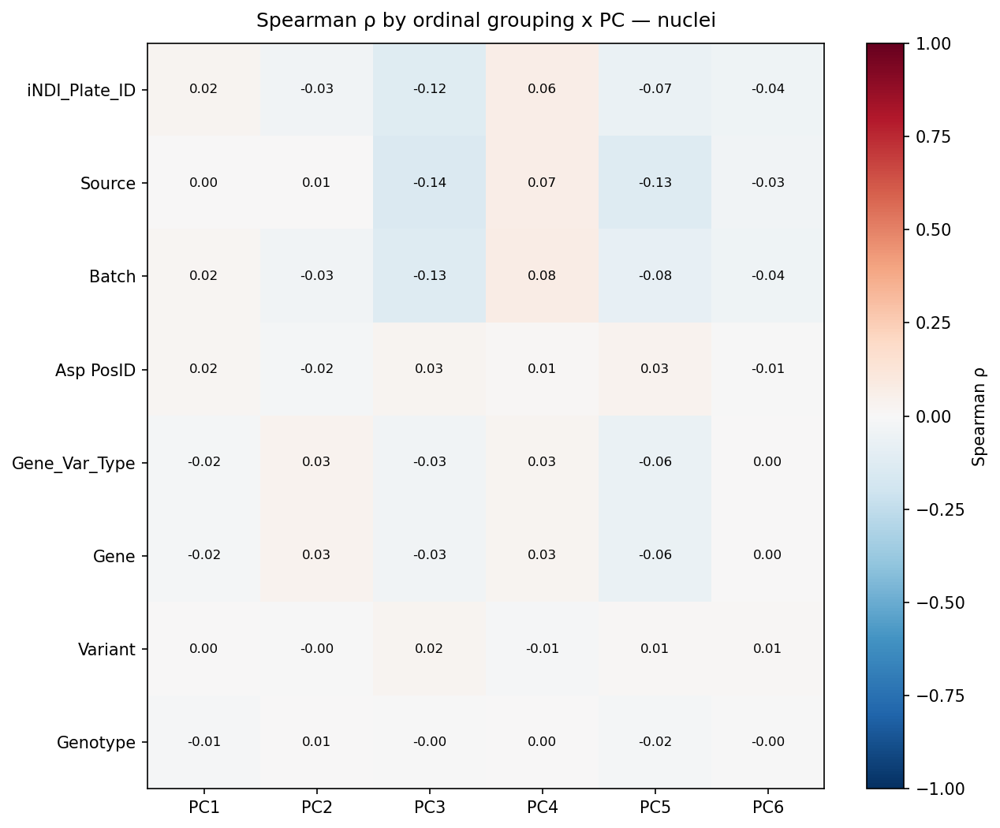

In [46]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter for nuclei:
GROUP_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=10, title="η² by grouping x PC — nuclei (ROI-level)")

from scipy.stats import spearmanr

def spearman_heatmap(data, group_cols, n_pcs=None,
                     title="Spearman ρ by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)

    for gc in group_cols:
        # ordinal code: use numeric directly if numeric, else factorize
        col = data[gc]
        if pd.api.types.is_numeric_dtype(col):
            codes = col.to_numpy(dtype=float)
        else:
            codes = pd.factorize(col, sort=True)[0].astype(float)
            codes[codes < 0] = np.nan  # NaNs come back as -1
        for pc in pc_cols:
            x = data[pc].to_numpy(dtype=float)
            m = np.isfinite(x) & np.isfinite(codes)
            if m.sum() < 3:
                mat.loc[gc, pc] = np.nan
                continue
            rho, _ = spearmanr(x[m], codes[m])
            mat.loc[gc, pc] = rho

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    # diverging map + symmetric limits since ρ ∈ [-1, 1]
    im = ax.imshow(mat.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if abs(v) > 0.5 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

ORDINAL_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
spear = spearman_heatmap(df, ORDINAL_COLS, n_pcs=10,
                         title="Spearman ρ by ordinal grouping x PC — nuclei")

[facet] 16 genes; 236718 total KOLF2.1J rows (all folded into each facet)
  APOE: 38764 variant + 236718 KOLF rows


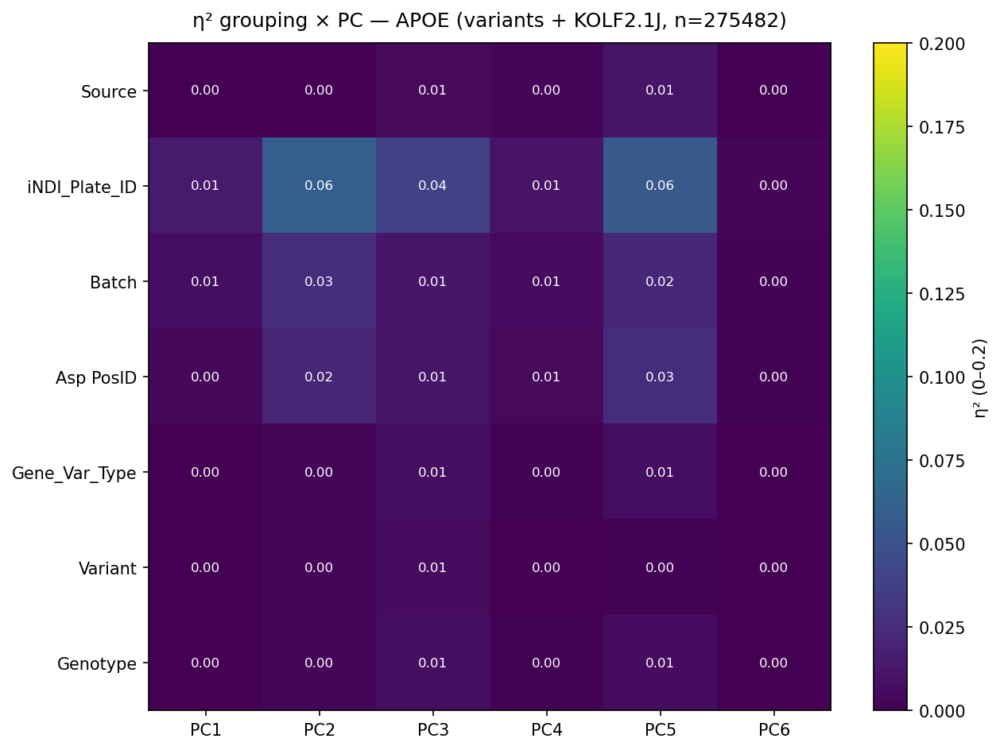

  APP: 119844 variant + 236718 KOLF rows


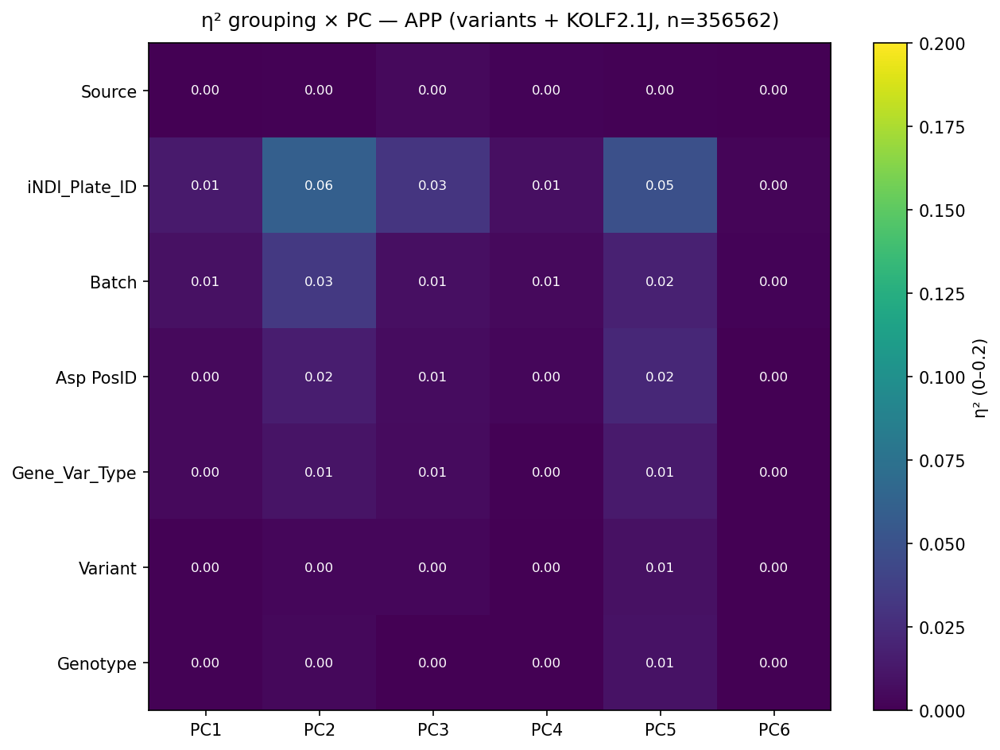

  FUS: 75312 variant + 236718 KOLF rows


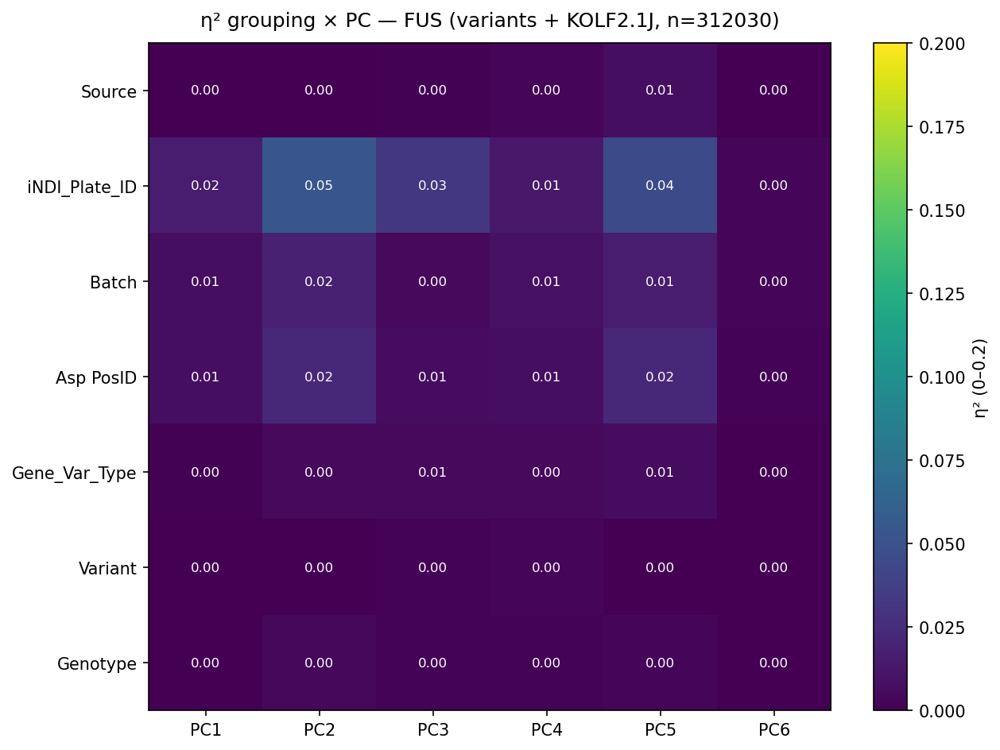

  GRN: 47400 variant + 236718 KOLF rows


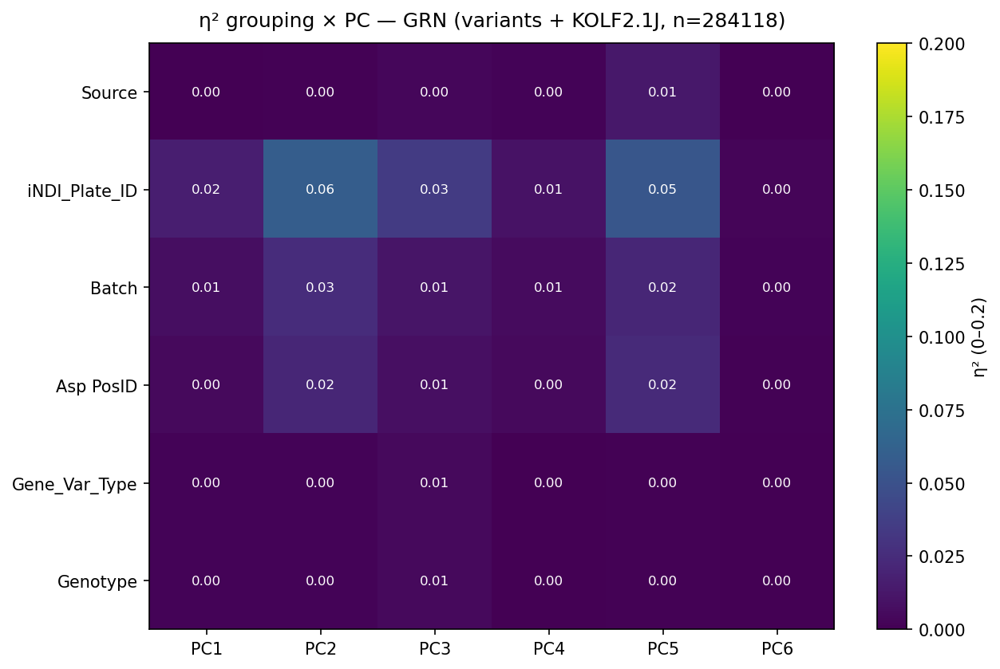

  HNRNPA1: 44838 variant + 236718 KOLF rows


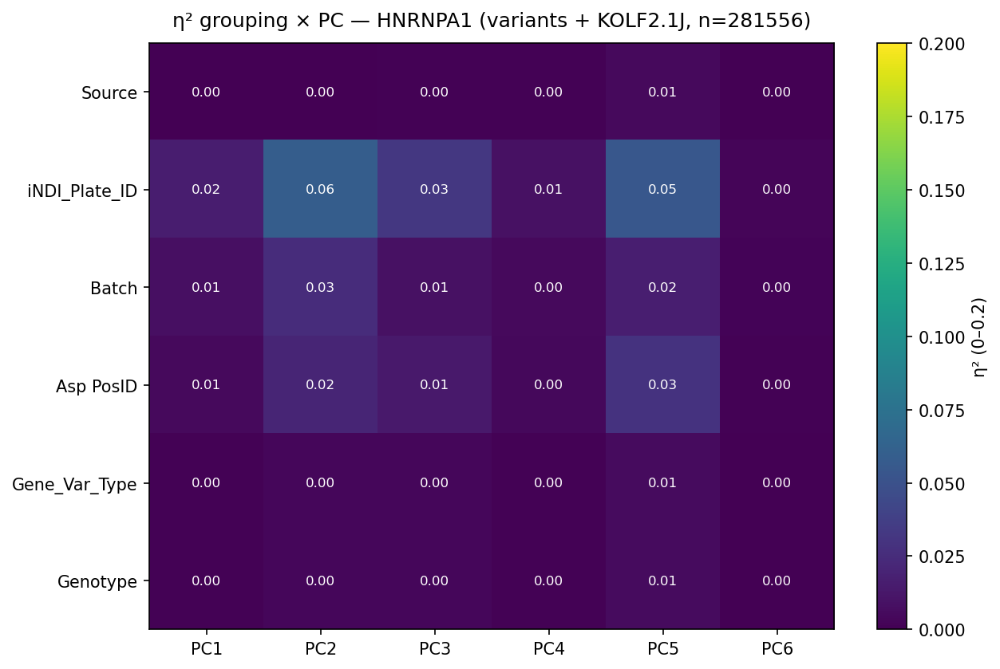

  MAPT: 59889 variant + 236718 KOLF rows


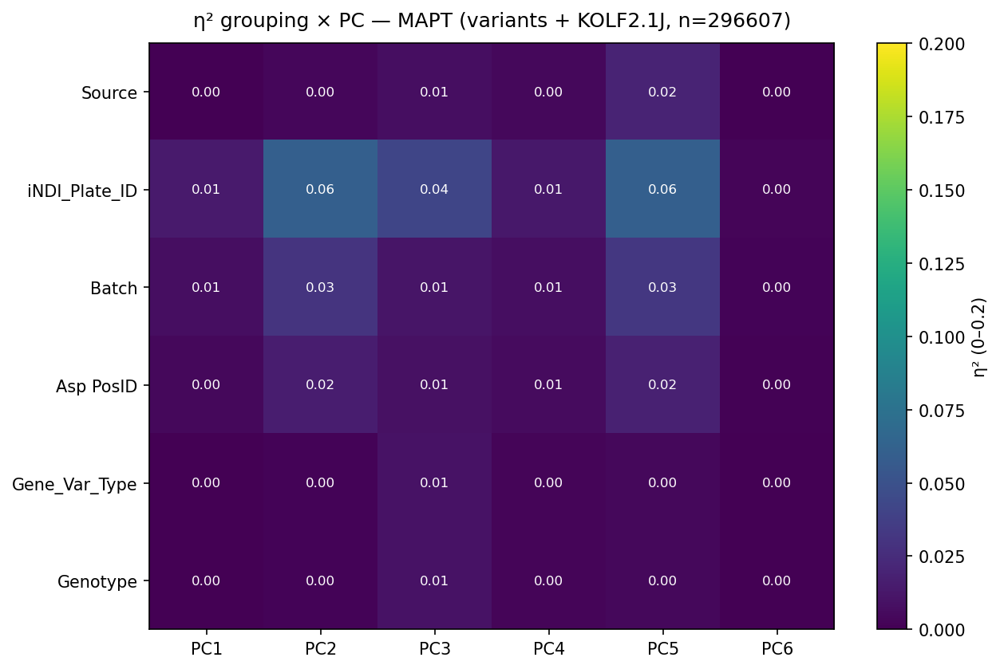

  PFN1: 44491 variant + 236718 KOLF rows


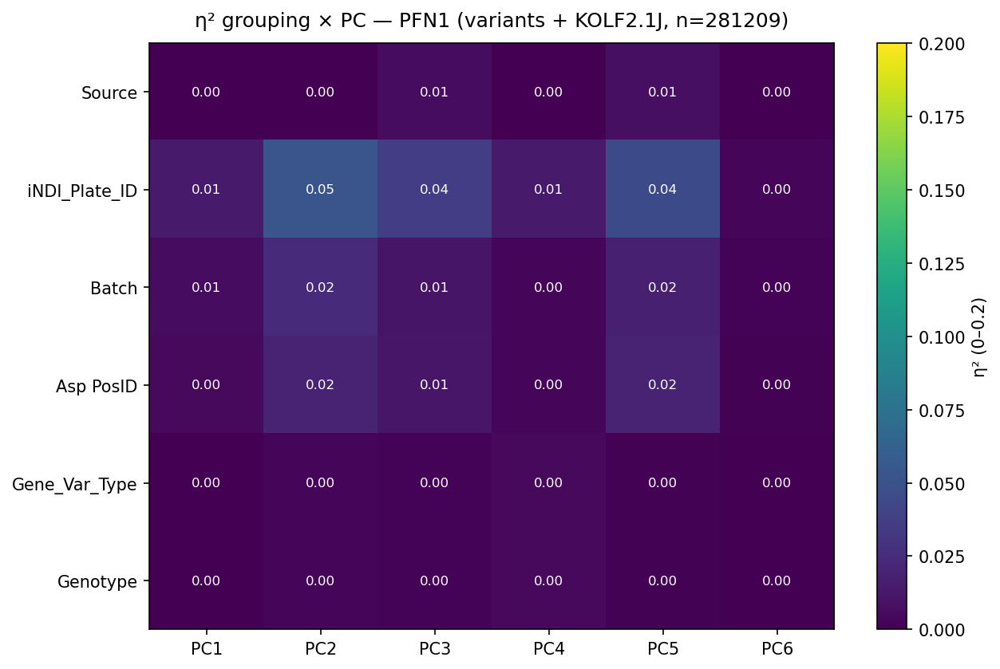

  PSEN1: 20655 variant + 236718 KOLF rows


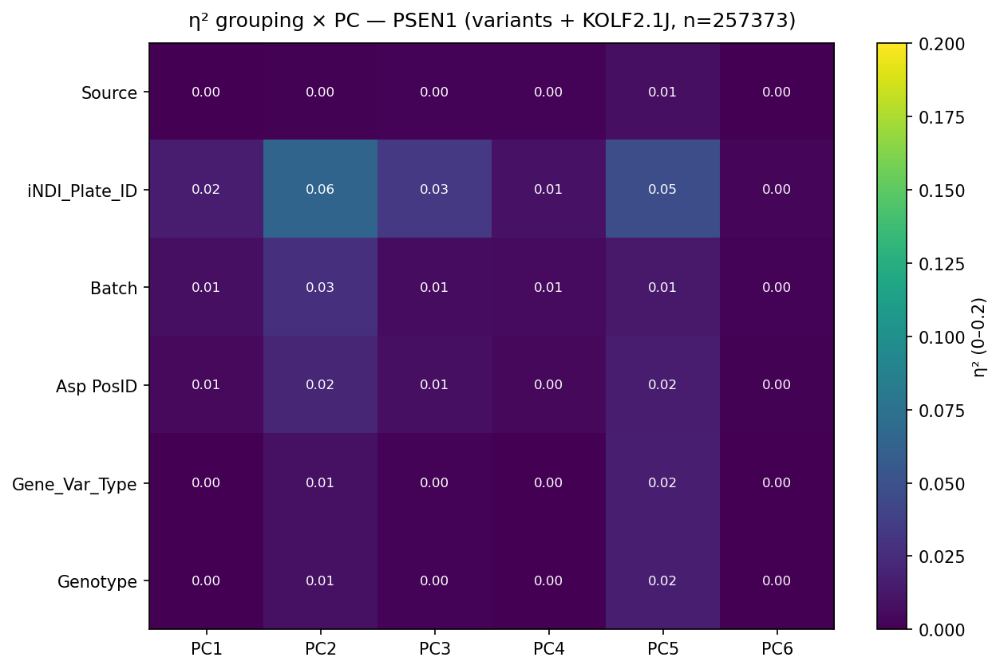

  PSEN2: 38982 variant + 236718 KOLF rows


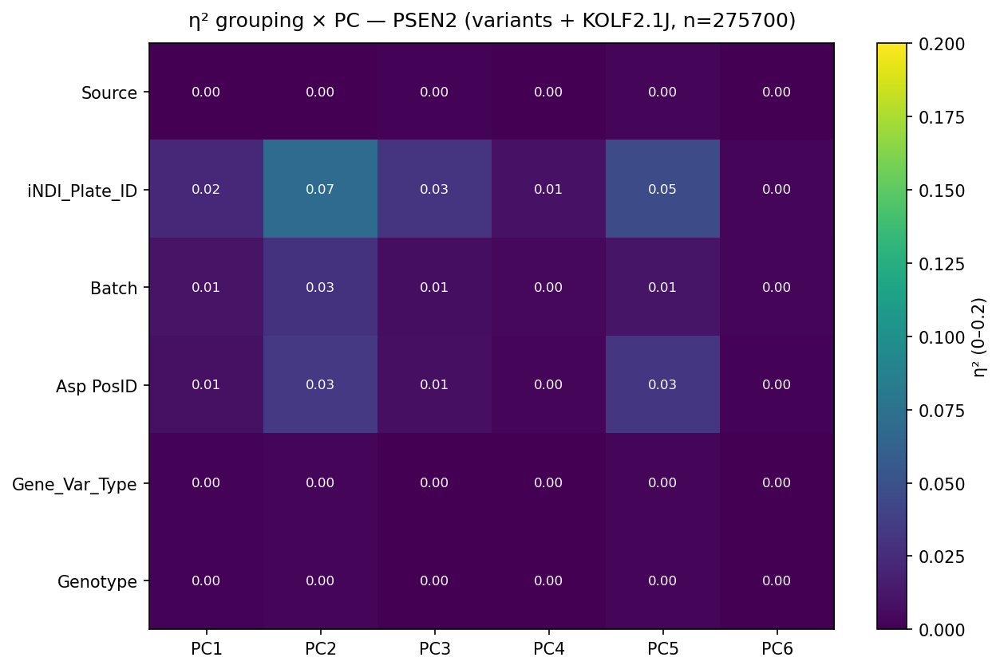

  SNCA: 68031 variant + 236718 KOLF rows


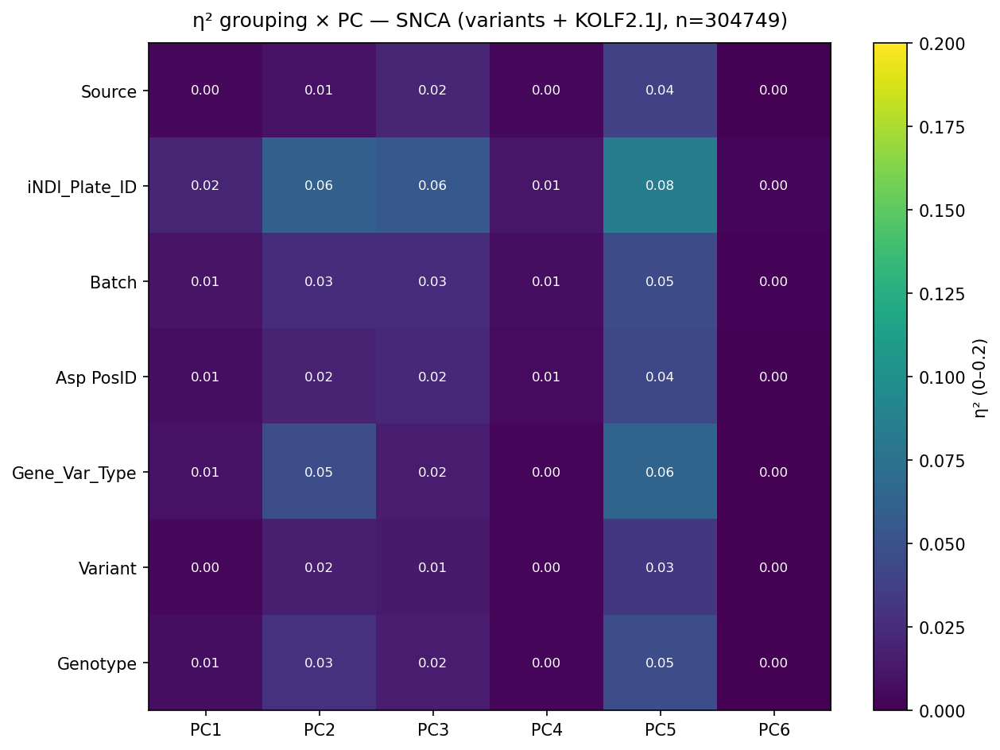

  SNCB: 32536 variant + 236718 KOLF rows


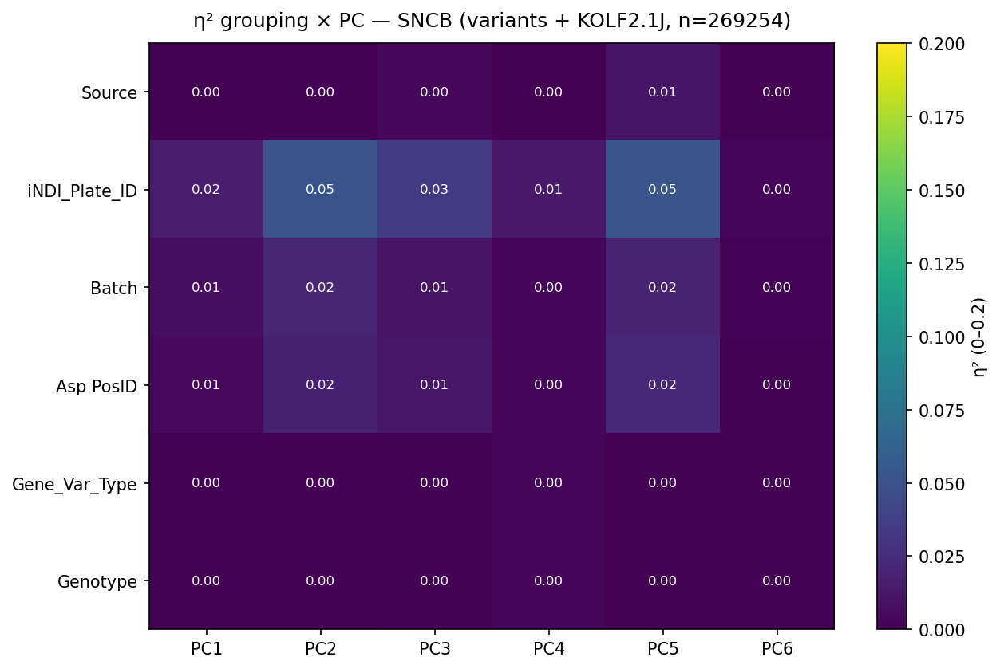

  TARDBP: 98484 variant + 236718 KOLF rows


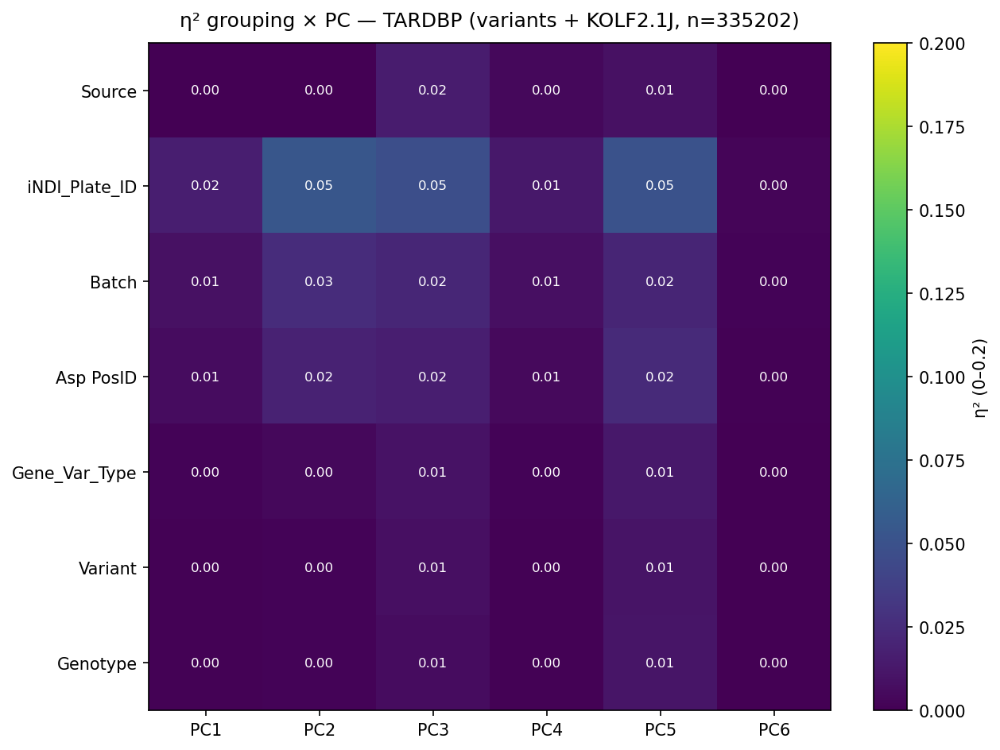

  TBK1: 35178 variant + 236718 KOLF rows


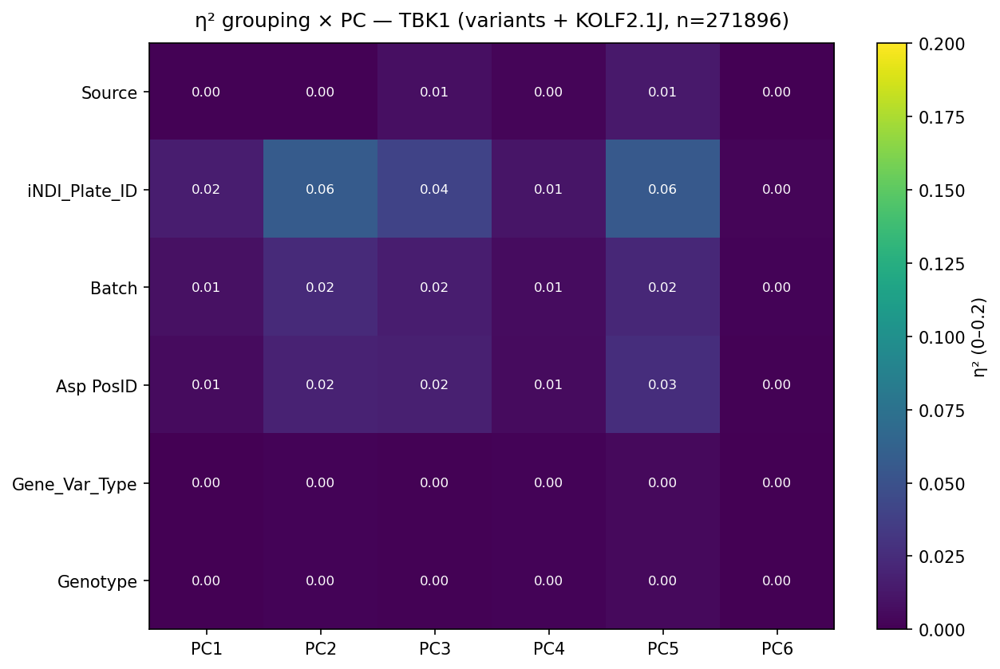

  TIA1: 26072 variant + 236718 KOLF rows


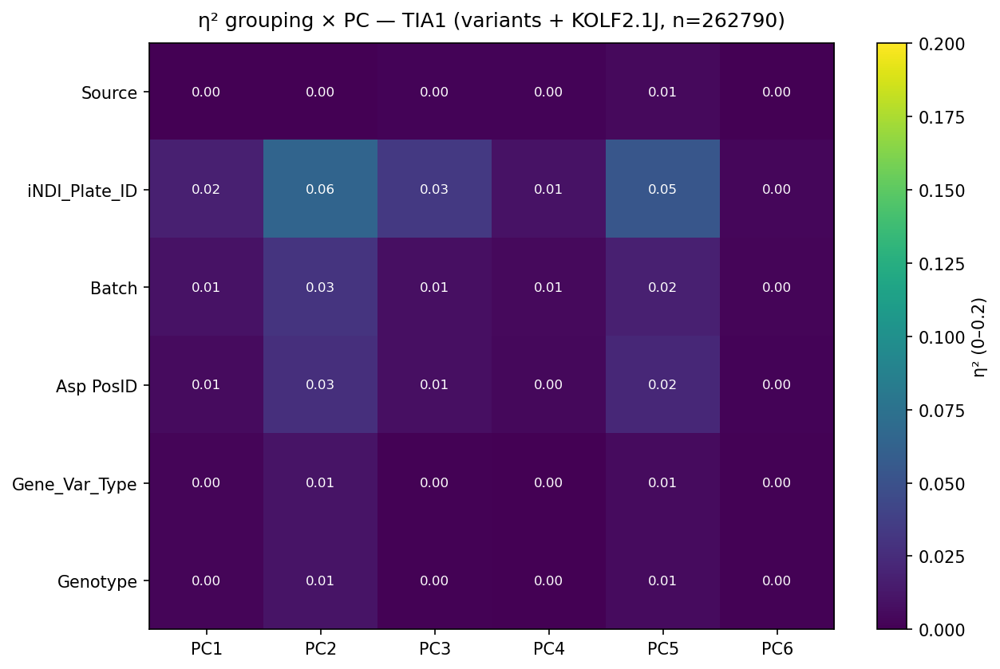

  UBQLN2: 13924 variant + 236718 KOLF rows


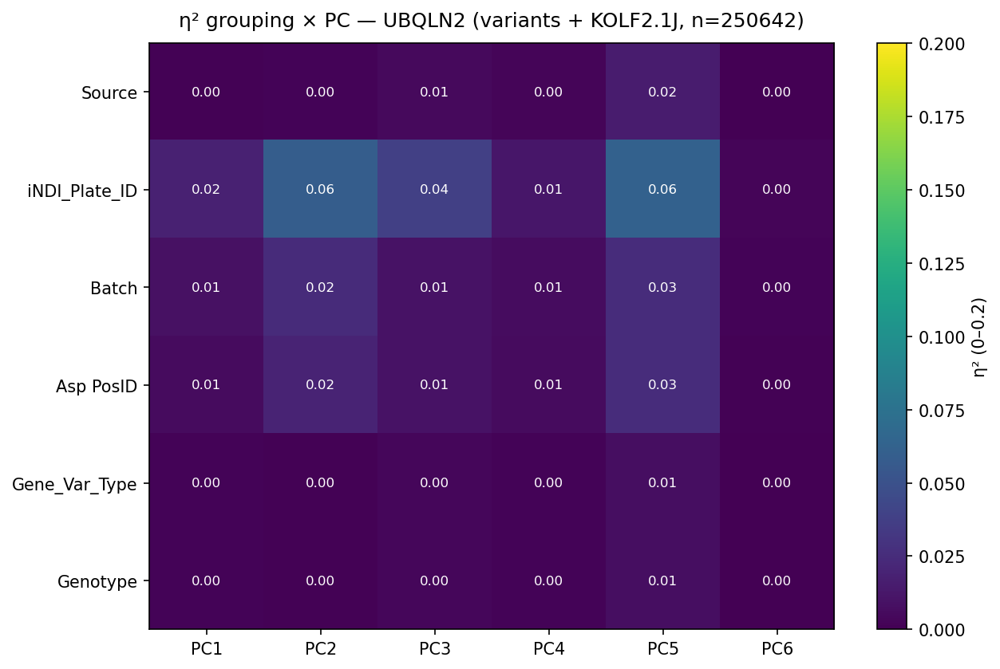

  VCP: 36700 variant + 236718 KOLF rows


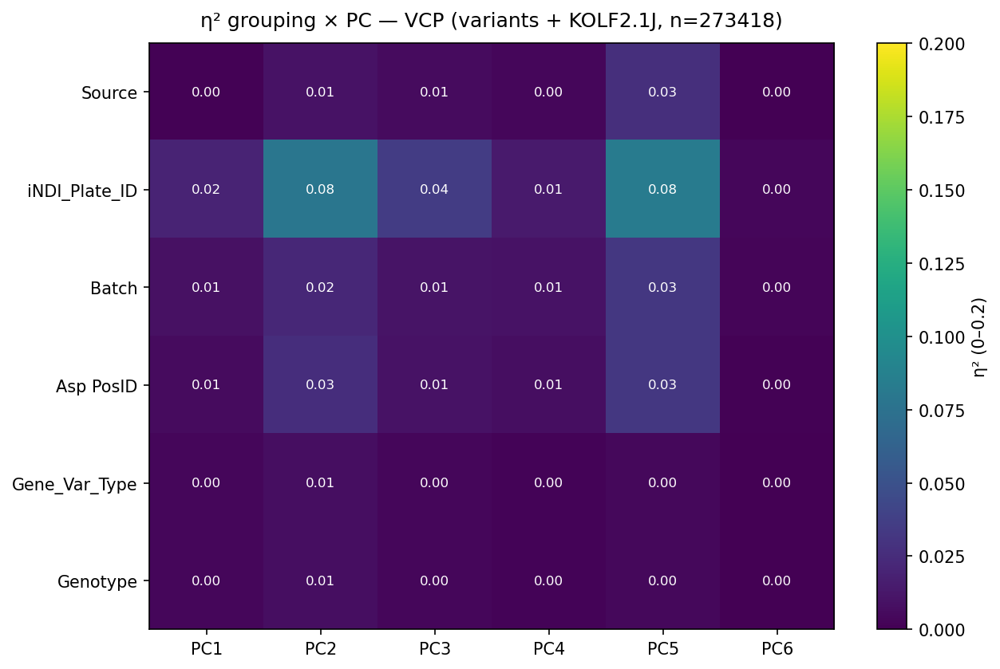

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene: ONE SEPARATE FIGURE per gene --------------------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, vmax=0.2, annot=True,
                      drop_constant=True):
    """Draw a single grouping x PC η² heatmap for one gene's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} (variants + KOLF2.1J, n={len(sub)})",
                 pad=10)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene(data, group_cols, n_pcs=10,
                  gene_col="Gene", vmax=0.2, annot=True,
                  include_wt=True, drop_constant=True,
                  plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per gene. Each gene's subset is that
    gene's variant rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that gene's variants actually occupy, removing the plate confound
    that arises when controls span all plates but a gene sits on only a few.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]
    genes = sorted(pd.unique(edited[gene_col].dropna()))
    print(f"[facet] {len(genes)} genes; {len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    facet_groups = [g for g in group_cols if g != gene_col]

    mats = {}
    for gene in genes:
        gene_rows = edited[edited[gene_col] == gene]
        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                gene_plates = set(gene_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(gene_plates)]
            sub = pd.concat([gene_rows, wt_use], ignore_index=True)
            print(f"  {gene}: {len(gene_rows)} variant + {len(wt_use)} KOLF rows"
                  f"{f' on {len(set(gene_rows[plate_col].dropna().unique()))} plate(s)' if plate_match else ''}")
        else:
            sub = gene_rows
        mats[gene] = plot_gene_heatmap(sub, facet_groups, pc_cols, gene,
                                       vmax=vmax, annot=annot,
                                       drop_constant=drop_constant)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

# recommended: aggregate to wells first (adjust well_keys to your schema)
# pc_cols = sorted([c for c in df.columns if c.startswith("PC")], key=lambda s: int(s[2:]))[:10]
# well_df = aggregate_to_wells(
#     df,
#     well_keys=["iNDI_Plate_ID", "Row", "Column"],
#     carry_cols=GROUP_COLS + ["Gene"],
#     pc_cols=pc_cols,
# )
# facet_grid_by_gene(well_df, GROUP_COLS, n_pcs=10, vmax=0.2)

# or straight on ROI-level df (noisier):
mats = facet_by_gene(df, GROUP_COLS, n_pcs=10, vmax=0.2)

## Well-level aggregation
### PCA plots

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value



Image-level: 199828 rows (13440 images)
Well-level: 6352 rows
Well-level EVR: [0.418 0.286 0.157 0.103 0.032 0.003] | cumulative: [0.418 0.704 0.861 0.964 0.997 1.   ]


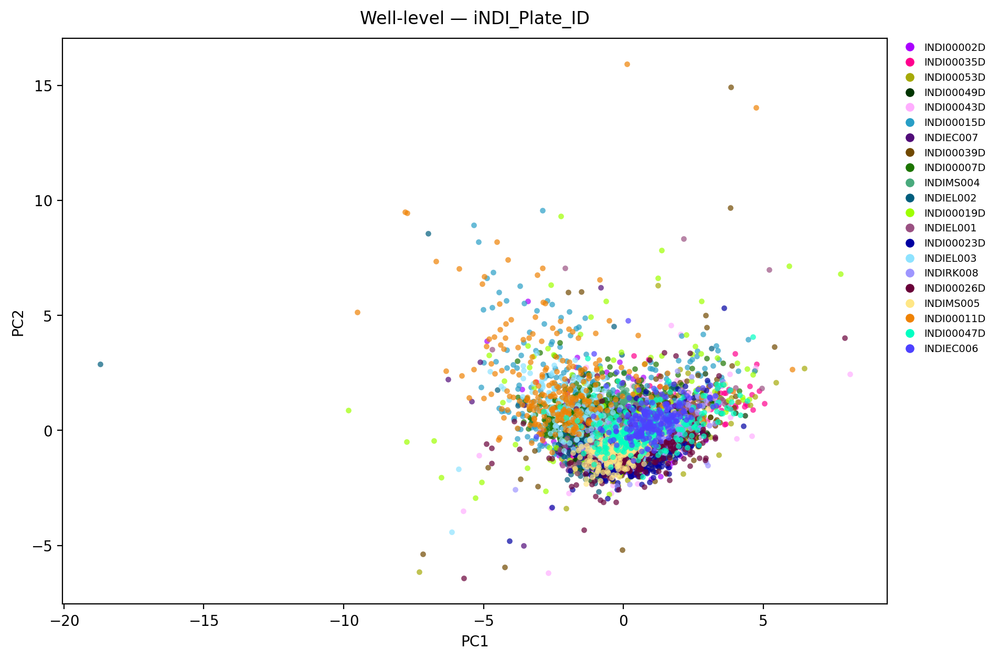

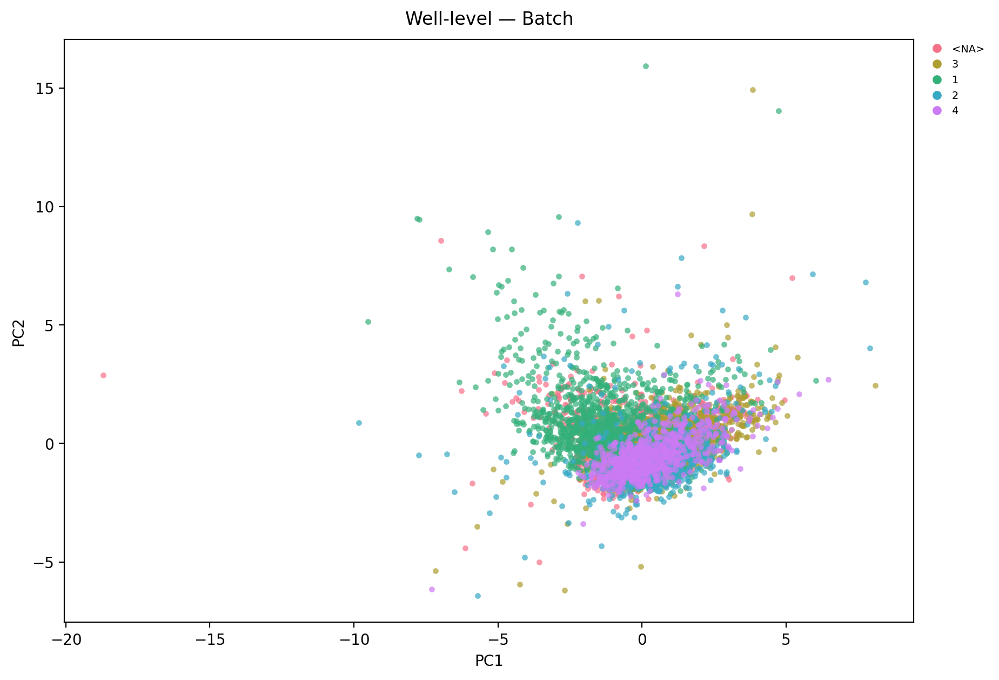

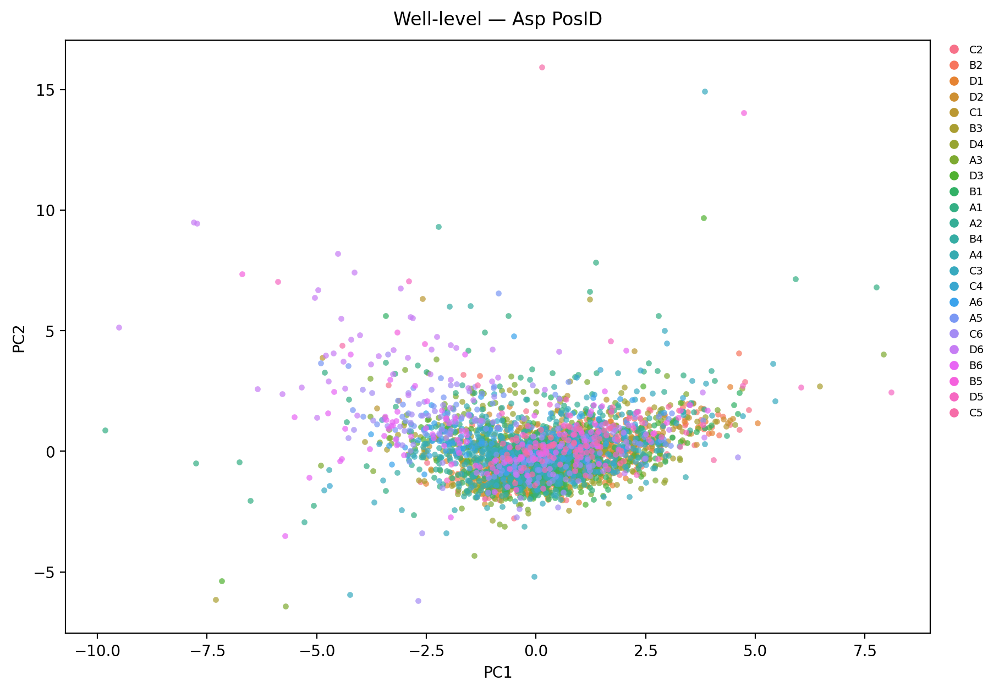

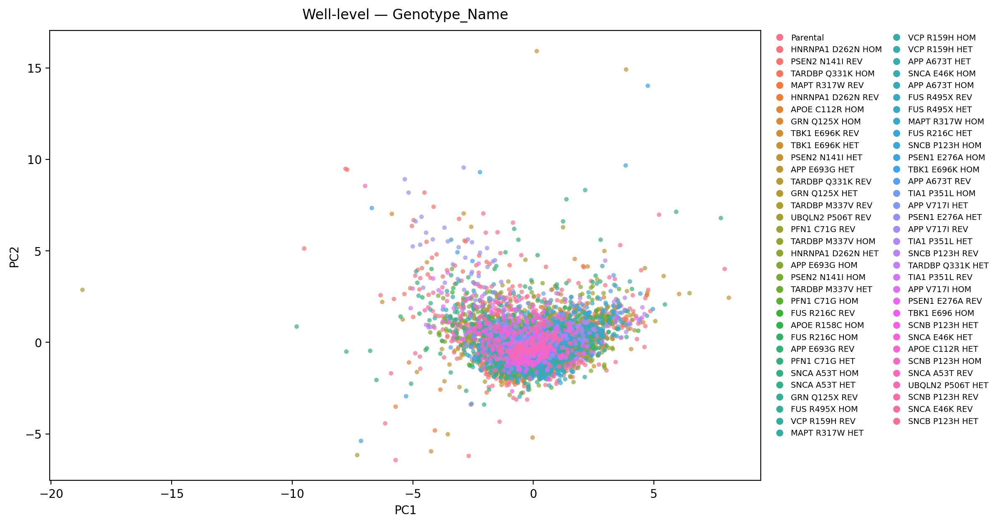

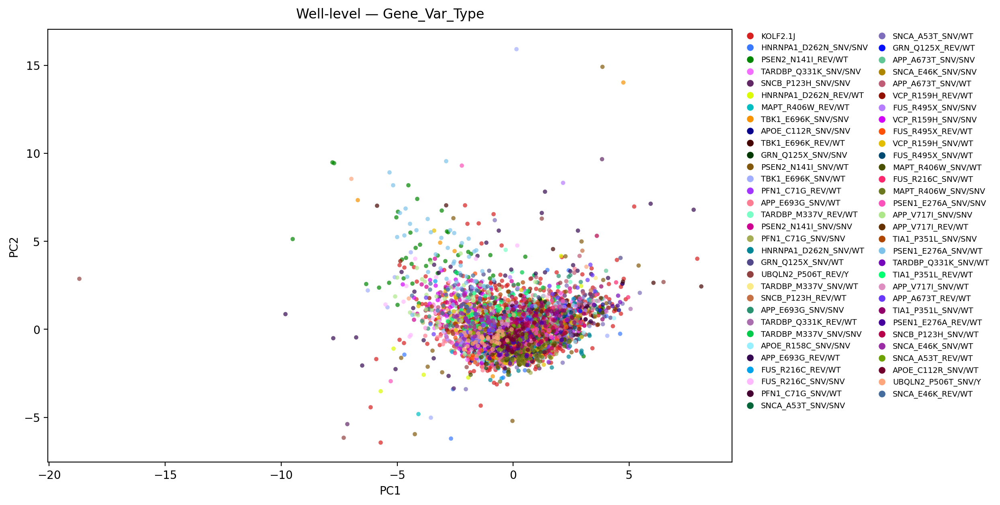

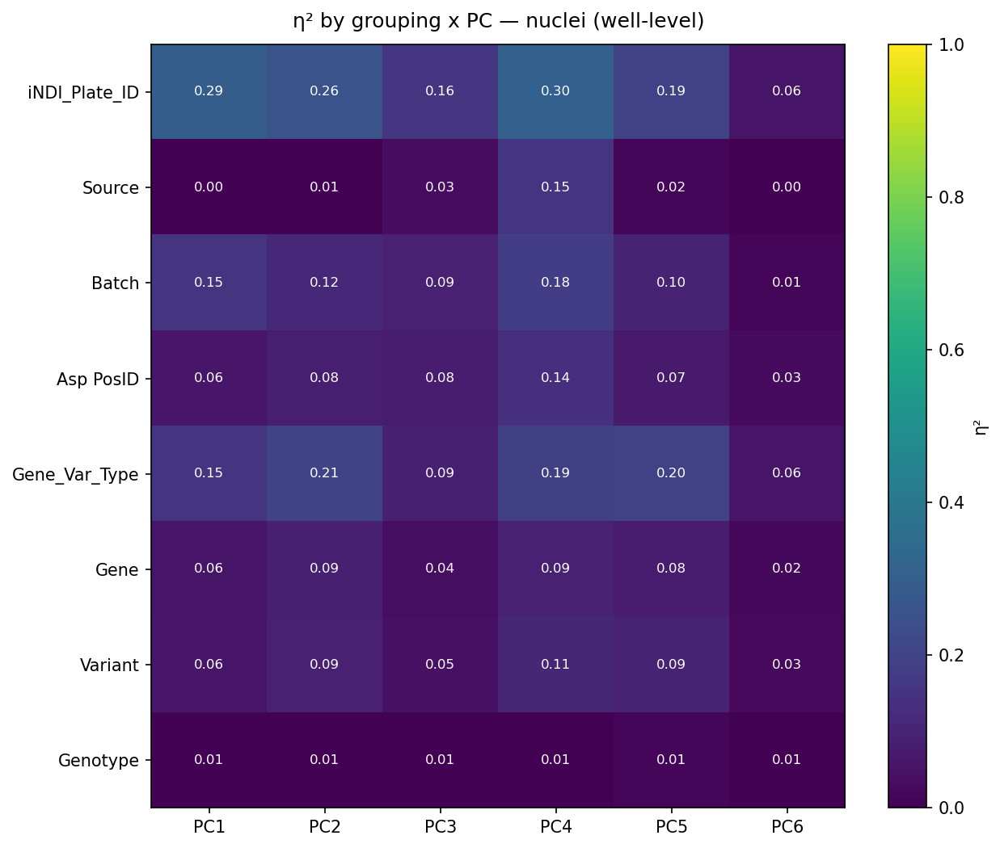

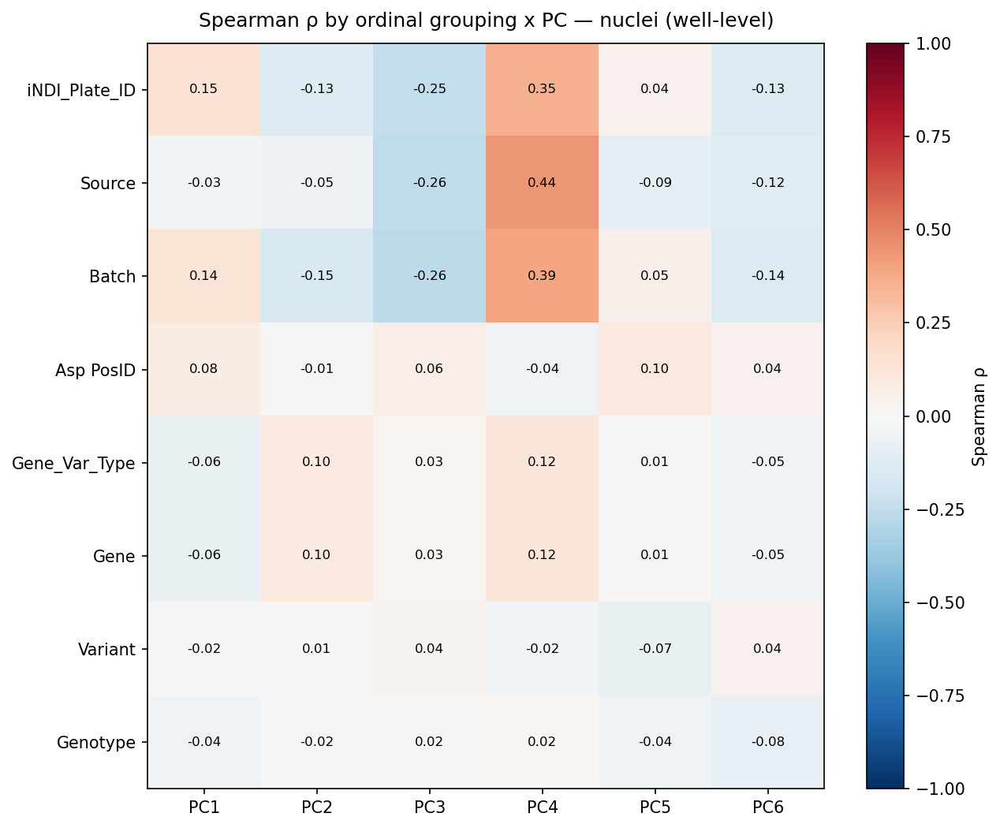

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.145014,-0.132569,-0.247455,0.352620,0.042928,-0.133287
Source,-0.025696,-0.052534,-0.256418,0.443152,-0.089103,-0.123187
Batch,0.136373,-0.150981,-0.260231,0.394928,0.054599,-0.135420
Asp PosID,0.077458,-0.014781,0.064620,-0.036074,0.100296,0.040208
Gene_Var_Type,-0.063965,0.099882,0.030032,0.118361,0.009356,-0.046050
Gene,-0.063039,0.099960,0.029161,0.121584,0.013948,-0.045513
Variant,-0.023334,0.008642,0.037317,-0.024240,-0.074319,0.043226
Genotype,-0.036318,-0.018097,0.015095,0.018806,-0.042398,-0.079660


In [48]:
# Nuclei keys: image = image_name, well = Measurement_ID + subdirectory.
# No Structure grouping.
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"

GROUP_KEYS = [*WELL_KEYS, IMAGE_KEY]
DROP_COLS = set(FEATURES) | {f"PC{i+1}" for i in range(20)} | set(GROUP_KEYS) \
            | {"label", "filename", "filepath"}
META_COLS = [c for c in df.columns if c not in DROP_COLS]

# safety: metadata carried by .first() should be invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "prep_method"]:
    if col in df.columns:
        n_bad = (df.groupby(WELL_KEYS)[col].nunique() > 1).sum()
        print(f"{col}: {n_bad} well(s) with >1 value{'  <-- CHECK' if n_bad else ''}")

# stage 1: median across nuclei within each image
agg_image = {**{f: "median" for f in FEATURES}, **{m: "first" for m in META_COLS}}
image_level = df.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows ({df[IMAGE_KEY].nunique()} images)")

# stage 2: mean across images within each well
agg_well = {**{f: "mean" for f in FEATURES}, **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_KEYS, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows")

# refit PCA on well-level profiles
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
Xw = StandardScaler().fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(scores_w.shape[1]):
    well_level[f"PC{i+1}"] = scores_w[:, i]
evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw.round(3), "| cumulative:", np.cumsum(evw).round(3))

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

### Variance-component analysis
This is built to handle all of the parental data for each genotype, but remember that this is HIGHLY unbalanced.\
"plate_match=True" will correct for this by only pulling parentals from the plates that each genotype is on, which is more accurate, but NOT a proxy for plate correction

[facet] 16 genes; 1450 total KOLF2.1J rows (all folded into each facet)
  APOE: 224 variant + 1450 KOLF rows


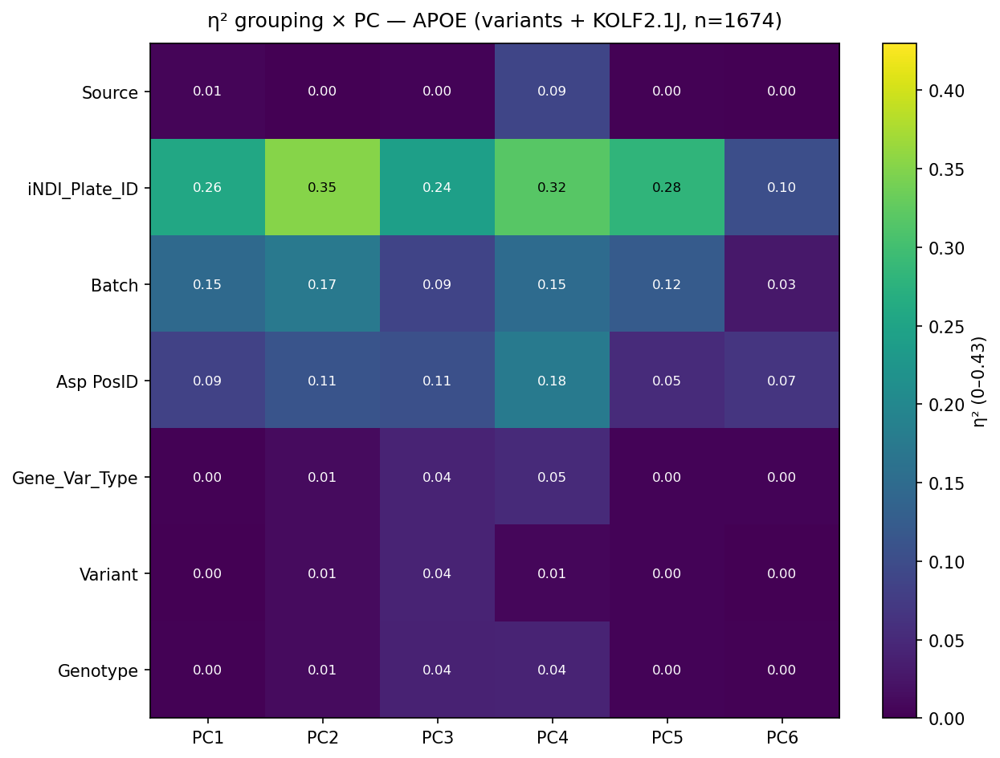

  APP: 613 variant + 1450 KOLF rows


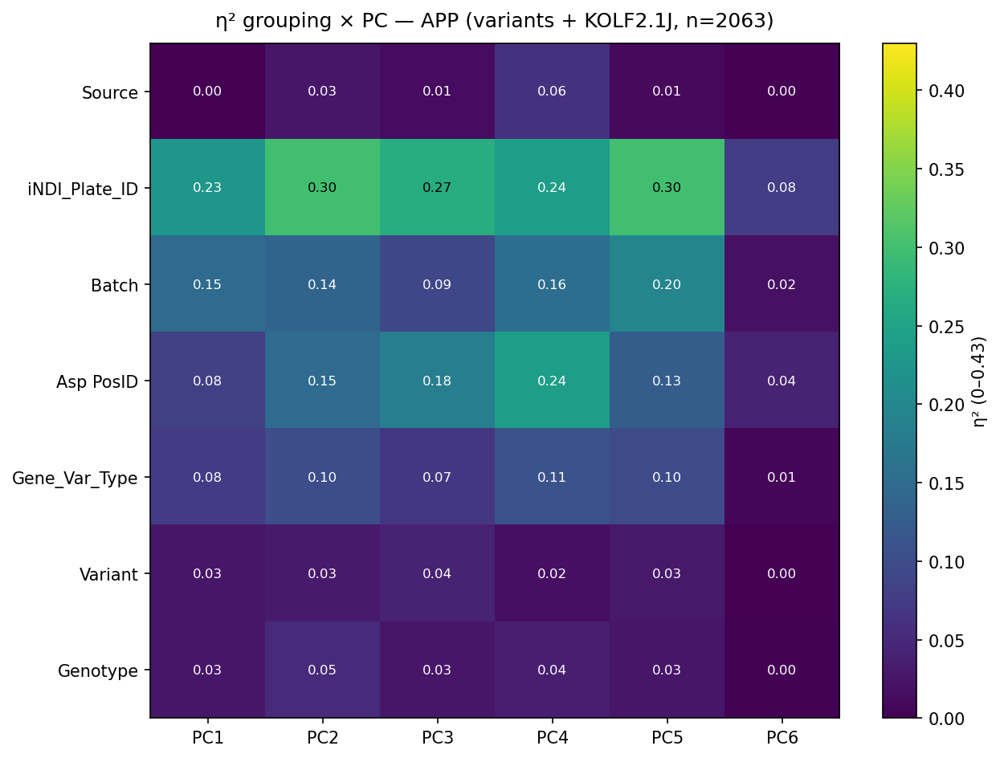

  FUS: 481 variant + 1450 KOLF rows


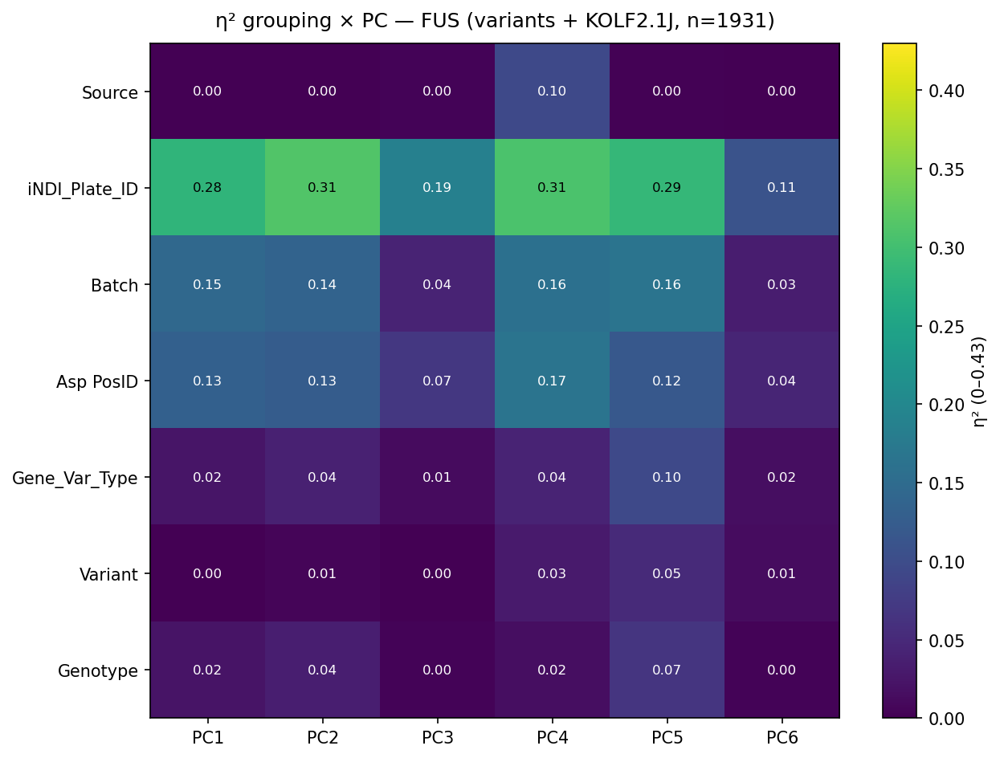

  GRN: 268 variant + 1450 KOLF rows


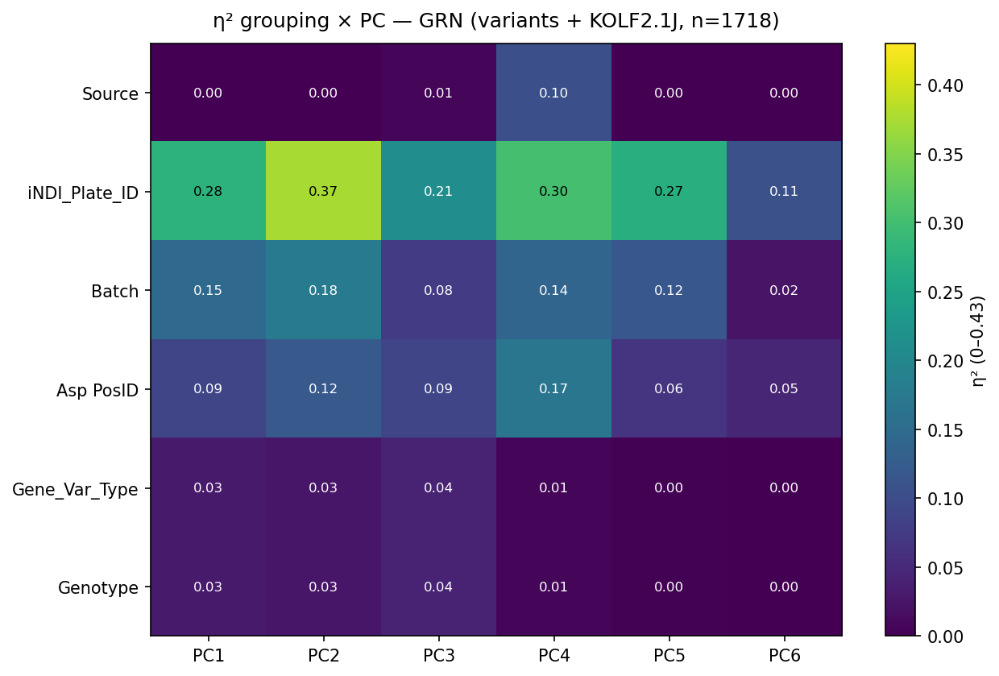

  HNRNPA1: 350 variant + 1450 KOLF rows


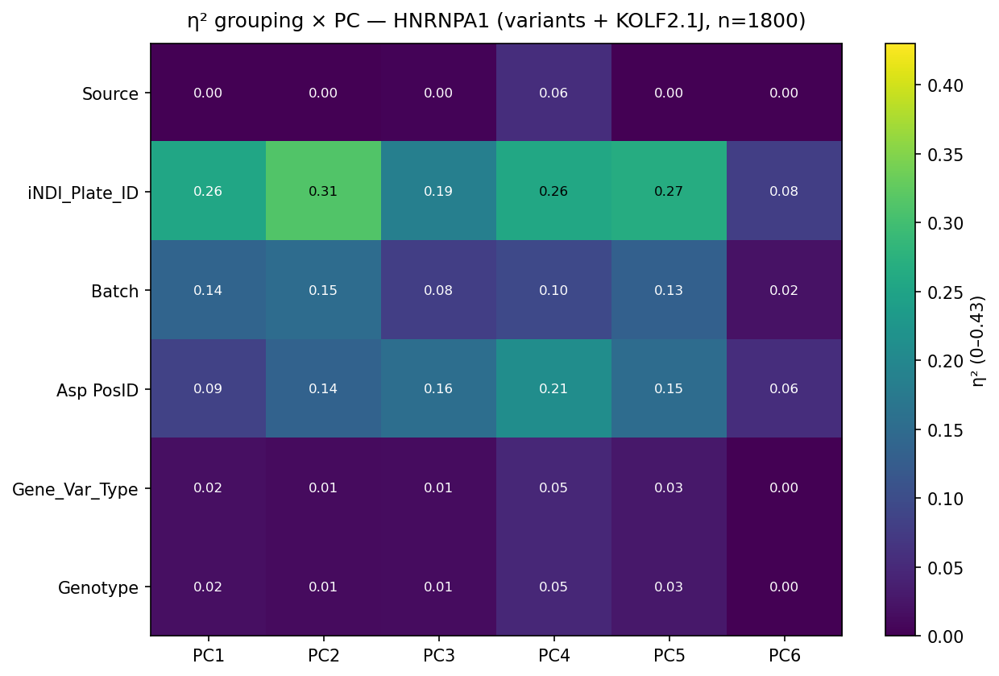

  MAPT: 255 variant + 1450 KOLF rows


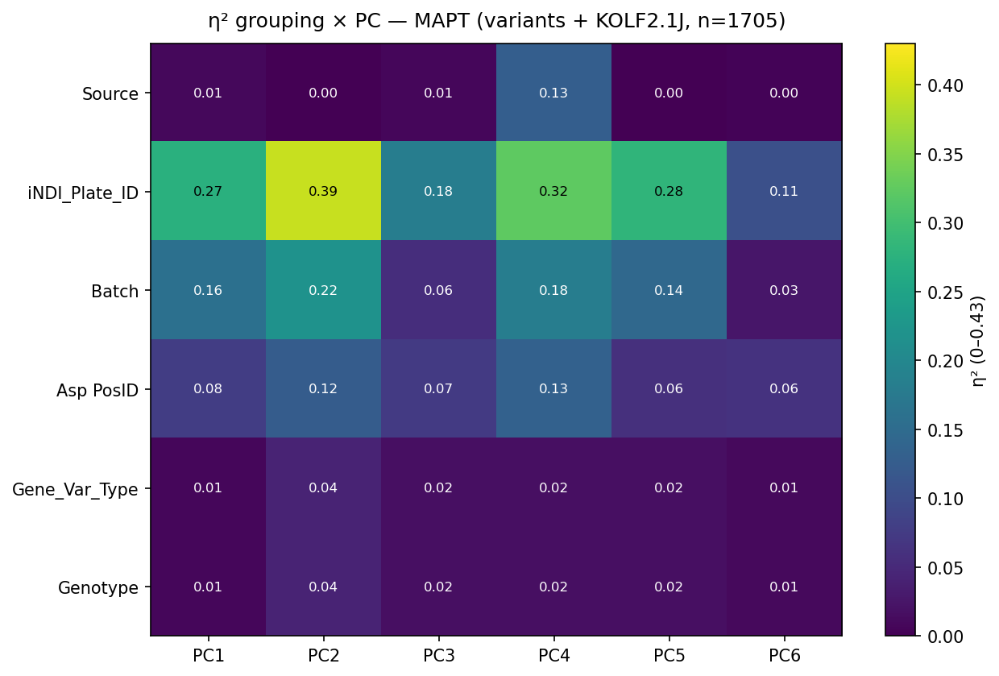

  PFN1: 268 variant + 1450 KOLF rows


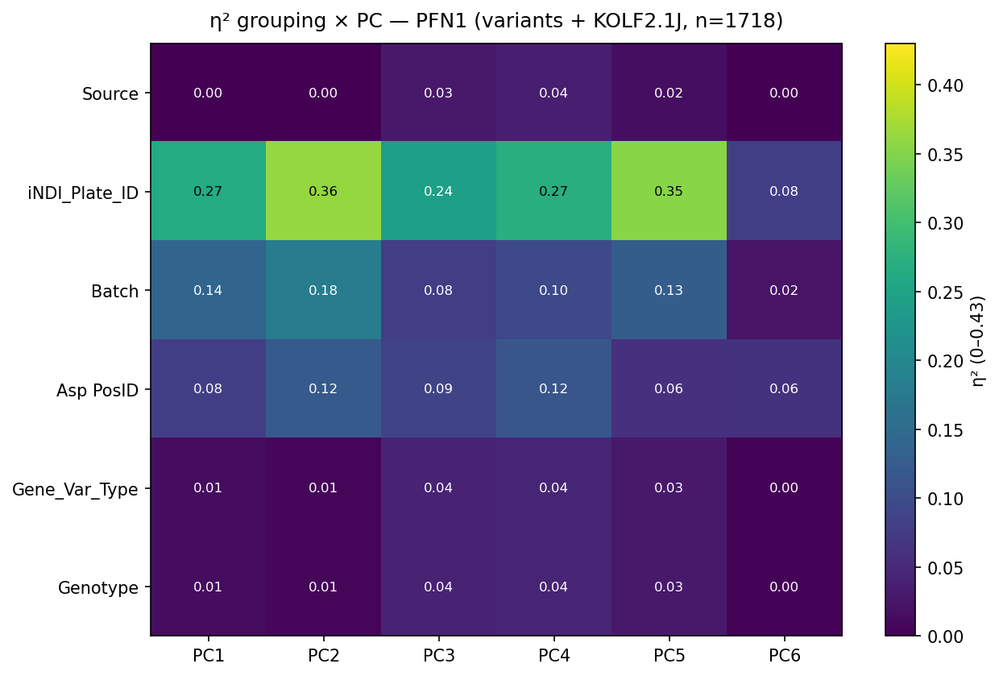

  PSEN1: 147 variant + 1450 KOLF rows


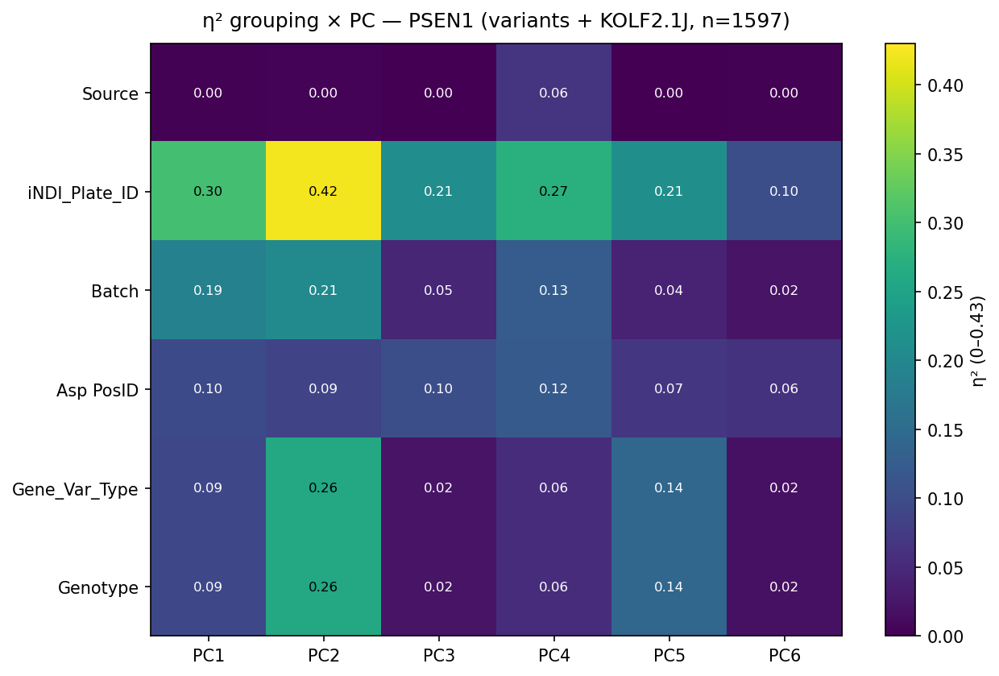

  PSEN2: 318 variant + 1450 KOLF rows


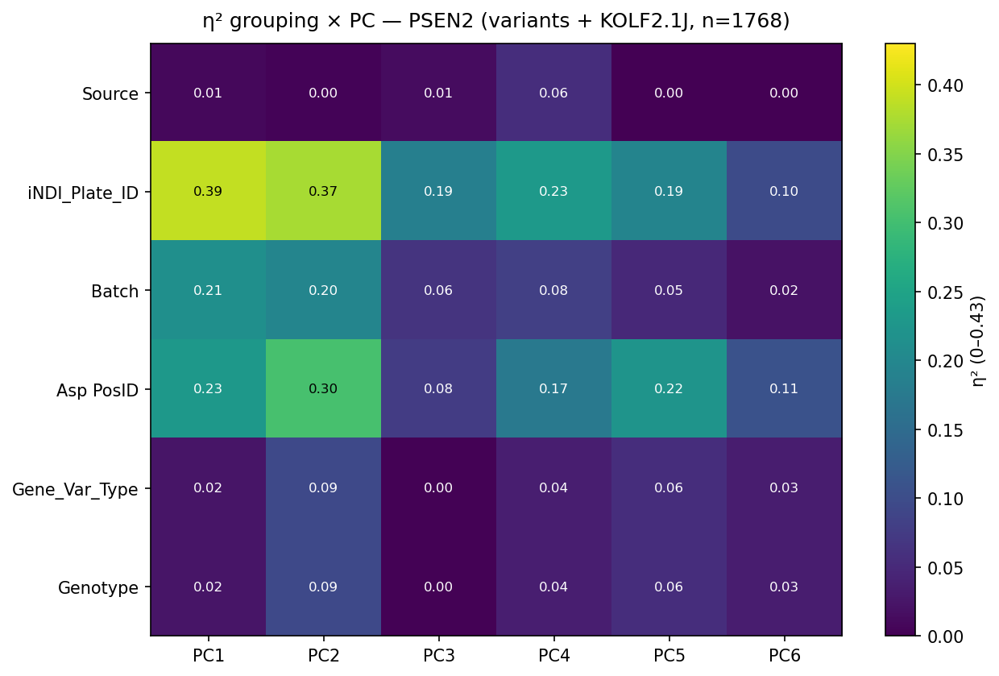

  SNCA: 363 variant + 1450 KOLF rows


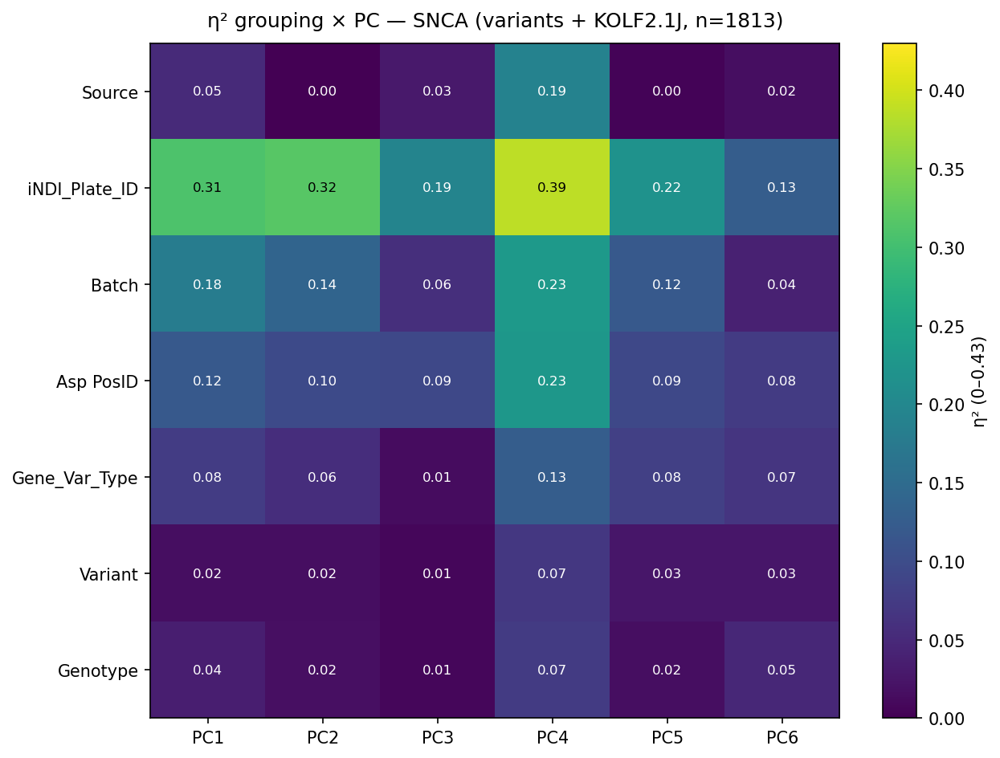

  SNCB: 249 variant + 1450 KOLF rows


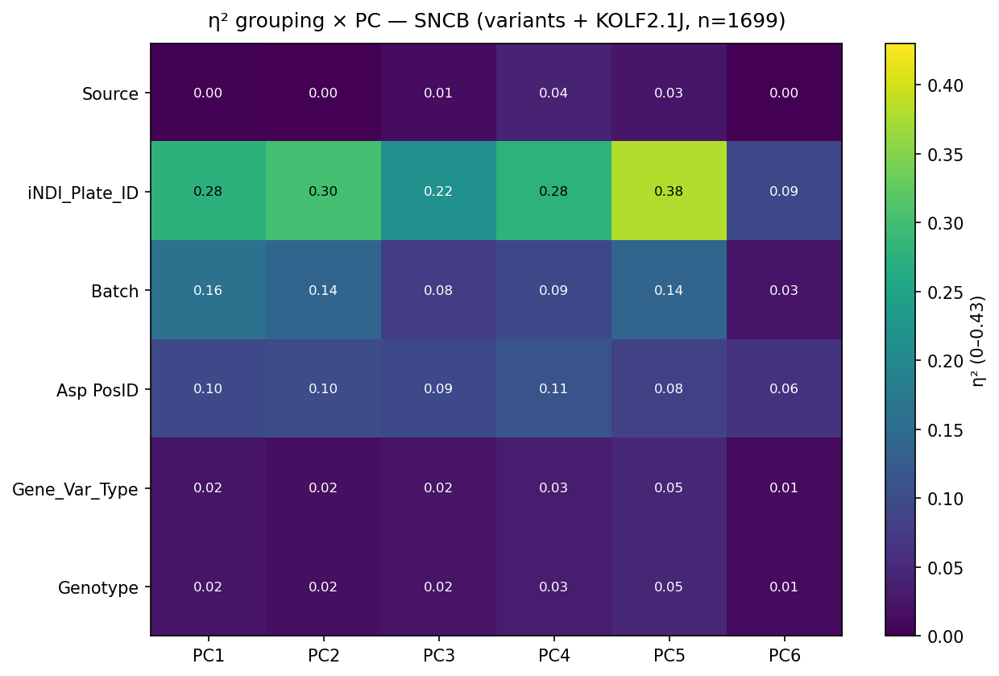

  TARDBP: 539 variant + 1450 KOLF rows


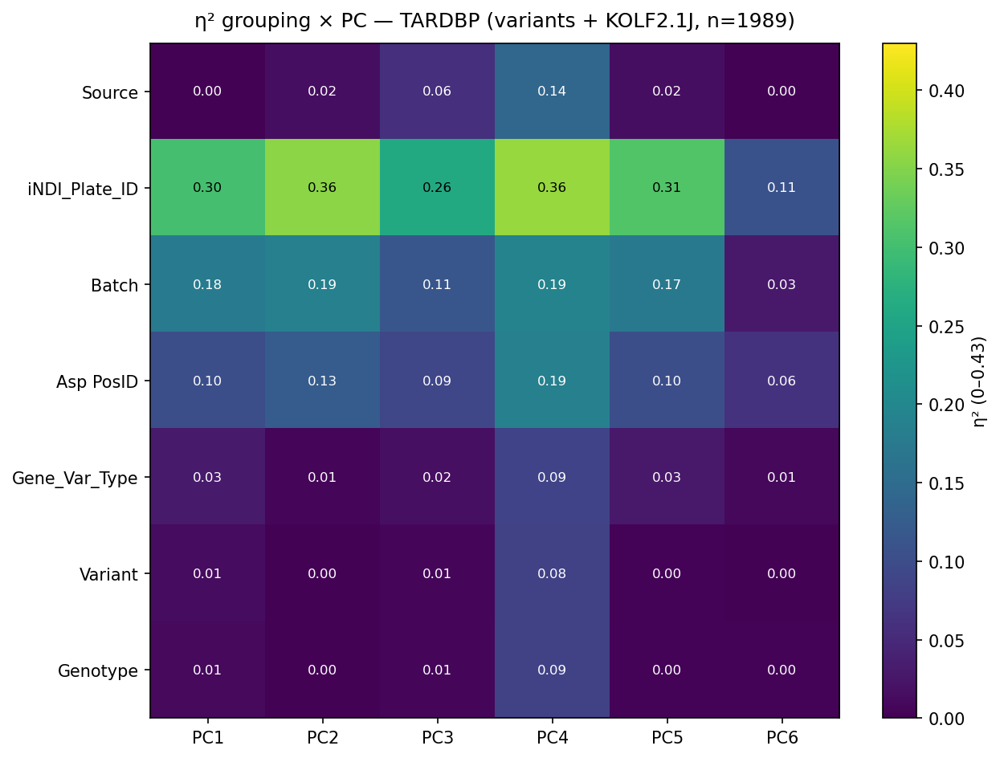

  TBK1: 277 variant + 1450 KOLF rows


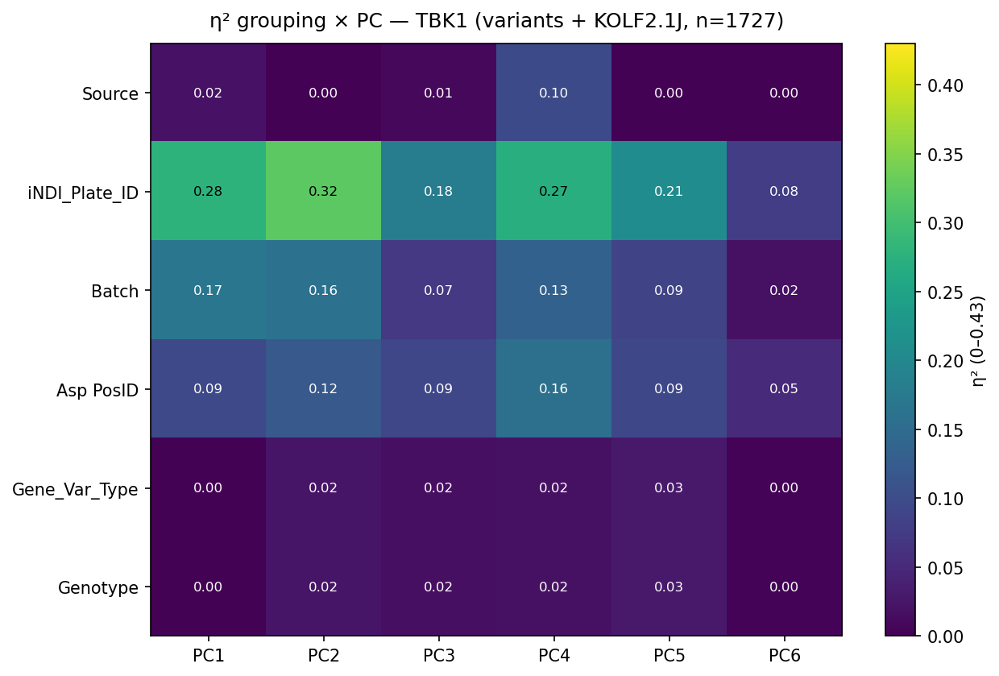

  TIA1: 144 variant + 1450 KOLF rows


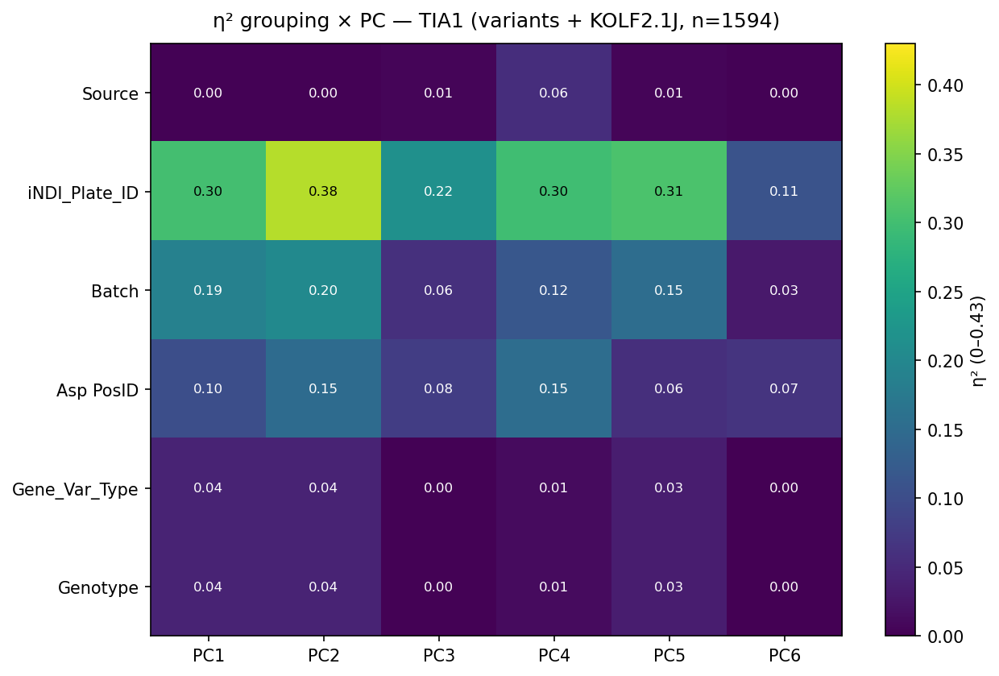

  UBQLN2: 132 variant + 1450 KOLF rows


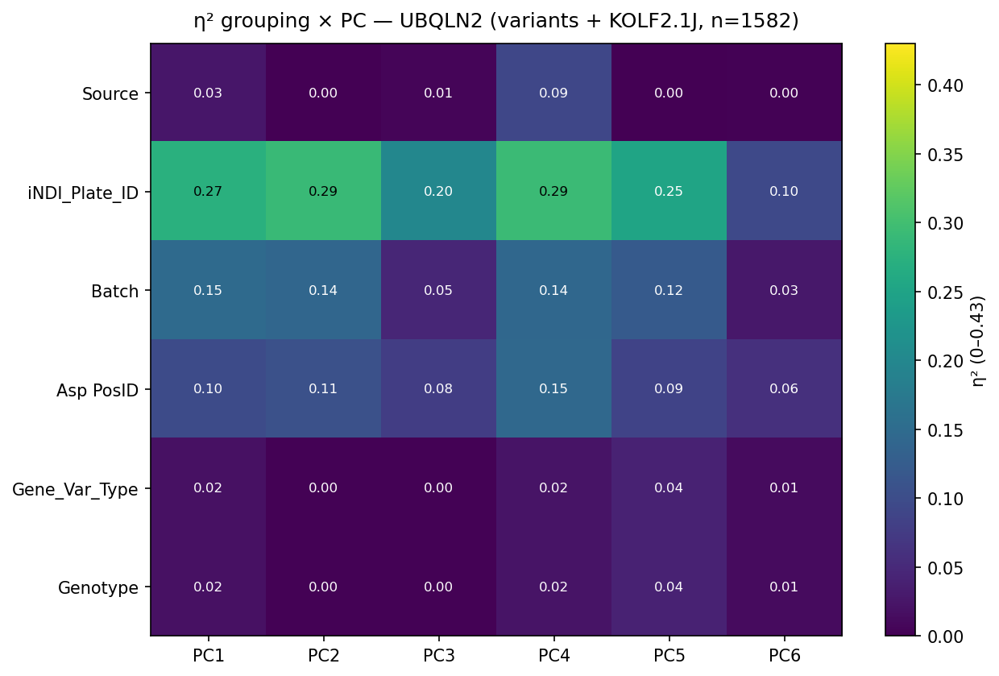

  VCP: 228 variant + 1450 KOLF rows


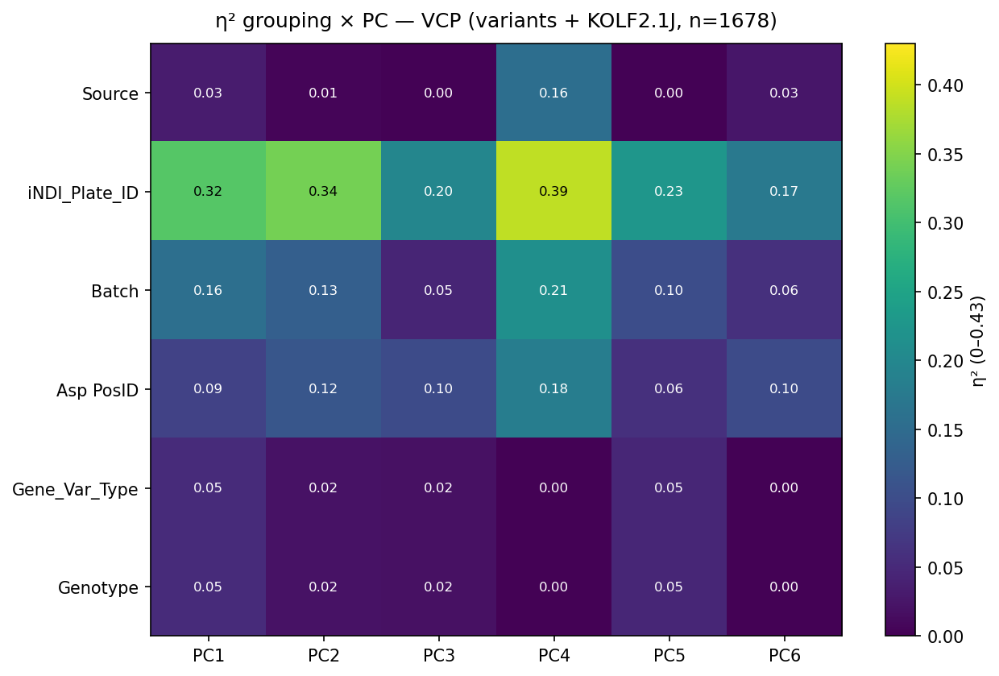

[facet] 16 genes; 1450 total KOLF2.1J rows (plate-matched per facet)
  APOE: 224 variant + 181 KOLF rows on 3 plate(s)


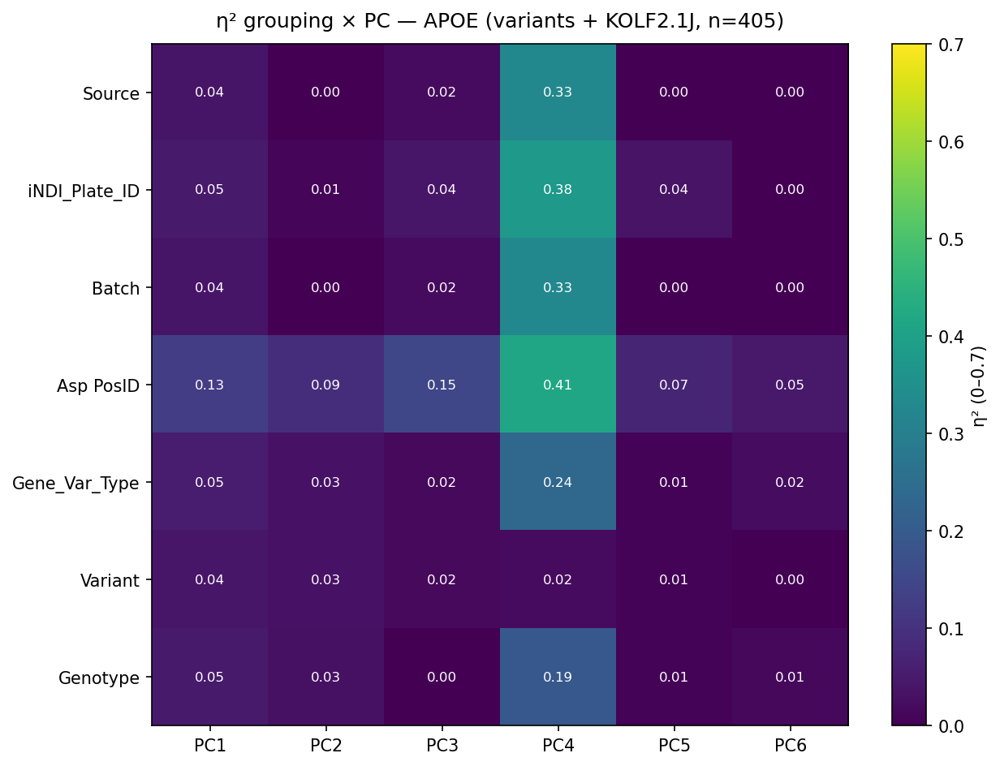

  APP: 613 variant + 433 KOLF rows on 6 plate(s)


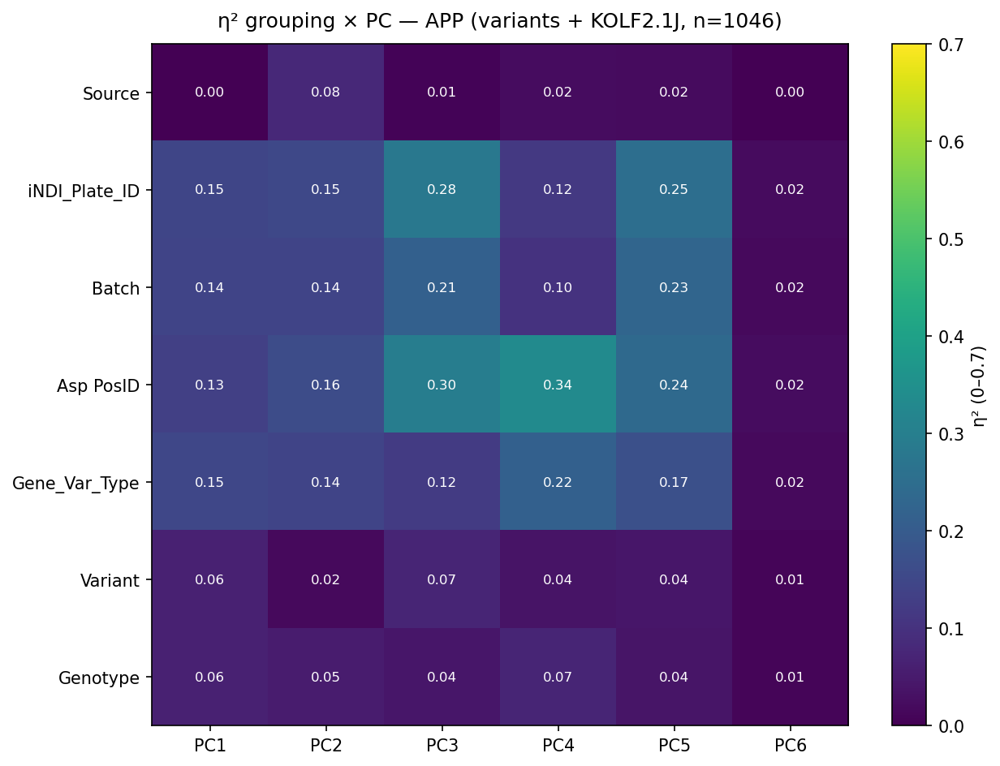

  FUS: 481 variant + 427 KOLF rows on 6 plate(s)


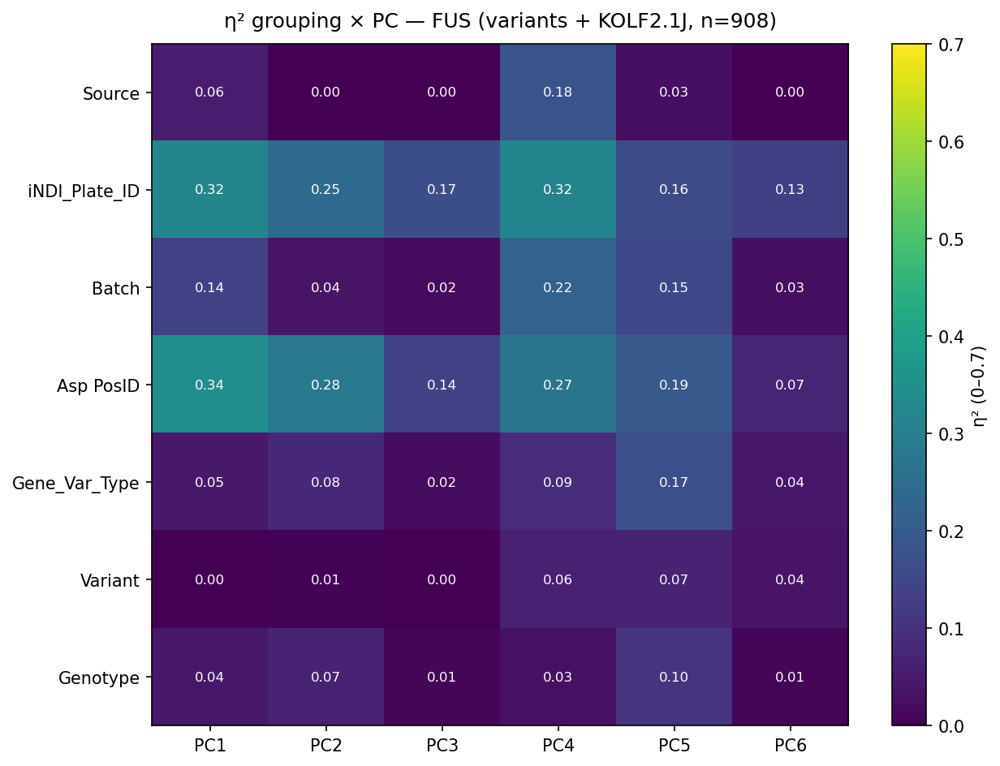

  GRN: 268 variant + 224 KOLF rows on 4 plate(s)


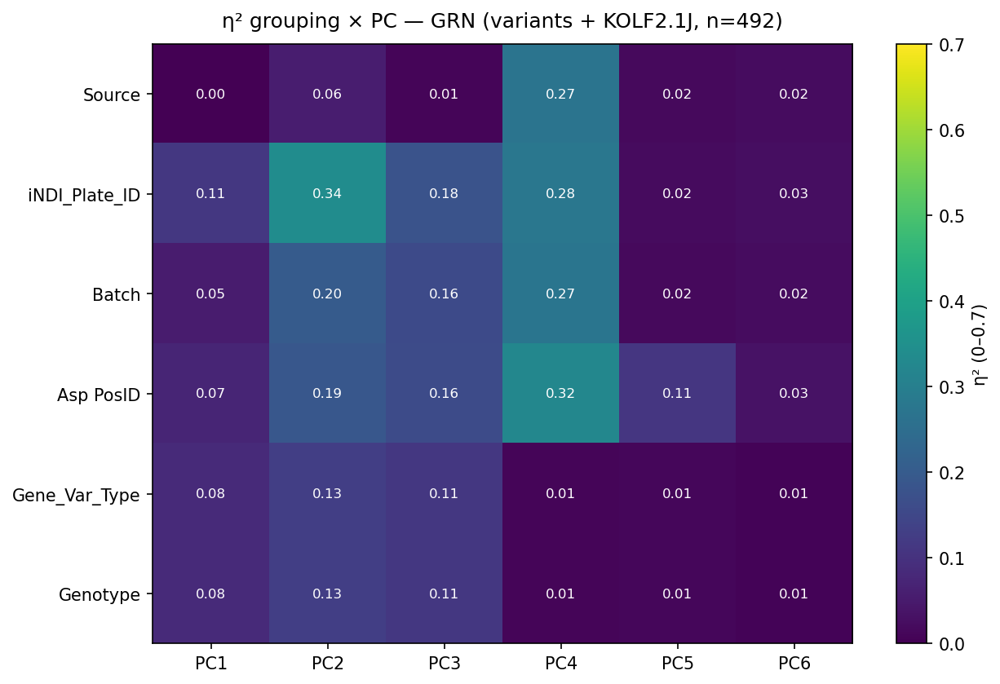

  HNRNPA1: 350 variant + 248 KOLF rows on 4 plate(s)


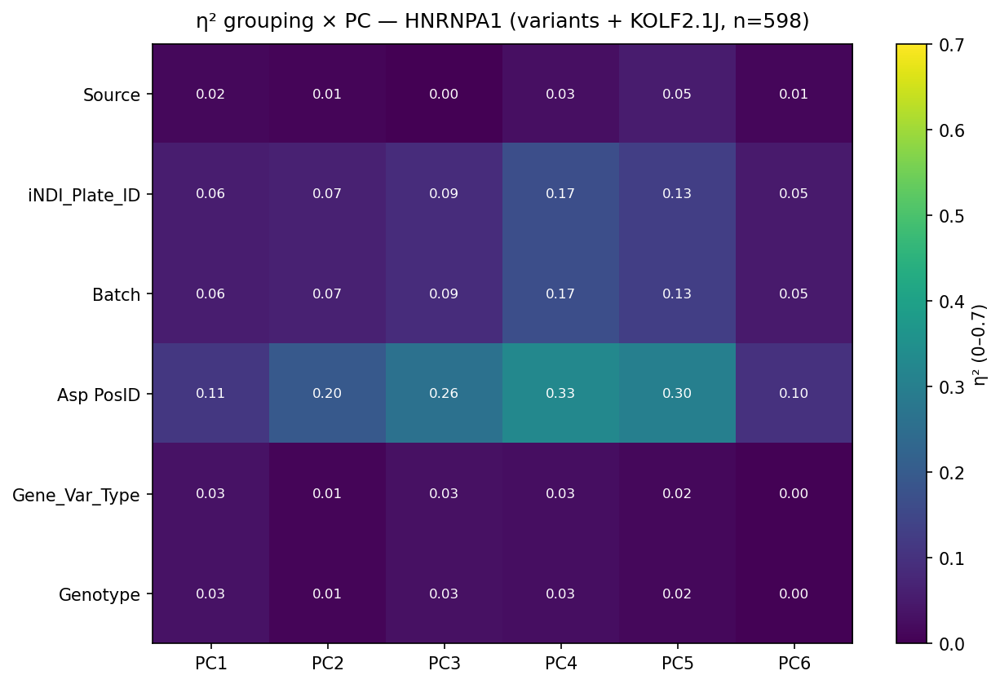

  MAPT: 255 variant + 180 KOLF rows on 3 plate(s)


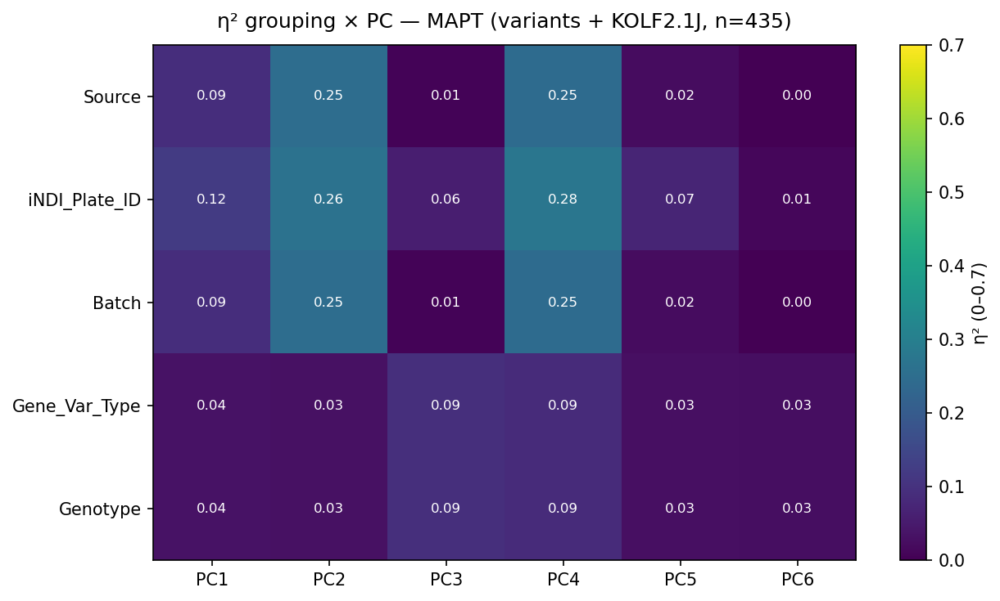

  PFN1: 268 variant + 180 KOLF rows on 3 plate(s)


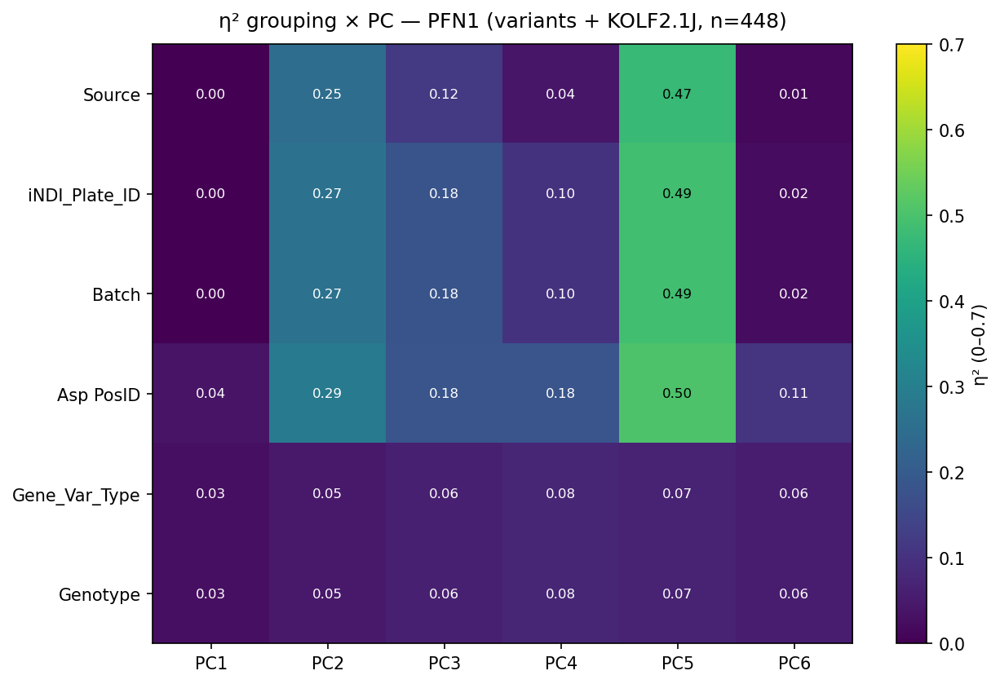

  PSEN1: 147 variant + 239 KOLF rows on 3 plate(s)


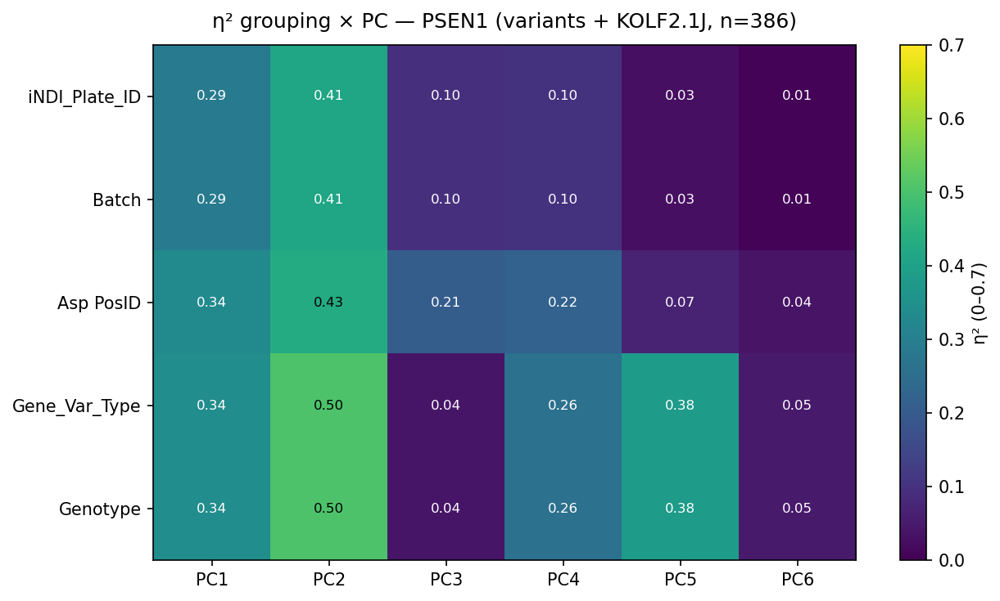

  PSEN2: 318 variant + 396 KOLF rows on 5 plate(s)


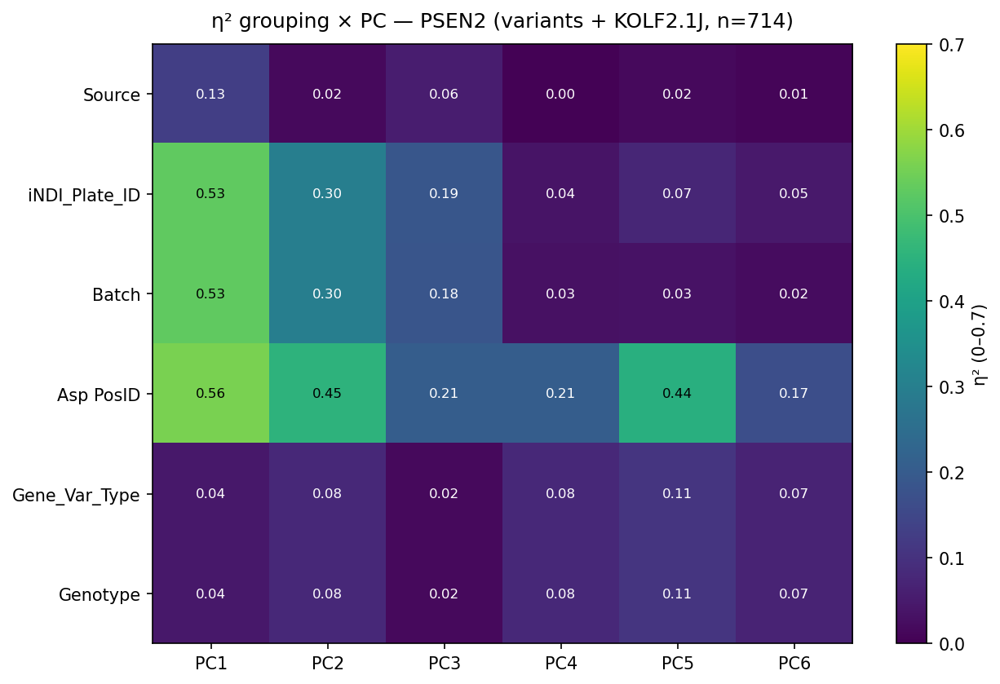

  SNCA: 363 variant + 259 KOLF rows on 4 plate(s)


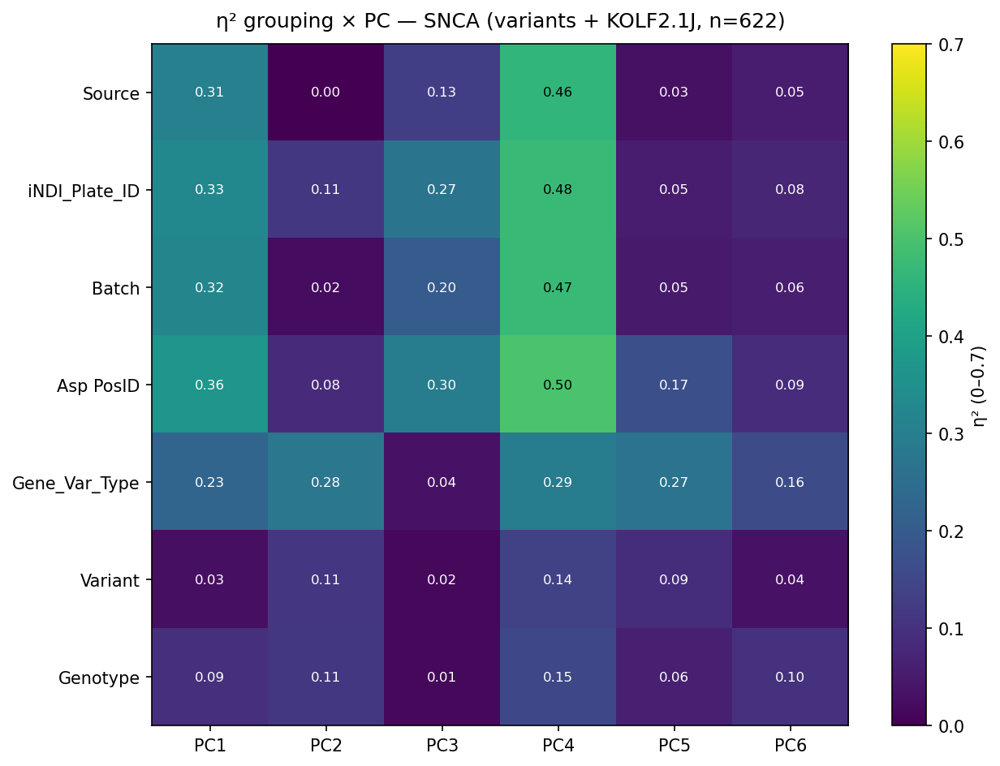

  SNCB: 249 variant + 234 KOLF rows on 3 plate(s)


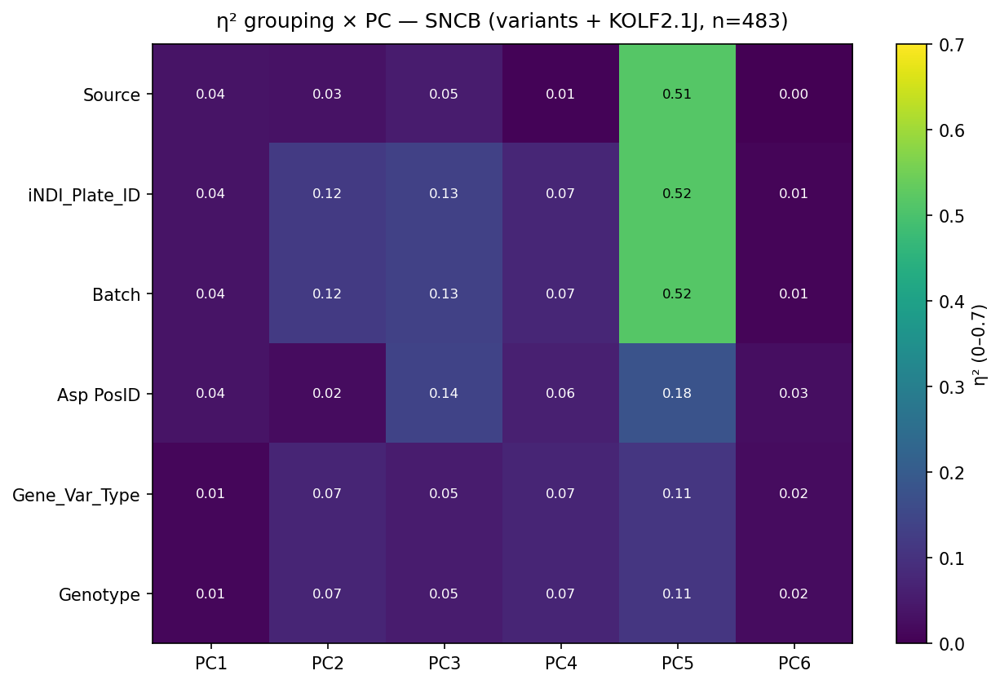

  TARDBP: 539 variant + 360 KOLF rows on 6 plate(s)


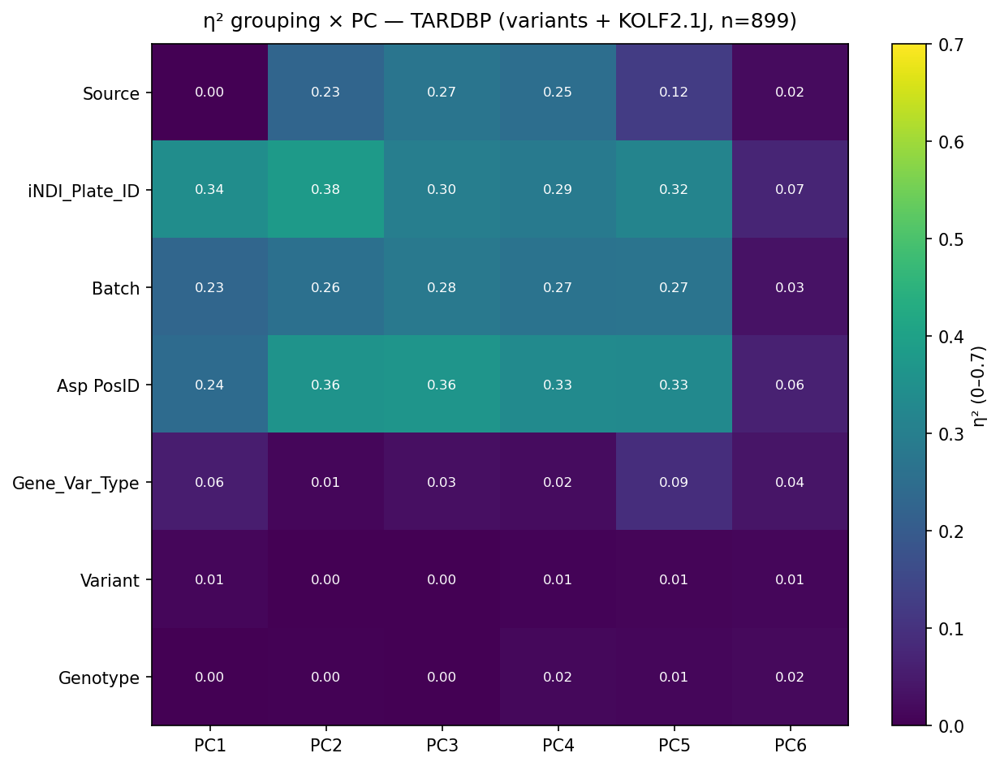

  TBK1: 277 variant + 276 KOLF rows on 4 plate(s)


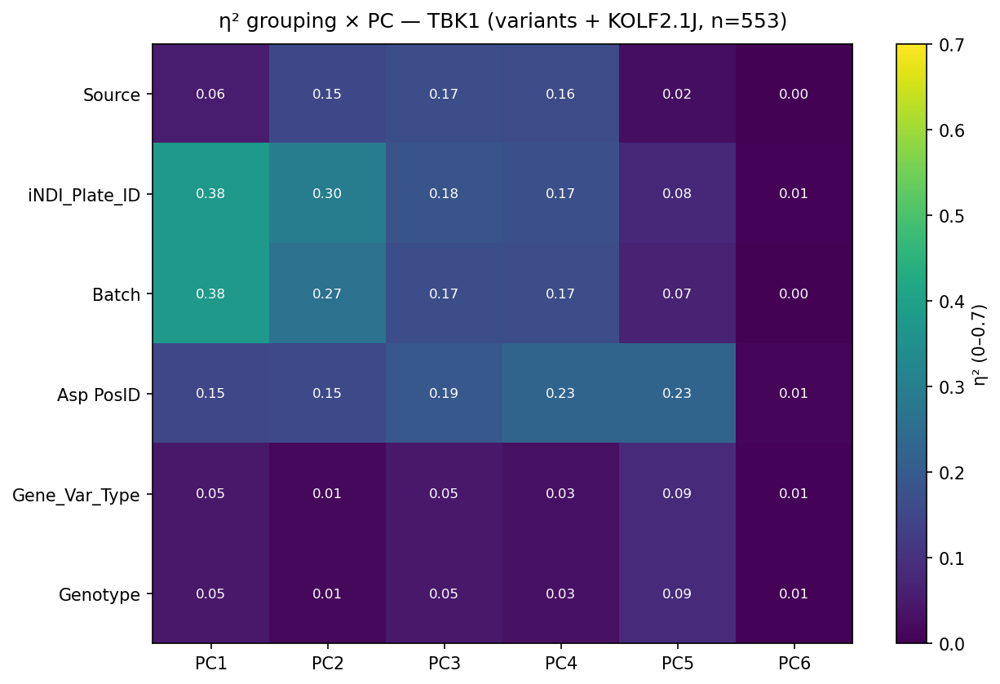

  TIA1: 144 variant + 192 KOLF rows on 2 plate(s)


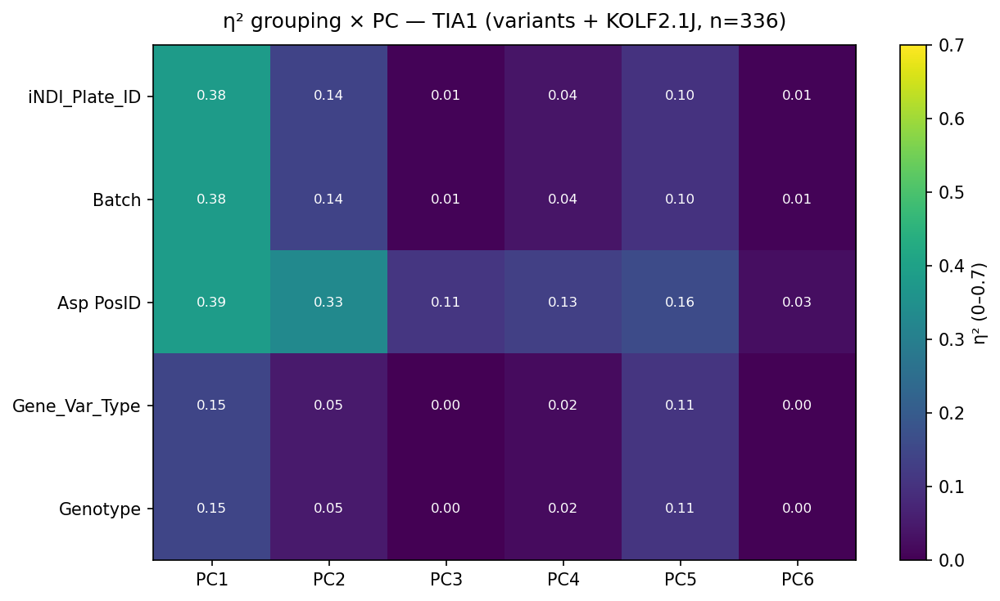

  UBQLN2: 132 variant + 136 KOLF rows on 2 plate(s)


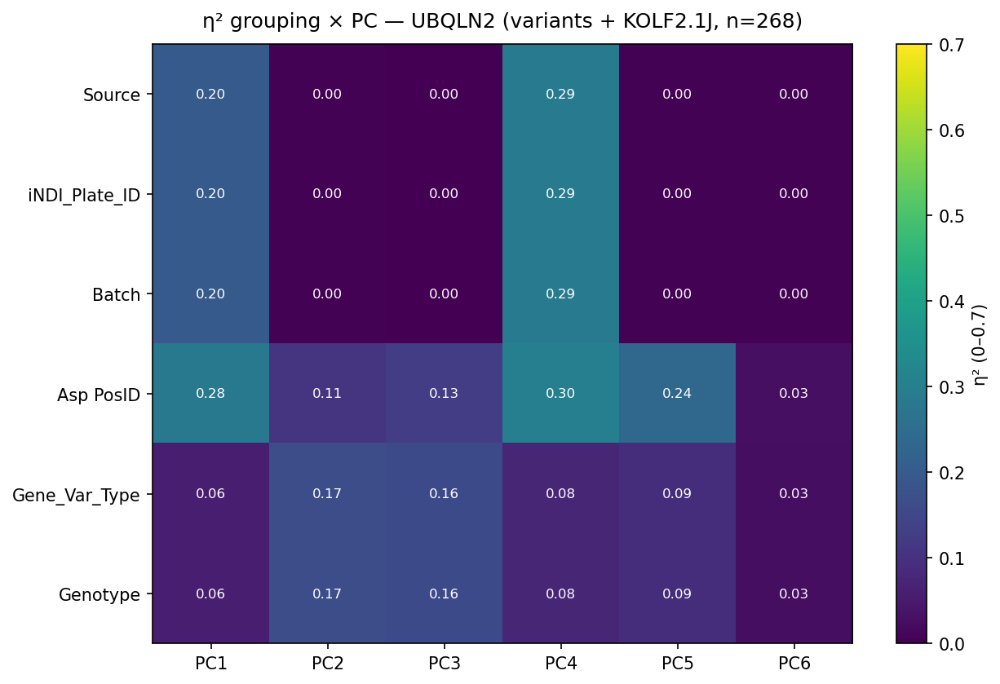

  VCP: 228 variant + 124 KOLF rows on 2 plate(s)


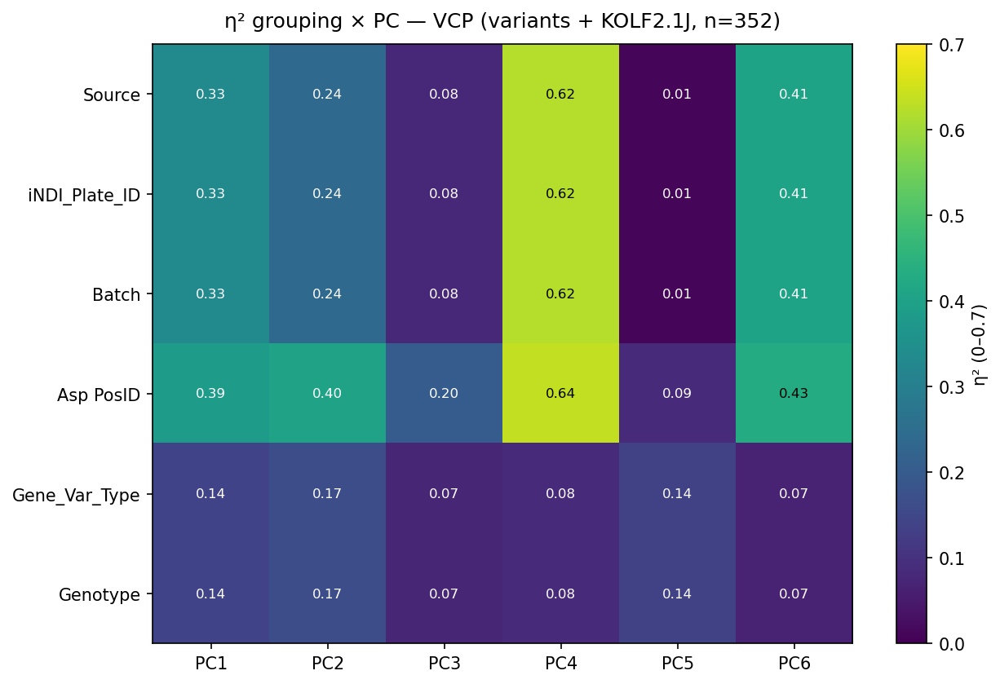

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene: ONE SEPARATE FIGURE per gene --------------------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, vmax=0.2, annot=True,
                      drop_constant=True):
    """Draw a single grouping x PC η² heatmap for one gene's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} (variants + KOLF2.1J, n={len(sub)})",
                 pad=10)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene(data, group_cols, n_pcs=10,
                  gene_col="Gene", vmax=0.2, annot=True,
                  include_wt=True, drop_constant=True,
                  plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per gene. Each gene's subset is that
    gene's variant rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that gene's variants actually occupy, removing the plate confound
    that arises when controls span all plates but a gene sits on only a few.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]
    genes = sorted(pd.unique(edited[gene_col].dropna()))
    print(f"[facet] {len(genes)} genes; {len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    facet_groups = [g for g in group_cols if g != gene_col]

    mats = {}
    for gene in genes:
        gene_rows = edited[edited[gene_col] == gene]
        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                gene_plates = set(gene_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(gene_plates)]
            sub = pd.concat([gene_rows, wt_use], ignore_index=True)
            print(f"  {gene}: {len(gene_rows)} variant + {len(wt_use)} KOLF rows"
                  f"{f' on {len(set(gene_rows[plate_col].dropna().unique()))} plate(s)' if plate_match else ''}")
        else:
            sub = gene_rows
        mats[gene] = plot_gene_heatmap(sub, facet_groups, pc_cols, gene,
                                       vmax=vmax, annot=annot,
                                       drop_constant=drop_constant)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

## Automated analysis
### Feature assessment and loadings

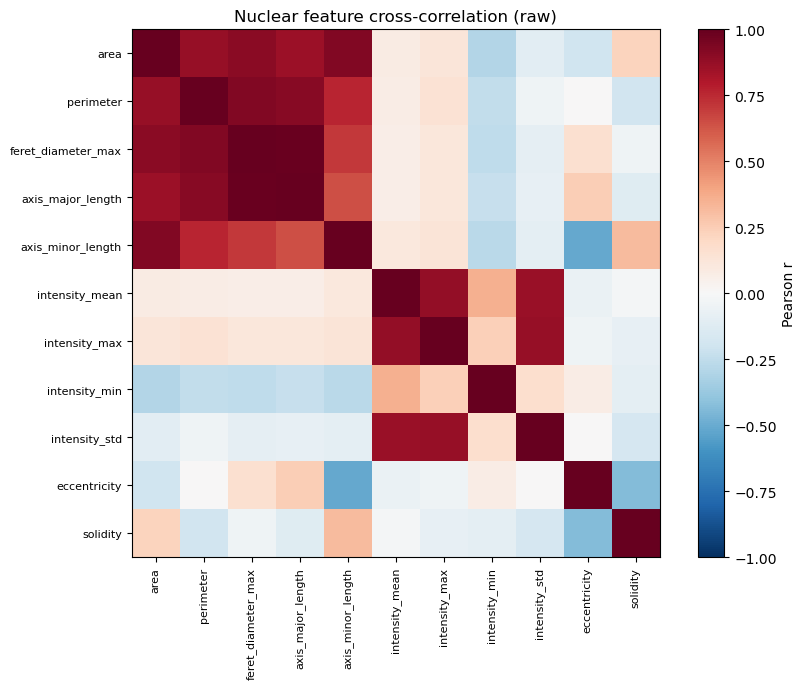

Highly correlated pairs (|r| > 0.9):
  +0.987  feret_diameter_max     axis_major_length
  +0.925  area                   axis_minor_length
  +0.924  perimeter              feret_diameter_max
  +0.907  perimeter              axis_major_length
  +0.900  area                   feret_diameter_max

Using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']


/tmp/ipykernel_1676947/1529614371.py:45: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_auto["aspect_ratio"] = df_auto["axis_minor_length"] / df_auto["axis_major_length"]


Dropped 0 rows with NaN/inf; 1046112 remain


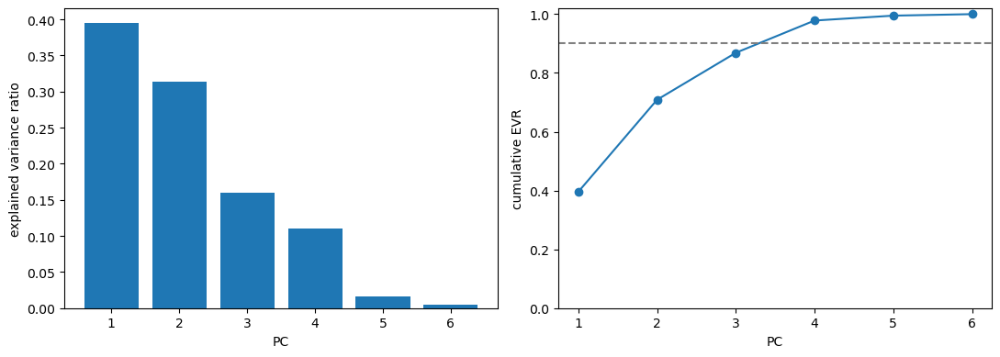

EVR: [0.396 0.313 0.16  0.11  0.017 0.005]
cumulative: [0.396 0.709 0.869 0.978 0.995 1.   ]
                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.201  0.053  0.961 -0.139  0.119  0.015
intensity_mean -0.085  0.697  0.087  0.153 -0.690 -0.010
intensity_std  -0.167  0.683 -0.086  0.026  0.705  0.015
eccentricity   -0.593 -0.155  0.171  0.340  0.003  0.692
solidity        0.451 -0.033  0.023  0.883  0.111 -0.060
aspect_ratio    0.607  0.141 -0.179 -0.249 -0.021  0.719


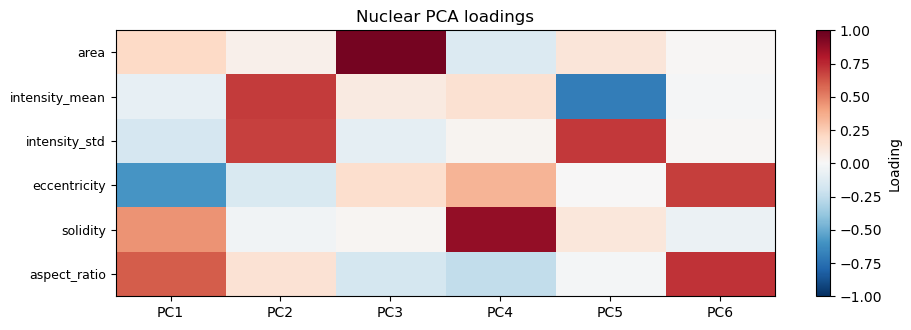

In [50]:
df_auto = df[df["Source"] == "automated"]

# ---------------------------------------------------------------
# STEP 0 — candidate nuclear features (regionprops from script 1)
# ---------------------------------------------------------------
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c in df_auto.columns]

# ---------------------------------------------------------------
# STEP 1 — cross-correlation (raw, pre-scaling)
# ---------------------------------------------------------------
X_all = df_auto[CANDIDATE_FEATURES].replace([np.inf, -np.inf], np.nan)
corr = X_all.corr(method="pearson")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, rotation=90, fontsize=8)
plt.yticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, fontsize=8)
plt.colorbar(im, label="Pearson r")
plt.title("Nuclear feature cross-correlation (raw)")
plt.tight_layout(); plt.show()

hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(CANDIDATE_FEATURES)
    for b in CANDIDATE_FEATURES[i + 1:]
    if hi.loc[a, b]
]
print("Highly correlated pairs (|r| > 0.9):")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {r:+.3f}  {a:22s} {b}")

# ---------------------------------------------------------------
# STEP 2 — pruned FEATURES
# ---------------------------------------------------------------
df_auto["aspect_ratio"] = df_auto["axis_minor_length"] / df_auto["axis_major_length"]

FEATURES = [
    "area",
    "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]
FEATURES = [c for c in FEATURES if c in df_auto.columns]
print("\nUsing FEATURES:", FEATURES)

# ---------------------------------------------------------------
# NaN/inf handling
# ---------------------------------------------------------------
before = len(df)
X_df = df[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
df = df[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with NaN/inf; {len(df)} remain")

# ---------------------------------------------------------------
# scale + PCA
# ---------------------------------------------------------------
X = StandardScaler().fit_transform(X_df.values)
pca = PCA(n_components=len(FEATURES))
scores = pca.fit_transform(X)
for i in range(scores.shape[1]):
    df[f"PC{i+1}"] = scores[:, i]

# scree
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev) + 1), ev)
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print("EVR:", ev.round(3))
print("cumulative:", np.cumsum(ev).round(3))

# loadings
loadings = pd.DataFrame(
    pca.components_.T, index=FEATURES,
    columns=[f"PC{i+1}" for i in range(len(FEATURES))],
)
print(loadings.round(3))

n_show = min(6, len(FEATURES))
plt.figure(figsize=(1.6 * n_show, 0.4 * len(FEATURES) + 1))
im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=9)
plt.colorbar(im, label="Loading")
plt.title("Nuclear PCA loadings")
plt.tight_layout(); plt.show()

### PCA plots - ROI-level

13 plates in this run:
['INDI00002D', 'INDI00007D', 'INDI00011D', 'INDI00015D', 'INDI00019D', 'INDI00023D', 'INDI00026D', 'INDI00035D', 'INDI00039D', 'INDI00043D', 'INDI00047D', 'INDI00049D', 'INDI00053D']
All 13 plates have a color.


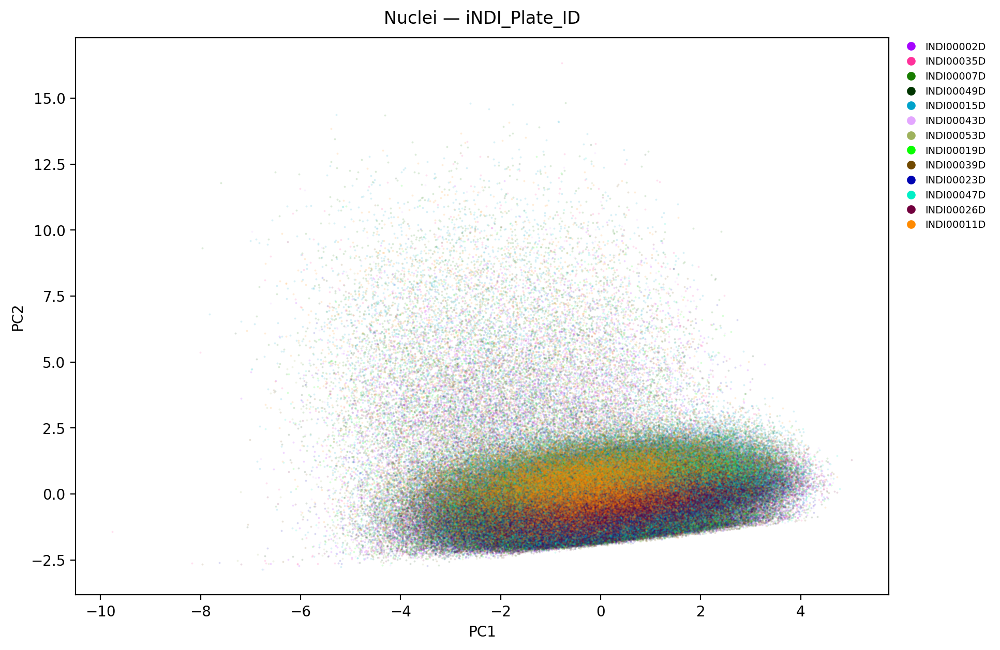

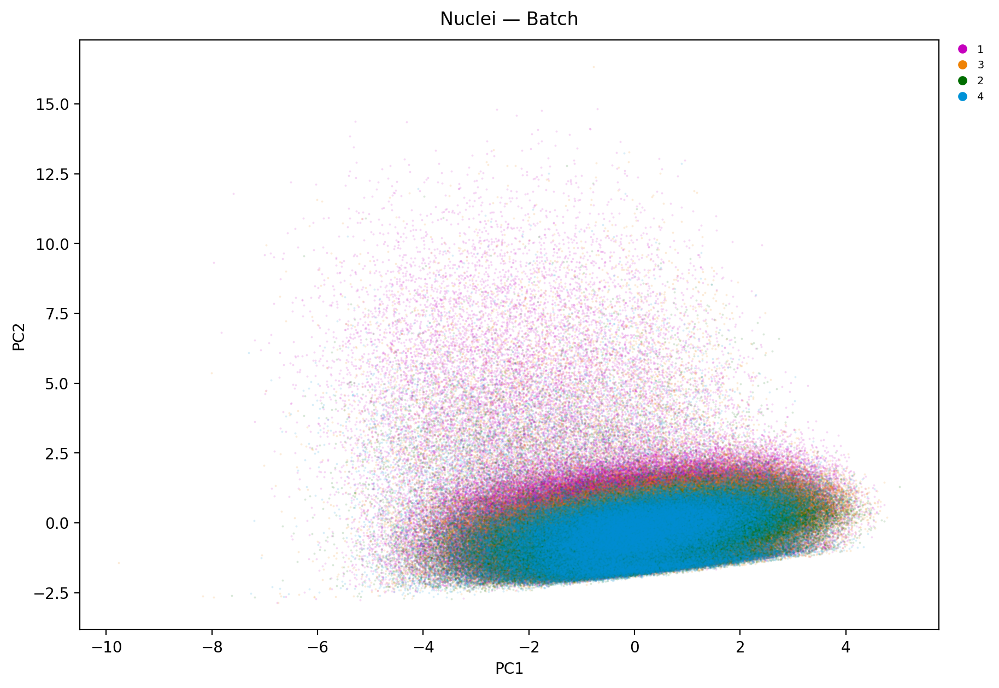

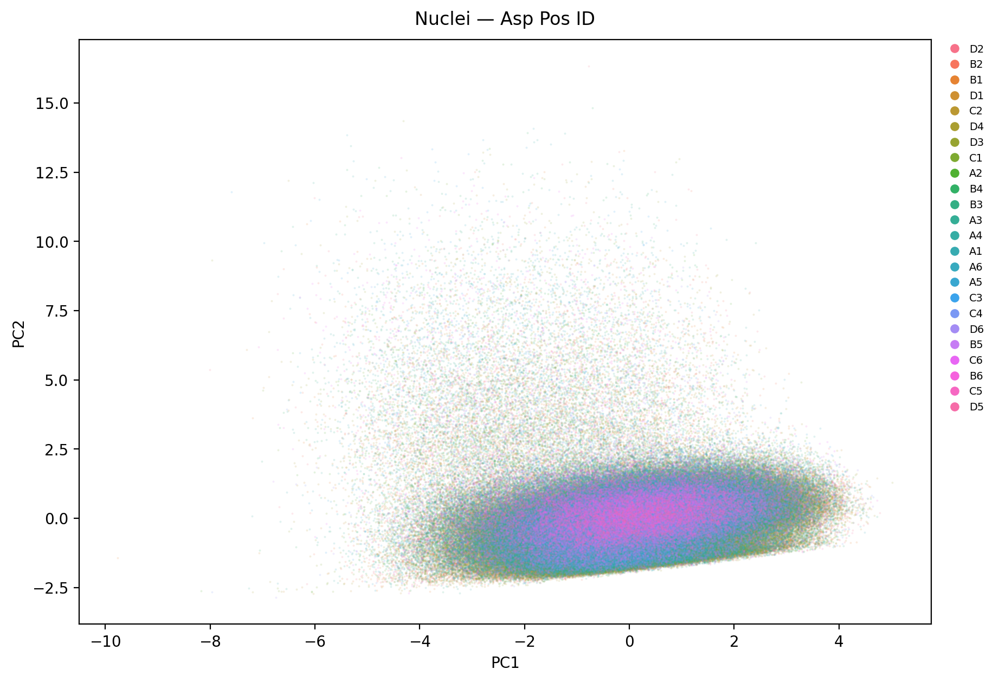

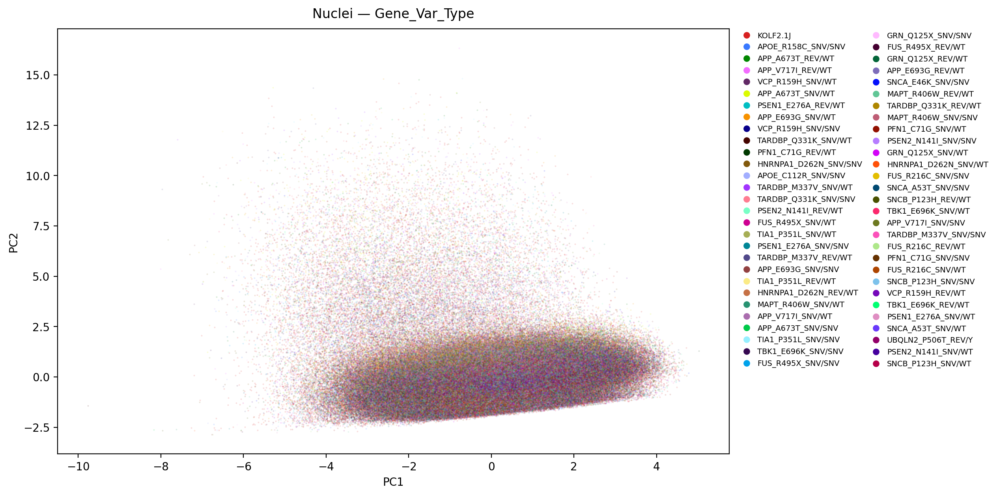

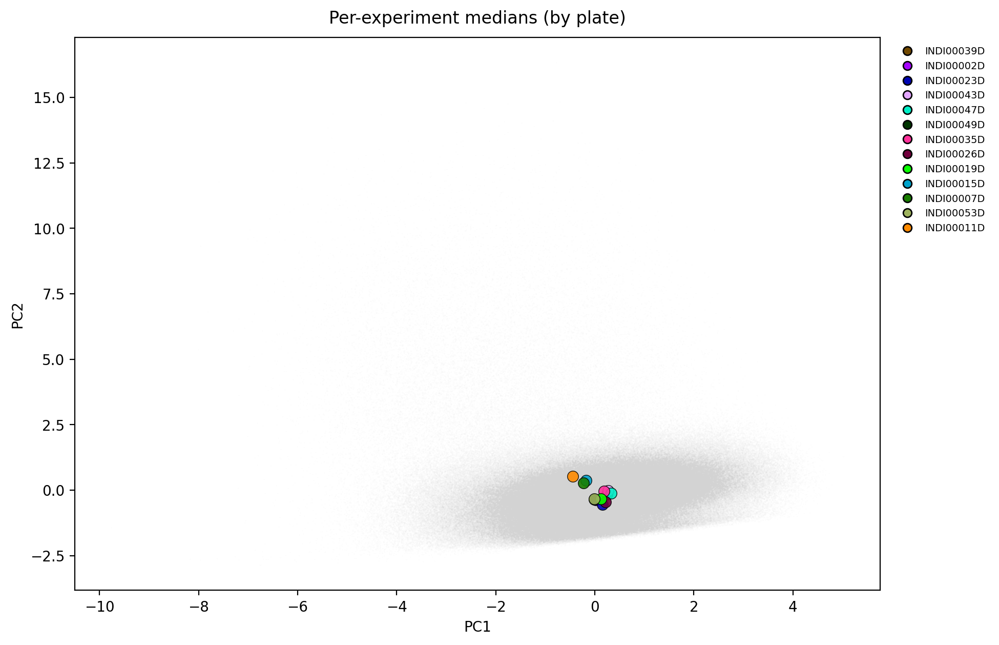

Std of per-experiment centroids (batch magnitude):
PC1    0.226
PC2    0.335
PC3    0.147
dtype: float64


In [51]:
# derive plate list from the data, not a hardcoded set
unique_plate_ids = sorted(df_auto["iNDI_Plate_ID"].dropna().unique())
print(f"{len(unique_plate_ids)} plates in this run:")
print(unique_plate_ids)

plate_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_plate_ids), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
colors_plates = [ListedColormap(plate_palette_raw)(i)
                 for i in range(len(plate_palette_raw))]
plate_palette = {pid: colors_plates[i] for i, pid in enumerate(unique_plate_ids)}

# glasbey palette for genotypes (high-cardinality, no fixed mapping)
geno_palette_raw = glasbey.create_palette(
    palette_size=64, hue_bounds=(0.0, 360.0), chroma_bounds=(40, 90)
)
geno_colors = [ListedColormap(geno_palette_raw)(i)
               for i in range(len(geno_palette_raw))]

def pca_scatter(df_auto, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = df_auto[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(df_auto.loc[m, pcx], df_auto.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()

unique_batches = sorted(df_auto["Batch"].dropna().unique())
batch_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_batches), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
batch_colors = [ListedColormap(batch_palette_raw)(i) for i in range(len(batch_palette_raw))]
batch_palette = {b: batch_colors[i] for i, b in enumerate(unique_batches)}

# guard: plates in data with no palette color
plates_in_data = set(df_auto["iNDI_Plate_ID"].dropna().unique())
missing = plates_in_data - set(plate_palette)
print(f"[warning] plates with no color: {sorted(missing)}" if missing
      else f"All {len(plates_in_data)} plates have a color.")

df_shuf = df_auto.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(df_shuf, "iNDI_Plate_ID", palette=plate_palette, figsize=(12, 7),
            title="Nuclei — iNDI_Plate_ID")
pca_scatter(df_shuf, "Batch", palette=batch_palette, figsize=(12, 7),
            title="Nuclei — Batch")
pca_scatter(df_shuf, "Asp PosID", figsize=(12, 7),
            title="Nuclei — Asp Pos ID")
pca_scatter(df_shuf, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
            title="Nuclei — Gene_Var_Type")

def centroid_overlay(df_auto, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = df_auto.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else df_auto
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = df_auto.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent

# per-experiment medians, colored by plate — spread = batch variation
centroid_overlay(df_auto, color_col="iNDI_Plate_ID", group_keys=["Measurement_ID"],
                 palette=plate_palette, title="Per-experiment medians (by plate)",
                 figsize=(12, 7))

# batch magnitude: std of per-experiment centroids (no Structure split now)
cent = df_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value
Source: 0 well(s) with >1 value



Image-level: 125124 rows (13440 images)
Well-level: 4154 rows
Well-level EVR: [0.419 0.303 0.169 0.077 0.029 0.004] | cumulative: [0.419 0.722 0.891 0.967 0.996 1.   ]


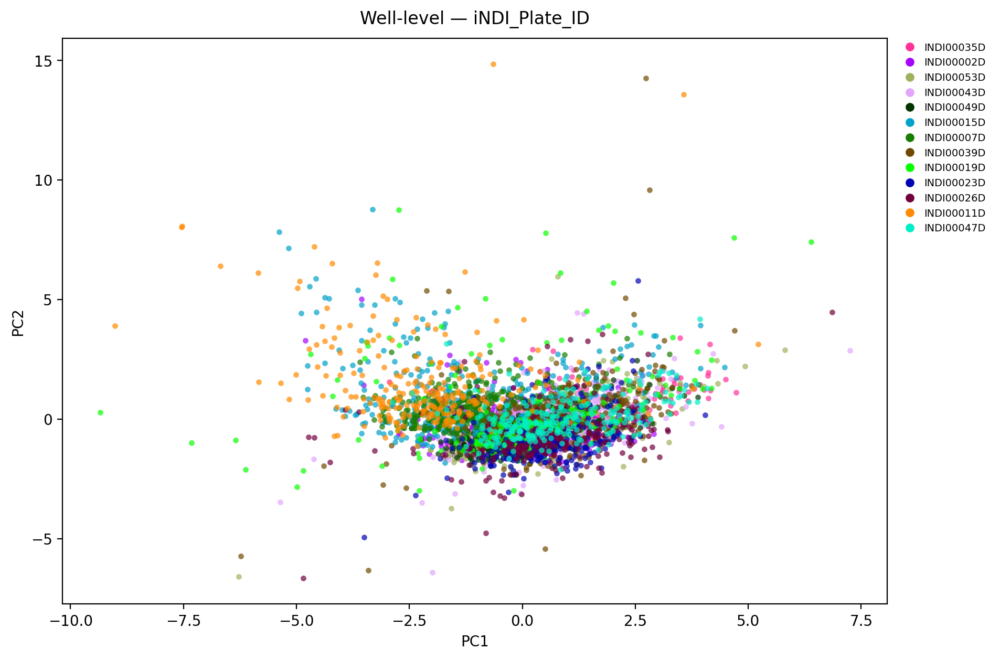

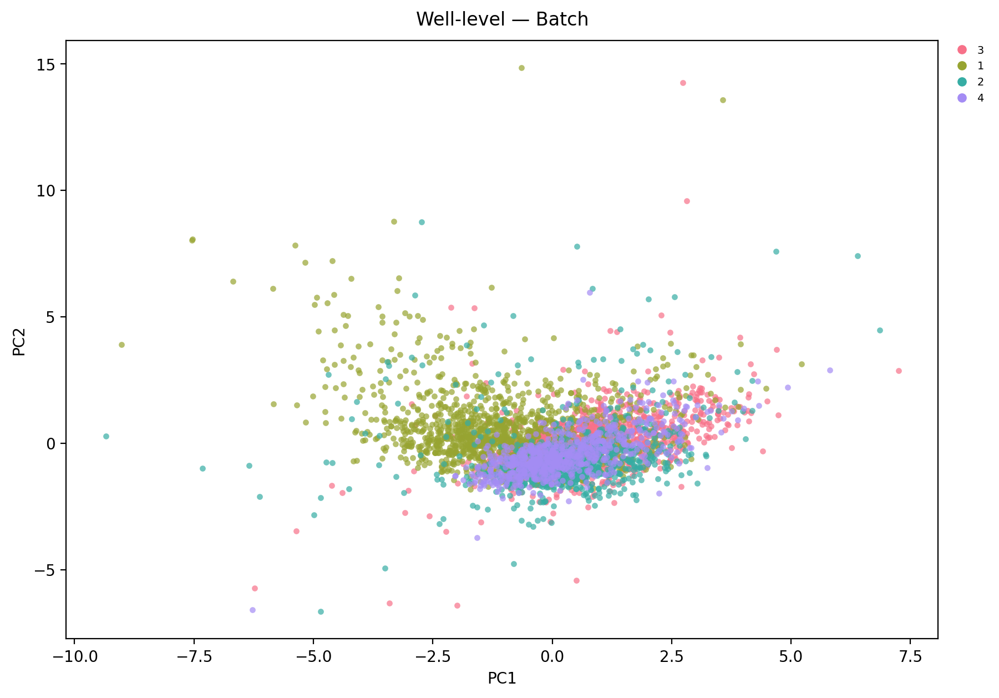

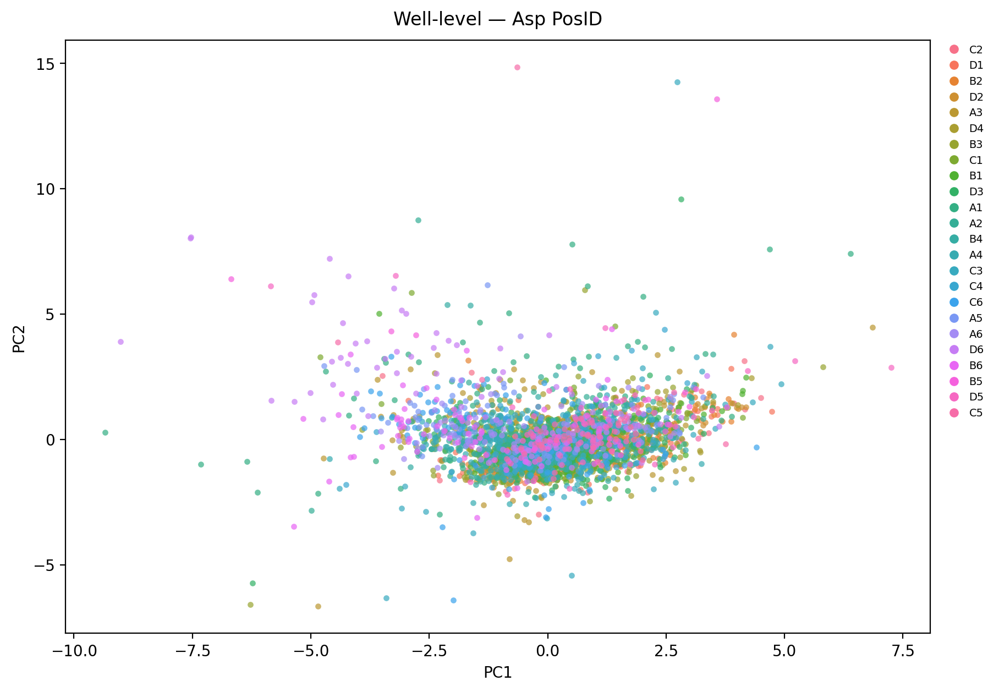

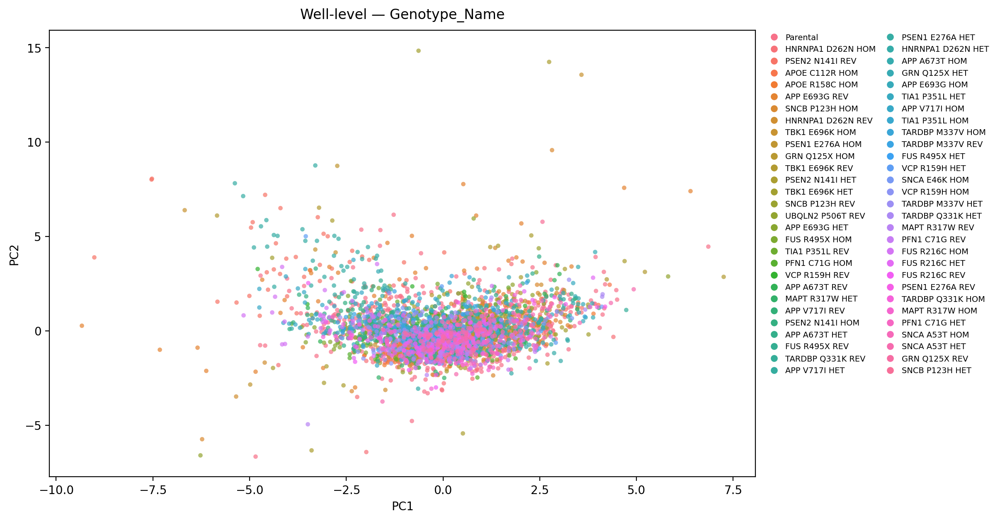

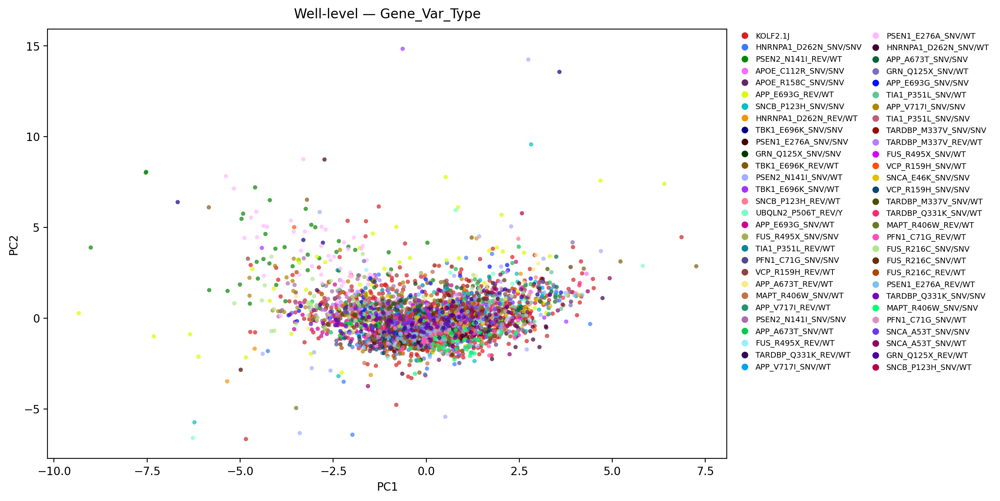

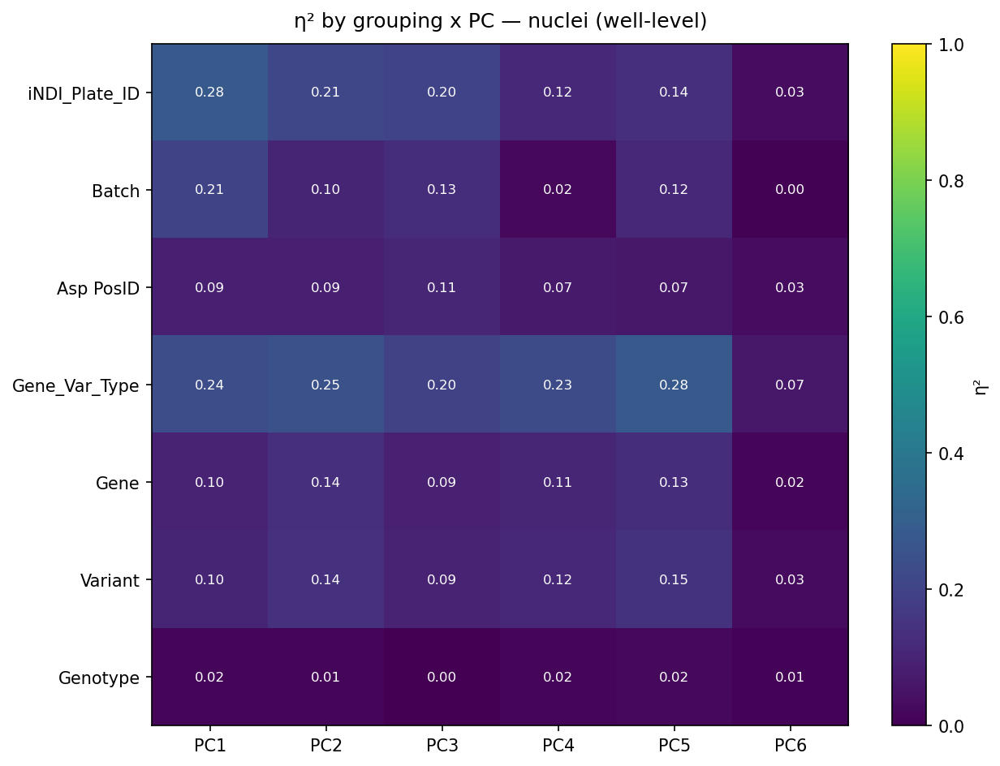

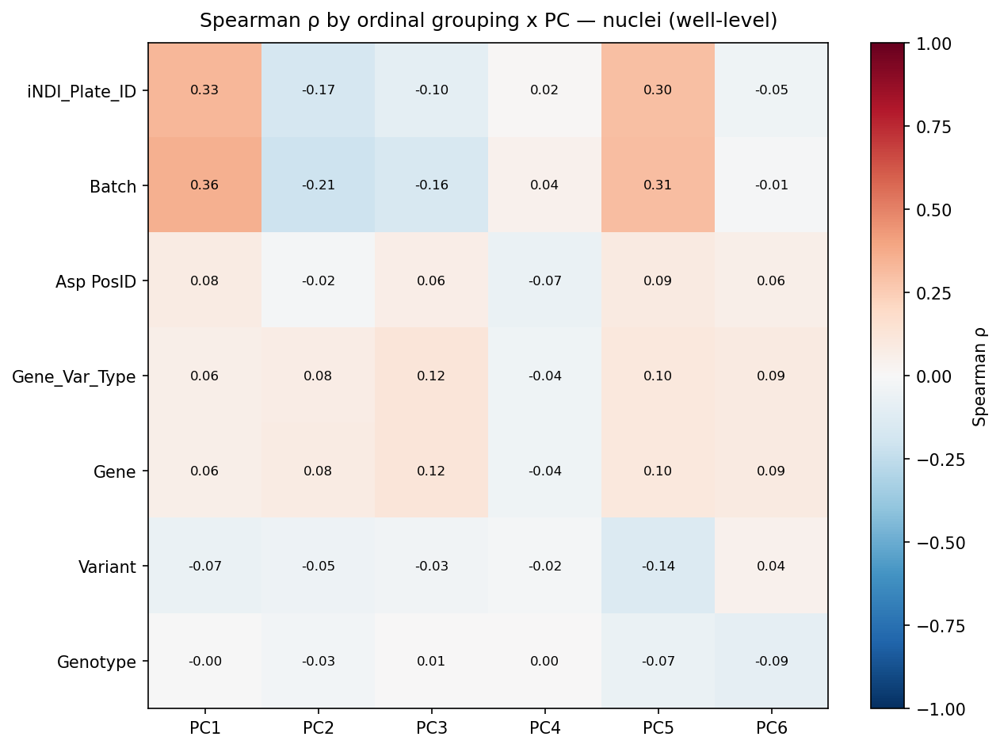

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.331660,-0.165171,-0.100937,0.015127,0.303769,-0.045807
Batch,0.358222,-0.209128,-0.159505,0.041349,0.309445,-0.008503
Asp PosID,0.083346,-0.017299,0.064619,-0.065926,0.086494,0.061944
Gene_Var_Type,0.060369,0.077803,0.117765,-0.044797,0.102392,0.087626
Gene,0.060725,0.080500,0.119249,-0.042219,0.104484,0.087492
Variant,-0.067306,-0.051222,-0.033685,-0.018892,-0.136157,0.043614
Genotype,-0.000823,-0.030584,0.007595,0.000466,-0.065270,-0.086745


In [53]:
# Nuclei keys: image = image_name, well = Measurement_ID + subdirectory.
# No Structure grouping.
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"

GROUP_KEYS = [*WELL_KEYS, IMAGE_KEY]
DROP_COLS = set(FEATURES) | {f"PC{i+1}" for i in range(20)} | set(GROUP_KEYS) \
            | {"label", "filename", "filepath"}
META_COLS = [c for c in df_auto.columns if c not in DROP_COLS]

# safety: metadata carried by .first() should be invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "Source"]:
    if col in df_auto.columns:
        n_bad = (df_auto.groupby(WELL_KEYS)[col].nunique() > 1).sum()
        print(f"{col}: {n_bad} well(s) with >1 value{'  <-- CHECK' if n_bad else ''}")

# stage 1: median across nuclei within each image
agg_image = {**{f: "median" for f in FEATURES}, **{m: "first" for m in META_COLS}}
image_level = df_auto.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows ({df_auto[IMAGE_KEY].nunique()} images)")

# stage 2: mean across images within each well
agg_well = {**{f: "mean" for f in FEATURES}, **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_KEYS, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows")

# refit PCA on well-level profiles
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
Xw = StandardScaler().fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(scores_w.shape[1]):
    well_level[f"PC{i+1}"] = scores_w[:, i]
evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw.round(3), "| cumulative:", np.cumsum(evw).round(3))

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

## Manual analysis
### Feature assessment and loadings

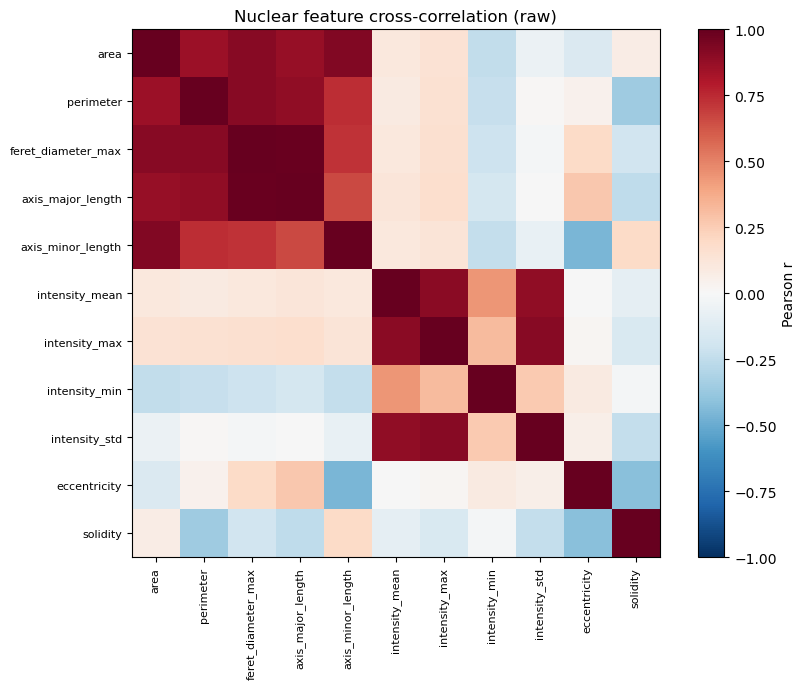

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.926  area                   axis_minor_length
  +0.911  perimeter              feret_diameter_max
  +0.909  area                   feret_diameter_max
  +0.907  intensity_max          intensity_std
  +0.901  intensity_mean         intensity_max

Using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']


/tmp/ipykernel_1676947/4013341410.py:45: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_manual["aspect_ratio"] = df_manual["axis_minor_length"] / df_manual["axis_major_length"]


Dropped 0 rows with NaN/inf; 1046112 remain


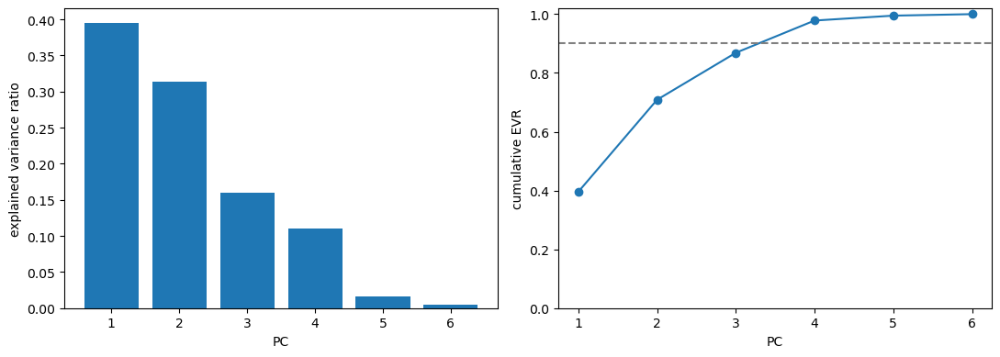

EVR: [0.396 0.313 0.16  0.11  0.017 0.005]
cumulative: [0.396 0.709 0.869 0.978 0.995 1.   ]
                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.201  0.053  0.961 -0.139  0.119  0.015
intensity_mean -0.085  0.697  0.087  0.153 -0.690 -0.010
intensity_std  -0.167  0.683 -0.086  0.026  0.705  0.015
eccentricity   -0.593 -0.155  0.171  0.340  0.003  0.692
solidity        0.451 -0.033  0.023  0.883  0.111 -0.060
aspect_ratio    0.607  0.141 -0.179 -0.249 -0.021  0.719


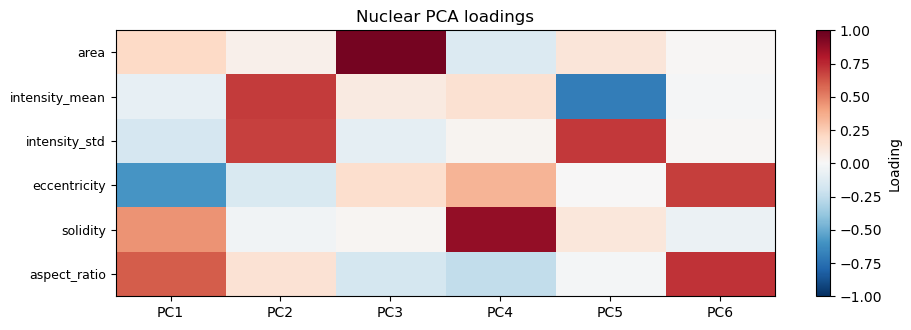

In [54]:
df_manual = df[df["Source"] == "manual"]

# ---------------------------------------------------------------
# STEP 0 — candidate nuclear features (regionprops from script 1)
# ---------------------------------------------------------------
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c in df_manual.columns]

# ---------------------------------------------------------------
# STEP 1 — cross-correlation (raw, pre-scaling)
# ---------------------------------------------------------------
X_all = df_manual[CANDIDATE_FEATURES].replace([np.inf, -np.inf], np.nan)
corr = X_all.corr(method="pearson")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, rotation=90, fontsize=8)
plt.yticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, fontsize=8)
plt.colorbar(im, label="Pearson r")
plt.title("Nuclear feature cross-correlation (raw)")
plt.tight_layout(); plt.show()

hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(CANDIDATE_FEATURES)
    for b in CANDIDATE_FEATURES[i + 1:]
    if hi.loc[a, b]
]
print("Highly correlated pairs (|r| > 0.9):")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {r:+.3f}  {a:22s} {b}")

# ---------------------------------------------------------------
# STEP 2 — pruned FEATURES
# ---------------------------------------------------------------
df_manual["aspect_ratio"] = df_manual["axis_minor_length"] / df_manual["axis_major_length"]

FEATURES = [
    "area",
    "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]
FEATURES = [c for c in FEATURES if c in df_manual.columns]
print("\nUsing FEATURES:", FEATURES)

# ---------------------------------------------------------------
# NaN/inf handling
# ---------------------------------------------------------------
before = len(df)
X_df = df[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
df = df[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with NaN/inf; {len(df)} remain")

# ---------------------------------------------------------------
# scale + PCA
# ---------------------------------------------------------------
X = StandardScaler().fit_transform(X_df.values)
pca = PCA(n_components=len(FEATURES))
scores = pca.fit_transform(X)
for i in range(scores.shape[1]):
    df[f"PC{i+1}"] = scores[:, i]

# scree
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev) + 1), ev)
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print("EVR:", ev.round(3))
print("cumulative:", np.cumsum(ev).round(3))

# loadings
loadings = pd.DataFrame(
    pca.components_.T, index=FEATURES,
    columns=[f"PC{i+1}" for i in range(len(FEATURES))],
)
print(loadings.round(3))

n_show = min(6, len(FEATURES))
plt.figure(figsize=(1.6 * n_show, 0.4 * len(FEATURES) + 1))
im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=9)
plt.colorbar(im, label="Loading")
plt.title("Nuclear PCA loadings")
plt.tight_layout(); plt.show()

### PCA plots - ROI-level

8 plates in this run:
['INDIEC006', 'INDIEC007', 'INDIEL001', 'INDIEL002', 'INDIEL003', 'INDIMS004', 'INDIMS005', 'INDIRK008']
All 8 plates have a color.


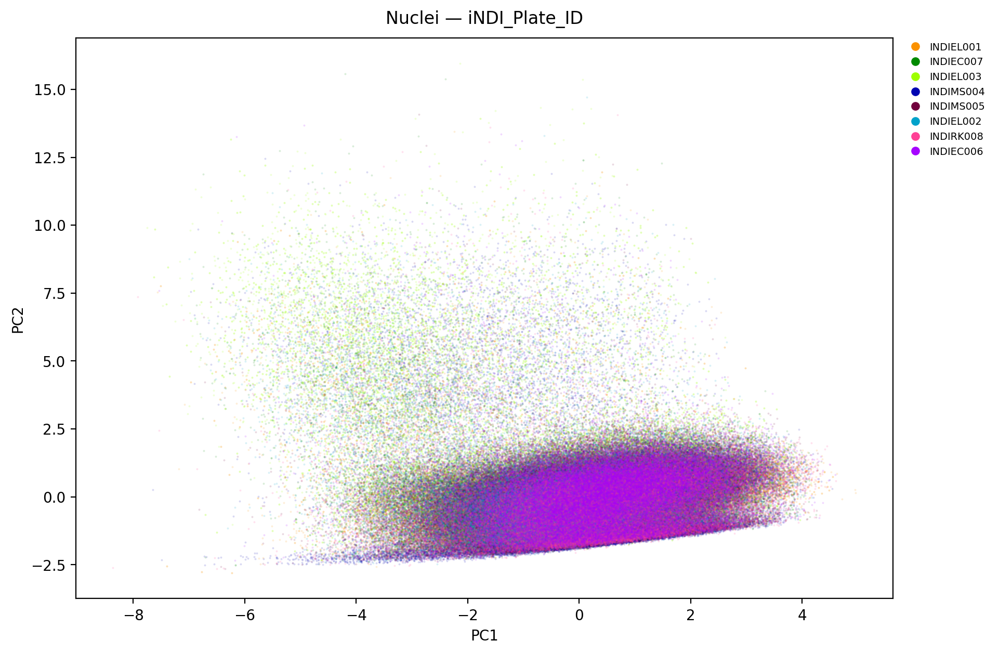

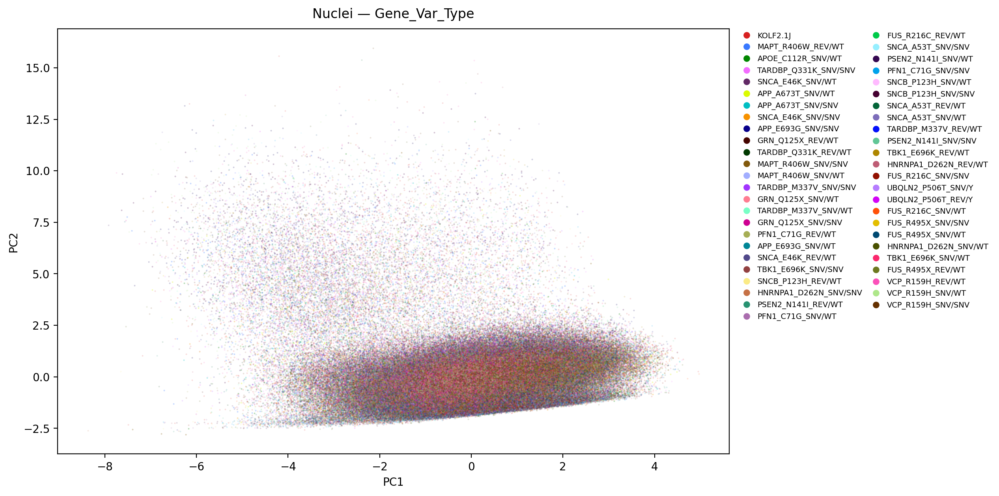

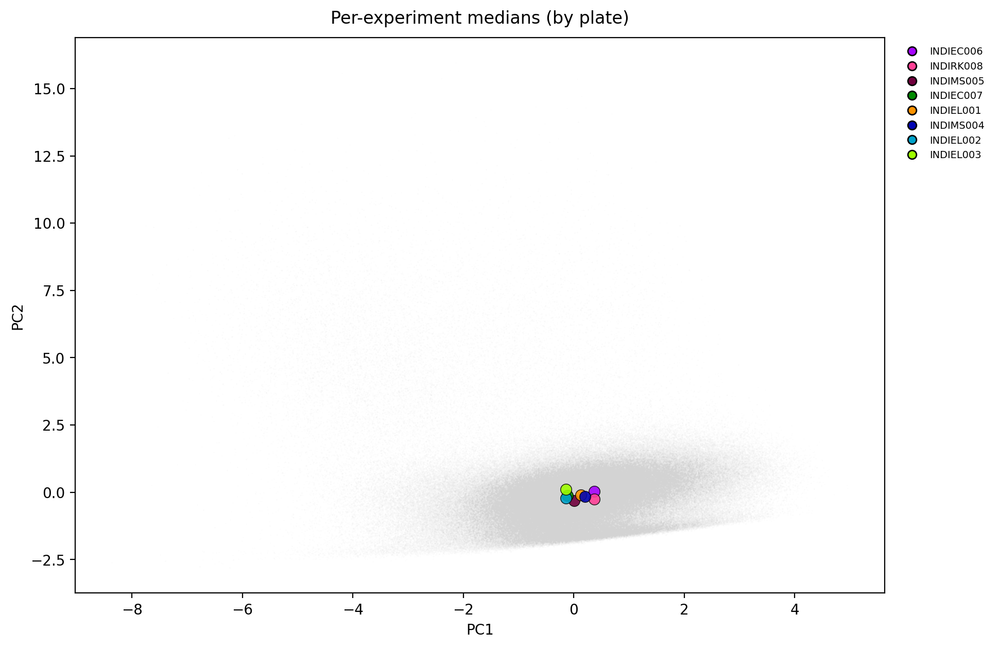

Std of per-experiment centroids (batch magnitude):
PC1    0.217
PC2    0.140
PC3    0.159
dtype: float64


In [58]:
# derive plate list from the data, not a hardcoded set
unique_plate_ids = sorted(df_manual["iNDI_Plate_ID"].dropna().unique())
print(f"{len(unique_plate_ids)} plates in this run:")
print(unique_plate_ids)

plate_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_plate_ids), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
colors_plates = [ListedColormap(plate_palette_raw)(i)
                 for i in range(len(plate_palette_raw))]
plate_palette = {pid: colors_plates[i] for i, pid in enumerate(unique_plate_ids)}

# glasbey palette for genotypes (high-cardinality, no fixed mapping)
geno_palette_raw = glasbey.create_palette(
    palette_size=64, hue_bounds=(0.0, 360.0), chroma_bounds=(40, 90)
)
geno_colors = [ListedColormap(geno_palette_raw)(i)
               for i in range(len(geno_palette_raw))]

def pca_scatter(df_manual, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = df_manual[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(df_manual.loc[m, pcx], df_manual.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()

unique_batches = sorted(df_manual["Batch"].dropna().unique())
batch_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_batches), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
batch_colors = [ListedColormap(batch_palette_raw)(i) for i in range(len(batch_palette_raw))]
batch_palette = {b: batch_colors[i] for i, b in enumerate(unique_batches)}

# guard: plates in data with no palette color
plates_in_data = set(df_manual["iNDI_Plate_ID"].dropna().unique())
missing = plates_in_data - set(plate_palette)
print(f"[warning] plates with no color: {sorted(missing)}" if missing
      else f"All {len(plates_in_data)} plates have a color.")

df_shuf = df_manual.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(df_shuf, "iNDI_Plate_ID", palette=plate_palette, figsize=(12, 7),
            title="Nuclei — iNDI_Plate_ID")
pca_scatter(df_shuf, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
            title="Nuclei — Gene_Var_Type")

def centroid_overlay(df_manual, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = df_manual.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else df_manual
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = df_manual.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent

# per-experiment medians, colored by plate — spread = batch variation
centroid_overlay(df_manual, color_col="iNDI_Plate_ID", group_keys=["Measurement_ID"],
                 palette=plate_palette, title="Per-experiment medians (by plate)",
                 figsize=(12, 7))

# batch magnitude: std of per-experiment centroids (no Structure split now)
cent = df_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value
Source: 0 well(s) with >1 value

Image-level: 74704 rows (11755 images)
Well-level: 2198 rows
Well-level EVR: [0.455 0.269 0.126 0.116 0.032 0.002] | cumulative: [0.455 0.724 0.85  0.966 0.998 1.   ]


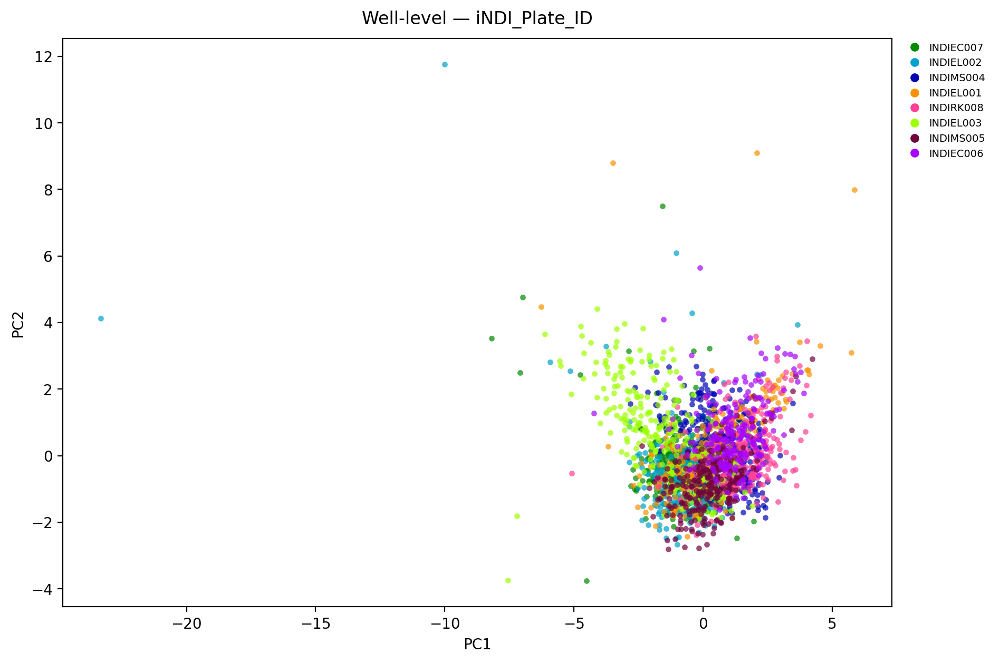

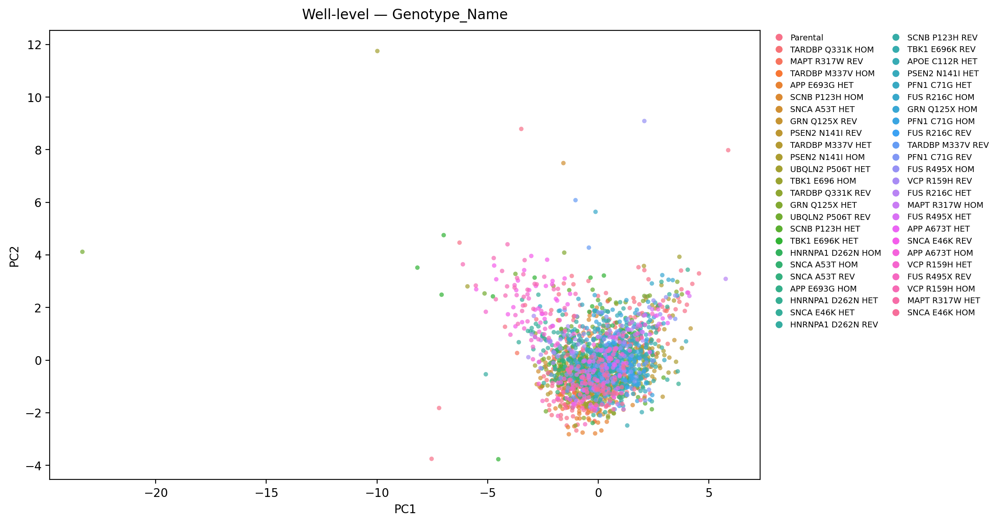

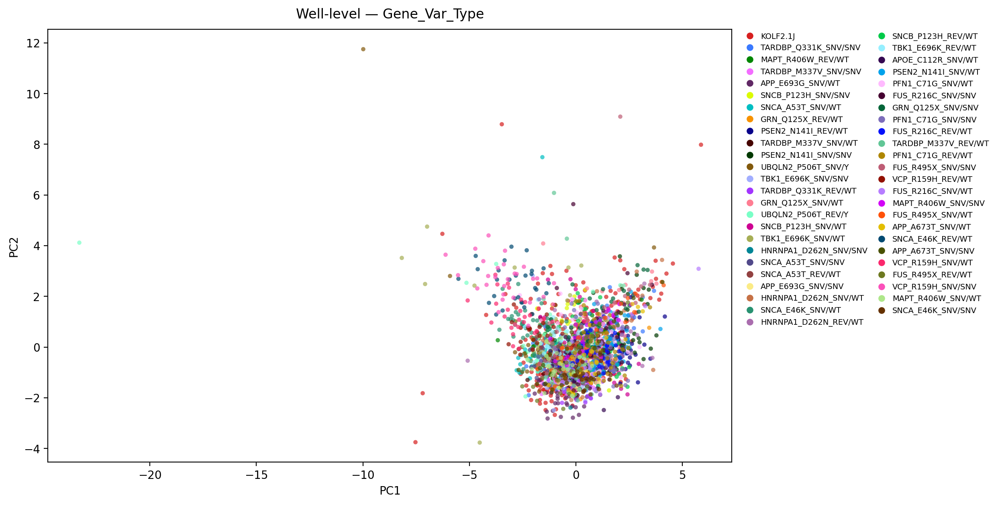

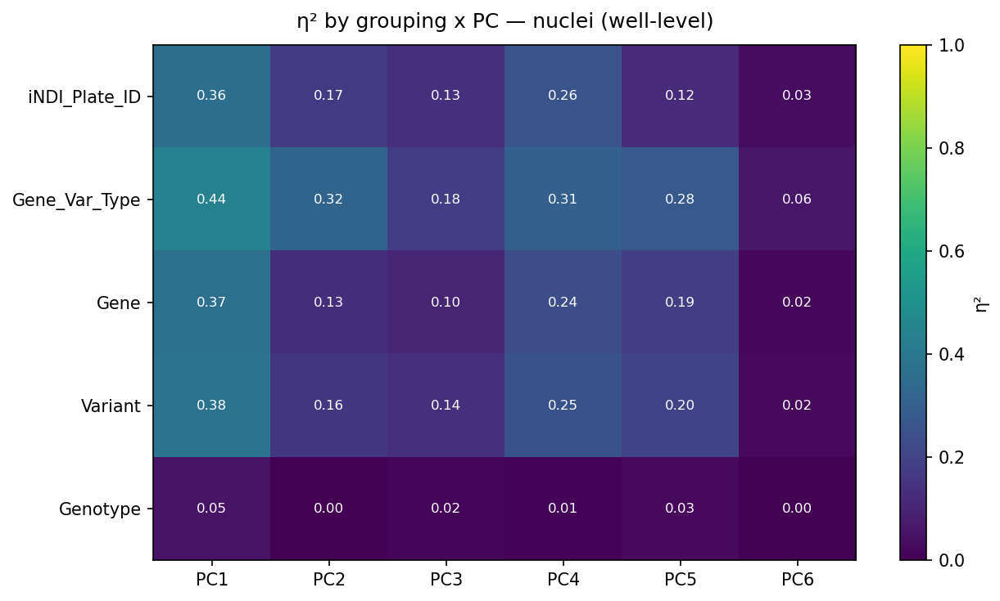

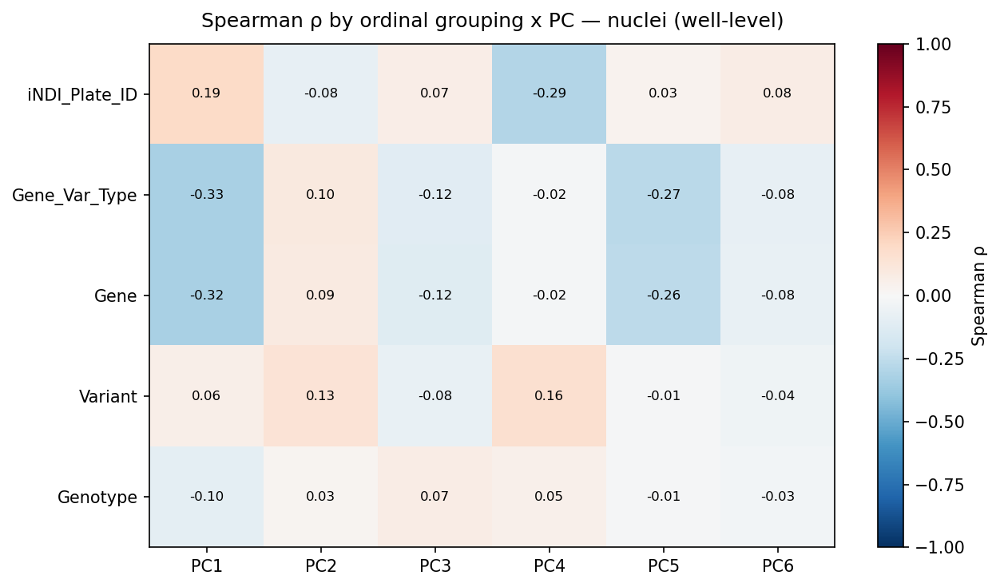

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.194932,-0.082538,0.069955,-0.291239,0.033804,0.075289
Gene_Var_Type,-0.325092,0.100536,-0.115670,-0.023102,-0.267605,-0.079039
Gene,-0.322551,0.090771,-0.119222,-0.021989,-0.262195,-0.077146
Variant,0.056824,0.133146,-0.077169,0.157372,-0.014015,-0.041150
Genotype,-0.100487,0.025777,0.074176,0.053235,-0.013406,-0.028139


In [61]:
# Nuclei keys: image = image_name, well = Measurement_ID + subdirectory.
# No Structure grouping.
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"

GROUP_KEYS = [*WELL_KEYS, IMAGE_KEY]
DROP_COLS = set(FEATURES) | {f"PC{i+1}" for i in range(20)} | set(GROUP_KEYS) \
            | {"label", "filename", "filepath"}
META_COLS = [c for c in df_manual.columns if c not in DROP_COLS]

# safety: metadata carried by .first() should be invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "Source"]:
    if col in df_manual.columns:
        n_bad = (df_manual.groupby(WELL_KEYS)[col].nunique() > 1).sum()
        print(f"{col}: {n_bad} well(s) with >1 value{'  <-- CHECK' if n_bad else ''}")

# stage 1: median across nuclei within each image
agg_image = {**{f: "median" for f in FEATURES}, **{m: "first" for m in META_COLS}}
image_level = df_manual.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows ({df_manual[IMAGE_KEY].nunique()} images)")

# stage 2: mean across images within each well
agg_well = {**{f: "mean" for f in FEATURES}, **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_KEYS, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows")

# refit PCA on well-level profiles
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
Xw = StandardScaler().fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(scores_w.shape[1]):
    well_level[f"PC{i+1}"] = scores_w[:, i]
evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw.round(3), "| cumulative:", np.cumsum(evw).round(3))

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

# Genotype faceted PCAs


MANUAL (0 wells)

AUTOMATED (4154 wells)


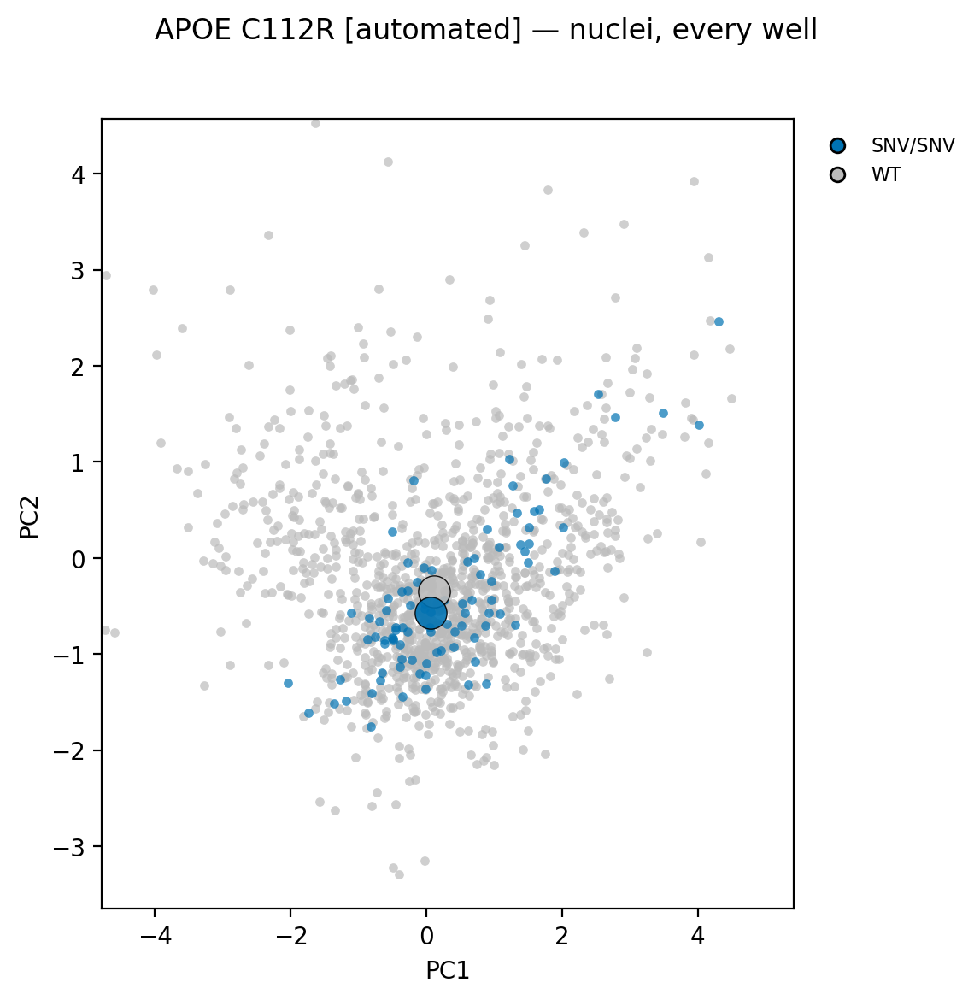

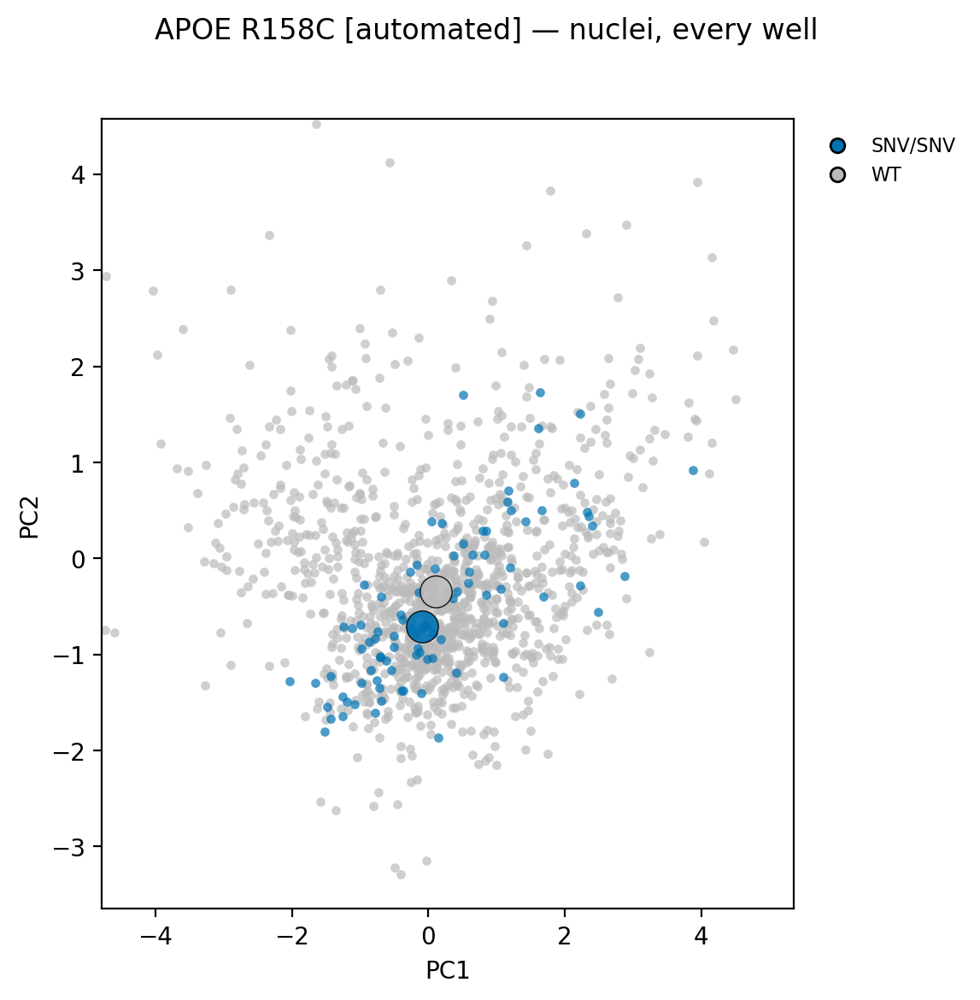

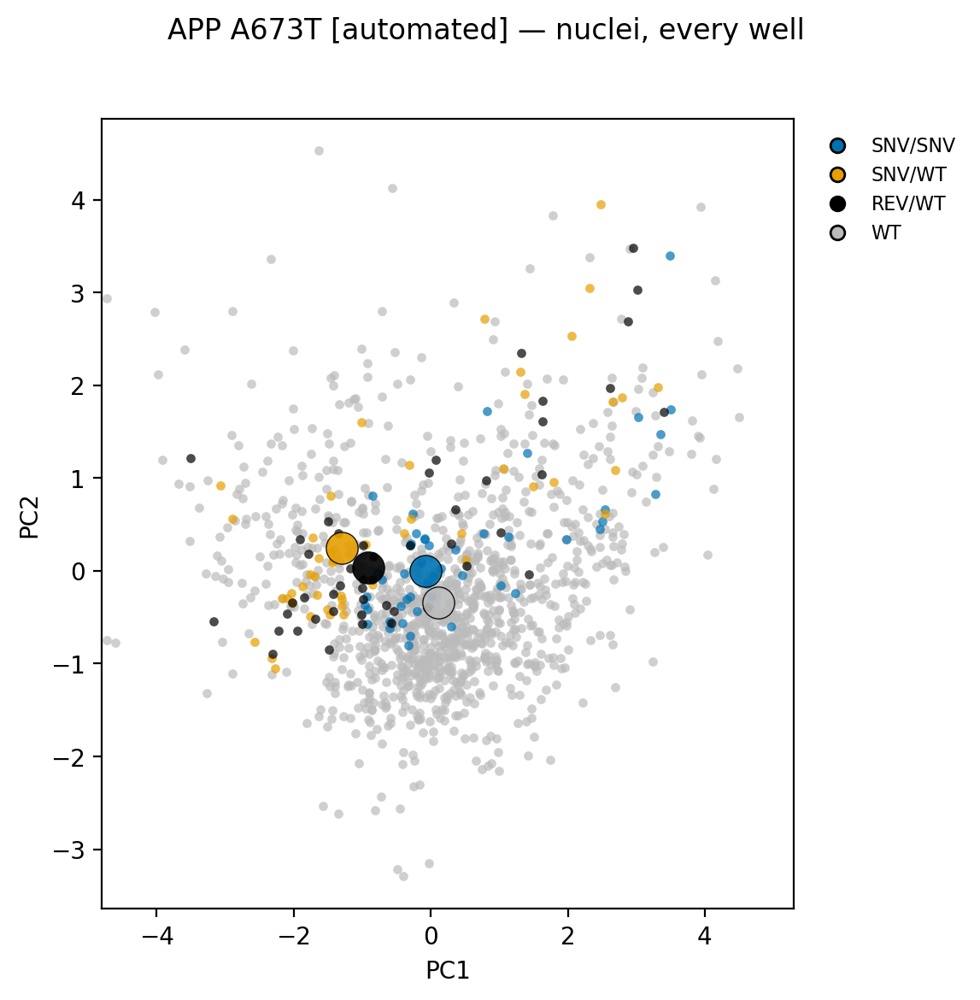

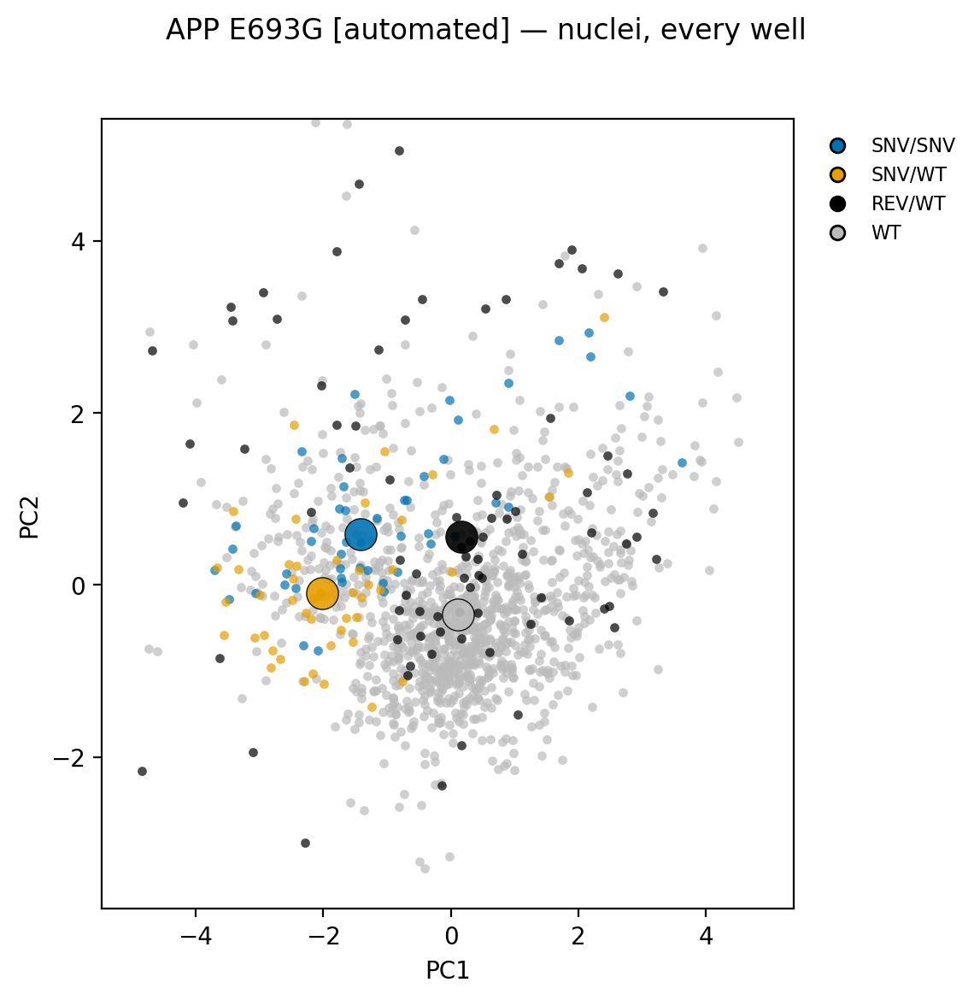

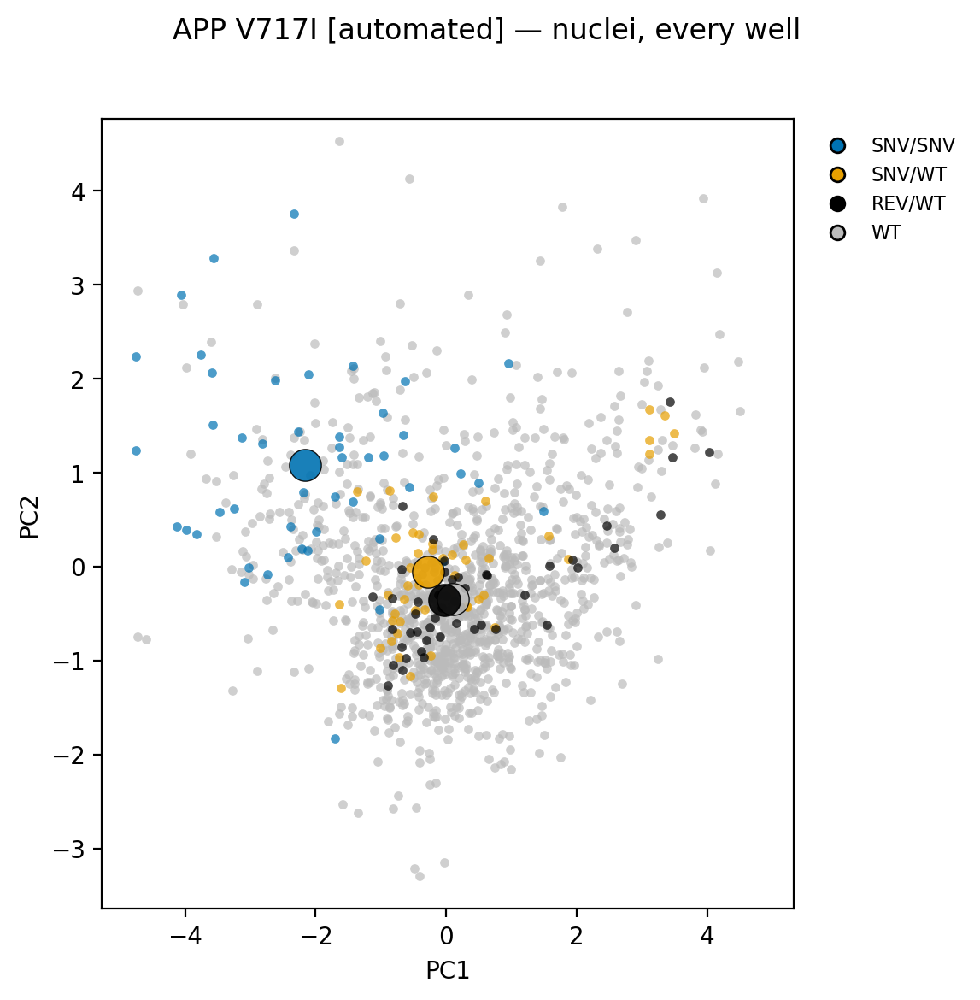

...

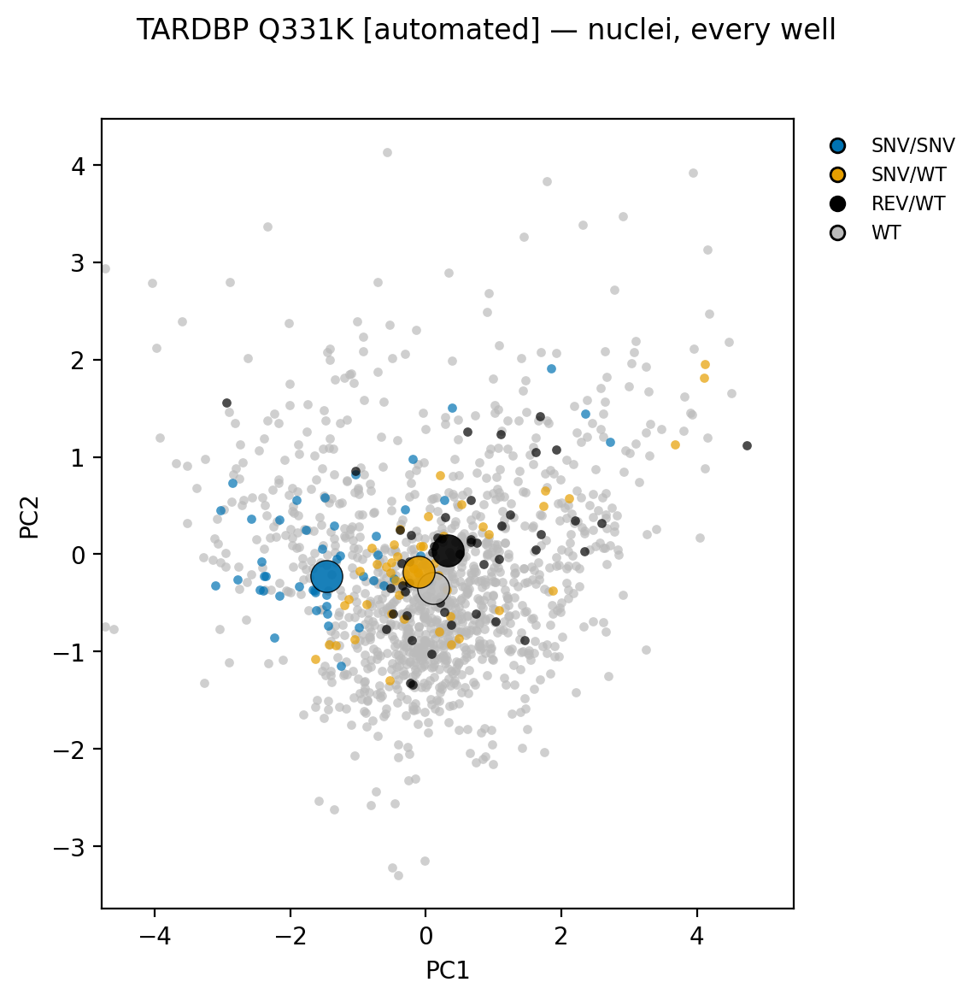

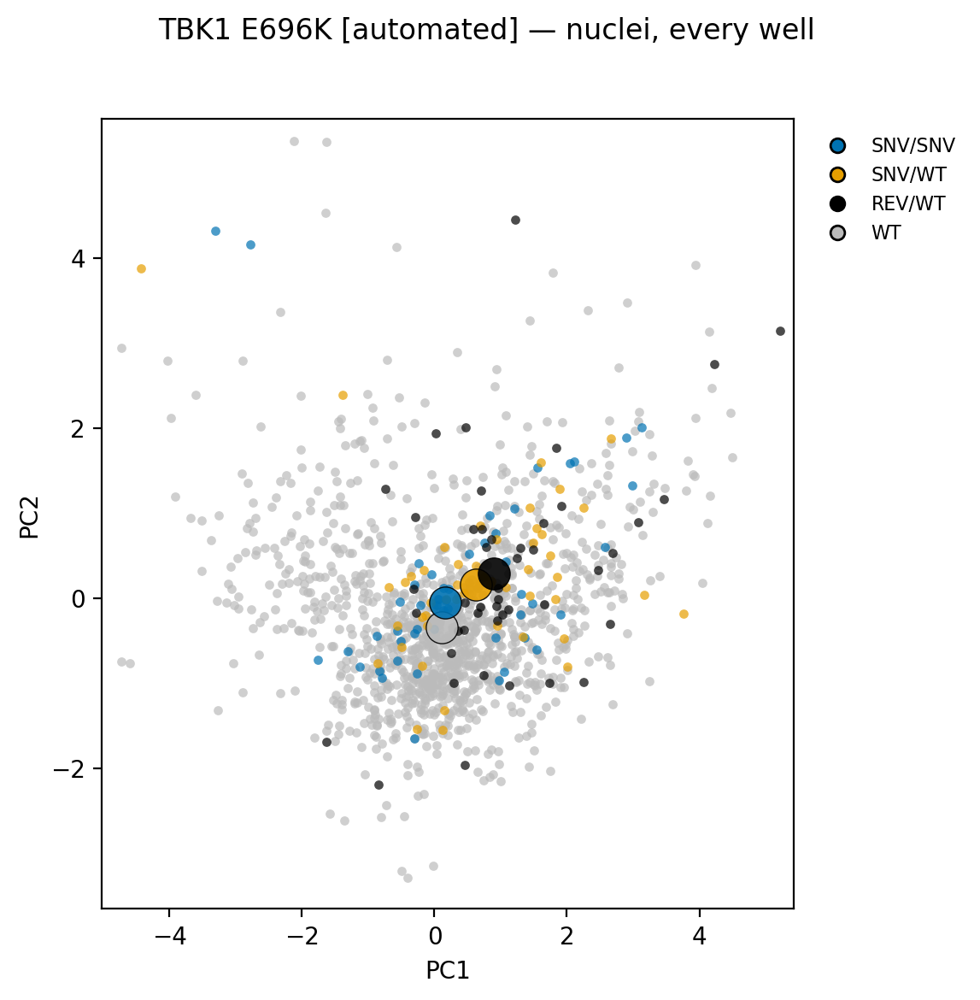

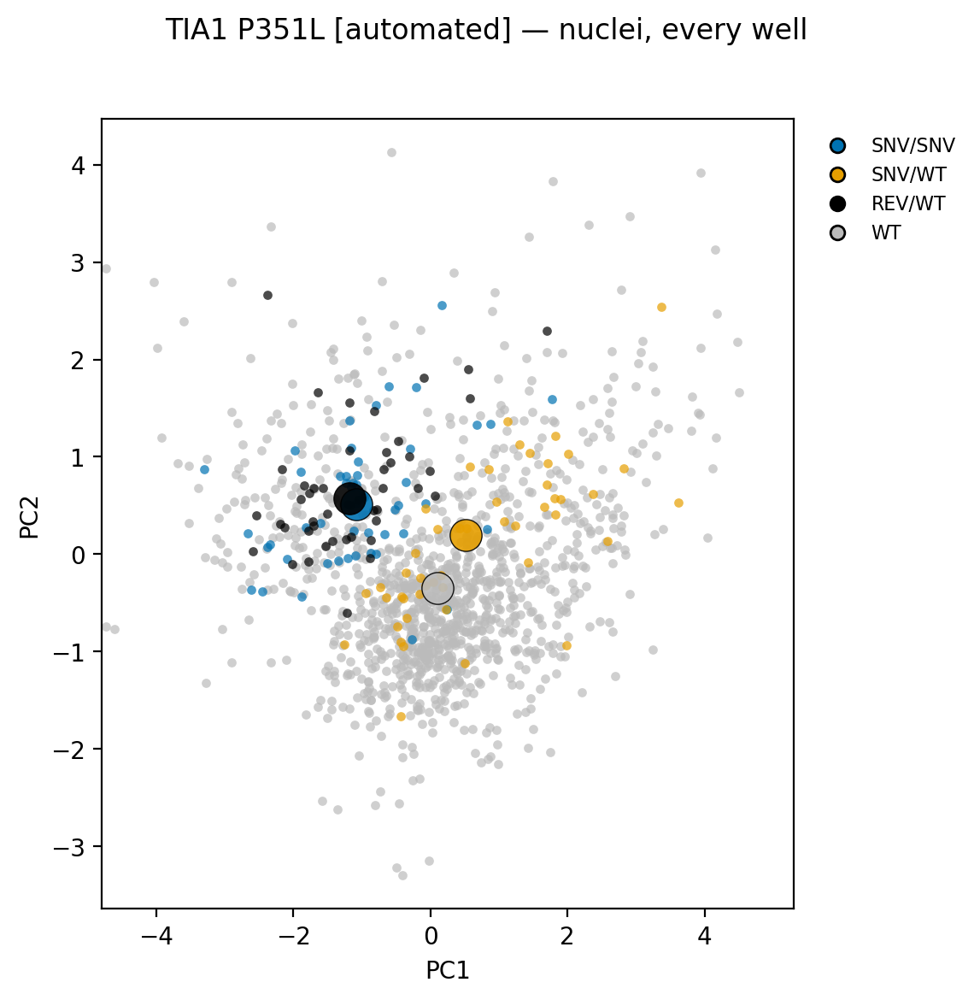

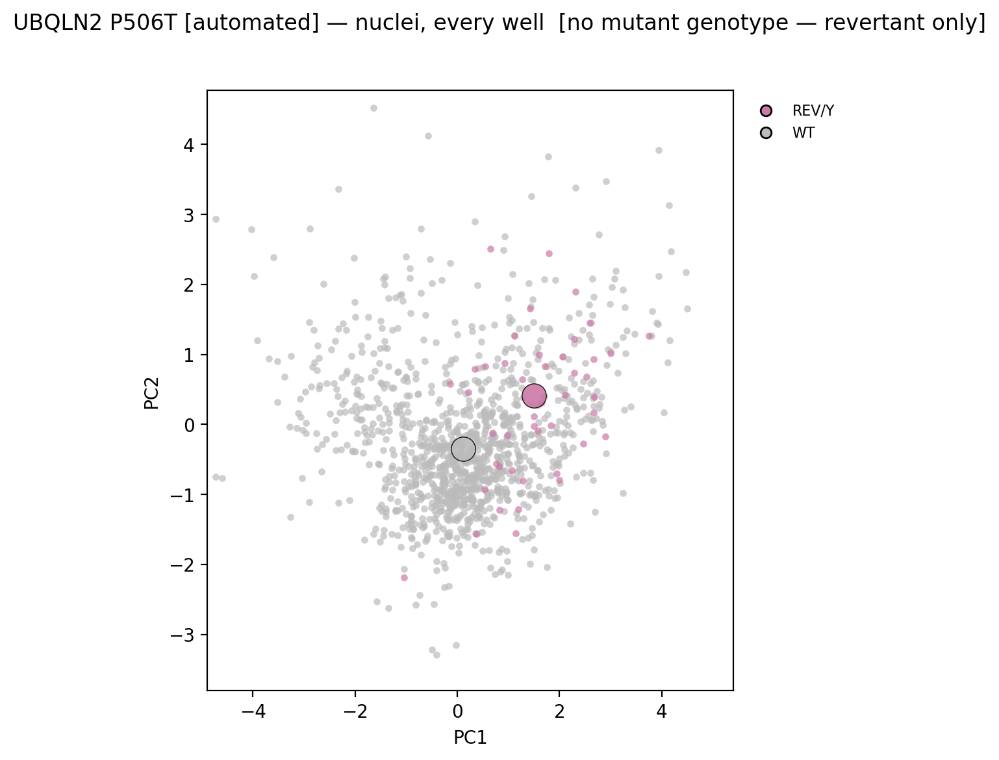

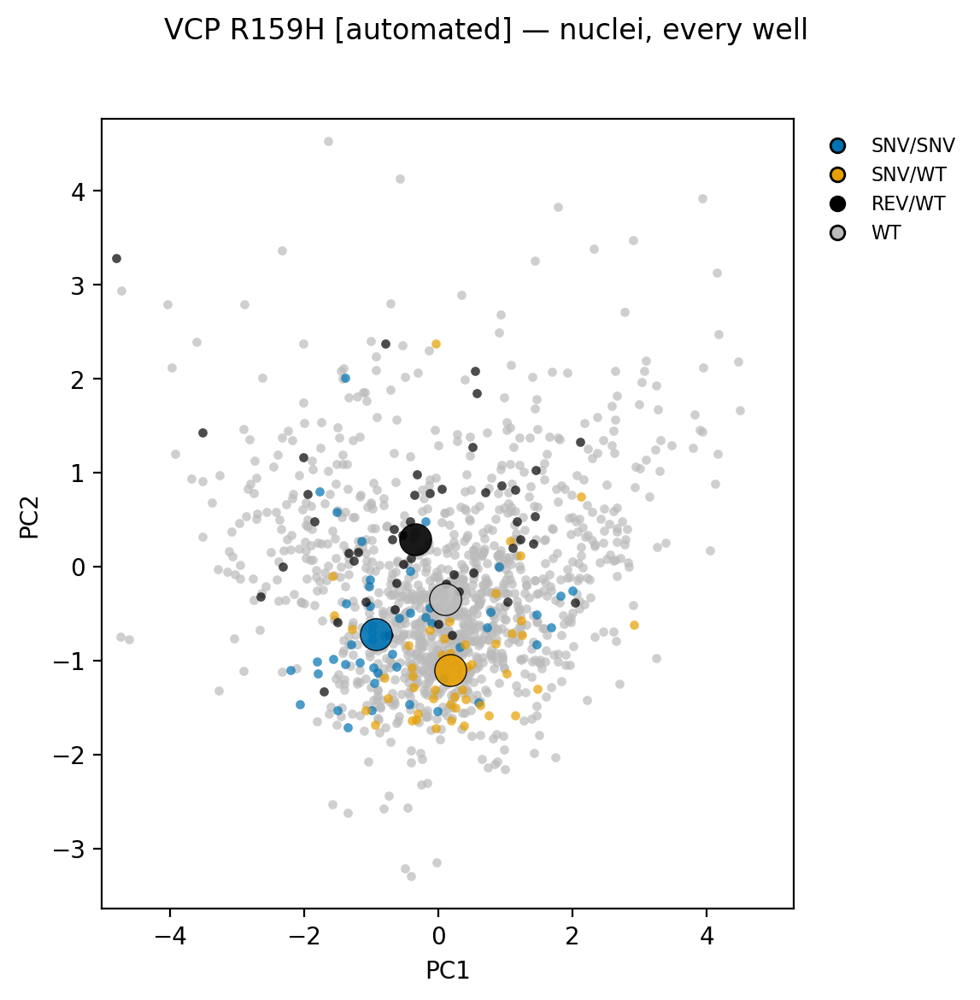

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "Source"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — nuclei, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)


well_df = well_level

# Manual-only fixup from the previous manual driver.
well_df.loc[
    well_df["Genotype_Name"].astype(str).str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

prep = well_df[PREP_COL].astype(str).str.strip().str.lower()

run_group(well_df[prep == MANUAL_VAL.lower()].copy(),    SCHEMES["manual"])
run_group(well_df[prep == AUTOMATED_VAL.lower()].copy(), SCHEMES["automated"])

# Parental-only analysis

In [56]:
# filter for parentals

## ROI level analysis
### Feature assessment
### PCA loadings
### PCA plots
### Variance component analysis (?)
## Well-level aggregation
### PCA plots
### Variance component analysis (?)